In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/CAMUS_FINAL")

PHASE5_ROOT = PROJECT_ROOT / "phase5_application"

PHASE5E_ROOT = (
    PHASE5_ROOT / "phase5E_quality_and_interpretation"
)

ANALYSIS_DIR = PHASE5E_ROOT / "analysis"
APP_DIR = PHASE5E_ROOT / "app"
SCREENSHOT_DIR = PHASE5E_ROOT / "screenshots"
VERIFICATION_DIR = PHASE5E_ROOT / "verification"
REPORT_DIR = PHASE5E_ROOT / "reports"

for folder in [
    ANALYSIS_DIR,
    APP_DIR,
    SCREENSHOT_DIR,
    VERIFICATION_DIR,
    REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

assert PROJECT_ROOT.exists(), "Project folder not found."

assert (
    PHASE5_ROOT / "PHASE5_COMPLETE.json"
).exists(), "Phase 5 completion record not found."

print("=" * 70)
print("PHASE 5E — QUALITY ASSESSMENT AND APPLICATION IMPROVEMENTS")
print("=" * 70)

print("Project:", PROJECT_ROOT)
print("Phase 5E:", PHASE5E_ROOT)
print("Previous Phase 5 completion record: FOUND")
print("\n✓ Phase 5E workspace ready.")

Mounted at /content/drive
PHASE 5E — QUALITY ASSESSMENT AND APPLICATION IMPROVEMENTS
Project: /content/drive/MyDrive/CAMUS_FINAL
Phase 5E: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation
Previous Phase 5 completion record: FOUND

✓ Phase 5E workspace ready.


In [ ]:
import pandas as pd
import numpy as np

PHASE2_RESULTS = (
    PROJECT_ROOT
    / "phase2_quantitative"
    / "phase2B_final_evaluation"
    / "tables"
    / "final_test_quantitative_measurements.csv"
)

assert PHASE2_RESULTS.exists(), (
    f"Frozen quantitative results not found: {PHASE2_RESULTS}"
)

df = pd.read_csv(PHASE2_RESULTS)

print("=" * 70)
print("FROZEN PATIENT-LEVEL RESULTS")
print("=" * 70)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nFirst three records:")
display(df.head(3))

print("\nUnique patients:",
      df["patient_id"].nunique()
      if "patient_id" in df.columns
      else "Patient identifier column not identified")

print("\n✓ Frozen results loaded.")

FROZEN PATIENT-LEVEL RESULTS
Dataset shape: (50, 21)

Available columns:
01. patient_id
02. reference_EF_pct
03. image_quality
04. age
05. sex
06. ED_GT_area_mm2
07. ED_PRED_area_mm2
08. ED_GT_length_mm
09. ED_PRED_length_mm
10. ED_GT_volume_ml
11. ED_PRED_volume_ml
12. ES_GT_area_mm2
13. ES_PRED_area_mm2
14. ES_GT_length_mm
15. ES_PRED_length_mm
16. ES_GT_volume_ml
17. ES_PRED_volume_ml
18. GT_SV_ml
19. GT_EF_pct
20. PRED_SV_ml
21. PRED_EF_pct

First three records:


,patient_id,reference_EF_pct,image_quality,age,sex,ED_GT_area_mm2,ED_PRED_area_mm2,ED_GT_length_mm,ED_PRED_length_mm,ED_GT_volume_ml,...,ES_GT_area_mm2,ES_PRED_area_mm2,ES_GT_length_mm,ES_PRED_length_mm,ES_GT_volume_ml,ES_PRED_volume_ml,GT_SV_ml,GT_EF_pct,PRED_SV_ml,PRED_EF_pct
0,patient0173,59.0,Good,57,M,2855.499180,2714.265708,77.659494,78.143962,89.122710,...,1612.311326,1520.238767,66.082047,62.295982,33.391289,31.490708,55.731421,62.533356,48.534747,60.649136
1,patient0391,35.0,Good,46,F,1524.992144,1715.459785,59.292864,62.373792,33.292901,...,1149.999203,1416.779002,56.073765,55.598361,20.019546,30.645103,13.273356,39.868425,9.402616,23.478531
2,patient0111,43.0,Medium,53,M,2885.189635,2603.580738,74.982090,75.924522,94.234525,...,1884.176499,1513.588657,62.372586,53.419584,48.313475,36.402741,45.921050,48.730601,39.381498,51.965288



Unique patients: 50

✓ Frozen results loaded.


In [ ]:
print("=" * 70)
print("REFERENCE EF AND IMAGE QUALITY INSPECTION")
print("=" * 70)

ef_columns = [
    c for c in df.columns
    if "ef" in c.lower()
]

quality_columns = [
    c for c in df.columns
    if "quality" in c.lower()
]

class_columns = [
    c for c in df.columns
    if any(term in c.lower()
           for term in ["class", "band", "label"])
]

print("\nEF-related columns:")
print(ef_columns)

print("\nImage-quality columns:")
print(quality_columns)

print("\nClassification-related columns:")
print(class_columns)

selected_columns = (
    ["patient_id"]
    + ef_columns
    + quality_columns
    + class_columns
)

selected_columns = list(dict.fromkeys(
    c for c in selected_columns if c in df.columns
))

print("\nAvailable patient-level information:")
display(df[selected_columns].head(10))

for column in quality_columns:
    print(f"\nQuality distribution — {column}:")
    print(df[column].value_counts(dropna=False))

print("\n✓ Dataset information inspected.")

REFERENCE EF AND IMAGE QUALITY INSPECTION

EF-related columns:
['reference_EF_pct', 'GT_EF_pct', 'PRED_EF_pct']

Image-quality columns:
['image_quality']

Classification-related columns:
[]

Available patient-level information:


,patient_id,reference_EF_pct,GT_EF_pct,PRED_EF_pct,image_quality
0,patient0173,59.0,62.533356,60.649136,Good
1,patient0391,35.0,39.868425,23.478531,Good
2,patient0111,43.0,48.730601,51.965288,Medium
3,patient0080,60.0,65.829041,61.926171,Good
4,patient0465,45.0,53.044190,63.436843,Medium
5,patient0175,45.0,57.385194,61.819178,Medium
6,patient0484,31.0,25.511473,23.379442,Poor
7,patient0358,44.0,47.491380,29.435975,Poor
8,patient0082,54.0,48.530715,60.826023,Good
9,patient0413,57.0,63.073134,62.174191,Good



Quality distribution — image_quality:
image_quality
Good      30
Medium    13
Poor       7
Name: count, dtype: int64

✓ Dataset information inspected.


In [ ]:
# ================================================================
# PHASE 5E — CELL 4
# REFERENCE EF GROUPS AND ERROR ANALYSIS
# ================================================================

import numpy as np
import pandas as pd

analysis_df = df.copy()

def ef_band(ef):
    if pd.isna(ef):
        return "Unknown"
    if ef <= 40:
        return "Lower_EF"
    elif ef < 50:
        return "Intermediate_EF"
    return "Higher_EF"

analysis_df["reference_band"] = (
    analysis_df["reference_EF_pct"].apply(ef_band)
)

analysis_df["predicted_geometry_band"] = (
    analysis_df["PRED_EF_pct"].apply(ef_band)
)

analysis_df["ef_absolute_error"] = (
    analysis_df["PRED_EF_pct"]
    - analysis_df["reference_EF_pct"]
).abs()

analysis_df["geometry_band_matches_reference"] = (
    analysis_df["reference_band"]
    == analysis_df["predicted_geometry_band"]
)

print("=" * 75)
print("REFERENCE EF GROUP DISTRIBUTION")
print("=" * 75)

print("\nReference EF groups:")
display(
    analysis_df["reference_band"]
    .value_counts()
    .rename_axis("EF group")
    .reset_index(name="Patients")
)

print("\nReference EF group × image quality:")
display(
    pd.crosstab(
        analysis_df["reference_band"],
        analysis_df["image_quality"]
    )
)

print("\nEF absolute error summary (percentage points):")
display(
    analysis_df["ef_absolute_error"].describe()
)

print("\nReference versus geometry-derived EF bands:")
display(
    pd.crosstab(
        analysis_df["reference_band"],
        analysis_df["predicted_geometry_band"]
    )
)

print("\n✓ Reference EF group analysis completed.")

REFERENCE EF GROUP DISTRIBUTION

Reference EF groups:


,EF group,Patients
0,Higher_EF,20
1,Lower_EF,16
2,Intermediate_EF,14



Reference EF group × image quality:


image_quality,Good,Medium,Poor
reference_band,,,
Higher_EF,14,6,0
Intermediate_EF,8,4,2
Lower_EF,8,3,5



EF absolute error summary (percentage points):


,ef_absolute_error
count,50.000000
mean,8.190605
std,7.453623
min,0.117402
25%,2.839000
50%,7.287507
75%,10.473446
max,42.794598



Reference versus geometry-derived EF bands:


predicted_geometry_band,Higher_EF,Intermediate_EF,Lower_EF
reference_band,,,
Higher_EF,18,2,0
Intermediate_EF,6,5,3
Lower_EF,2,4,10



✓ Reference EF group analysis completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 5
# SELECT REPRESENTATIVE PATIENTS FOR VISUAL REVIEW
# ================================================================

selected_rows = []

band_order = [
    "Lower_EF",
    "Intermediate_EF",
    "Higher_EF"
]

quality_order = ["Good", "Medium", "Poor"]

def select_spread(group, n):
    """Select patients spanning the observed EF-error range."""
    group = group.sort_values(
        ["ef_absolute_error", "patient_id"]
    ).reset_index(drop=True)

    if n <= 0 or group.empty:
        return group.iloc[0:0]

    if len(group) <= n:
        return group

    positions = np.linspace(
        0, len(group) - 1, n
    ).round().astype(int)

    return group.iloc[np.unique(positions)]


for band in band_order:

    group = analysis_df[
        analysis_df["reference_band"] == band
    ].copy()

    if group.empty:
        print(f"WARNING: No patients available for {band}")
        continue

    # Prefer including at least one poor-quality example.
    poor = group[group["image_quality"] == "Poor"]

    if not poor.empty:
        chosen_poor = select_spread(poor, 1)
        selected_rows.append(chosen_poor)
        group = group[
            ~group["patient_id"].isin(
                chosen_poor["patient_id"]
            )
        ]

    # Fill remaining slots, with a target of four per EF band.
    already_selected = (
        1 if not poor.empty else 0
    )

    remaining_slots = 4 - already_selected

    selected_rows.append(
        select_spread(group, remaining_slots)
    )

selected_patients_df = pd.concat(
    selected_rows,
    ignore_index=True
)

selected_patients_df = (
    selected_patients_df
    .drop_duplicates(subset="patient_id")
    .sort_values(
        ["reference_band", "image_quality", "patient_id"]
    )
    .reset_index(drop=True)
)

selection_columns = [
    "patient_id",
    "reference_band",
    "image_quality",
    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct",
    "predicted_geometry_band",
    "ef_absolute_error"
]

display(selected_patients_df[selection_columns])

print("\nSelected patients:", len(selected_patients_df))

print("\nSelected EF group distribution:")
print(selected_patients_df["reference_band"].value_counts())

print("\nSelected image-quality distribution:")
print(selected_patients_df["image_quality"].value_counts())

selection_path = (
    ANALYSIS_DIR / "selected_representative_patients.csv"
)

selected_patients_df.to_csv(
    selection_path,
    index=False
)

print("\nSaved selection:", selection_path)
print("\n✓ Patient selection completed.")

,patient_id,reference_band,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,predicted_geometry_band,ef_absolute_error
0,patient0014,Higher_EF,Good,50.0,59.130401,73.481698,Higher_EF,23.481698
1,patient0048,Higher_EF,Good,55.0,61.164907,58.971662,Higher_EF,3.971662
2,patient0360,Higher_EF,Good,68.0,71.873119,68.117402,Higher_EF,0.117402
3,patient0141,Higher_EF,Medium,55.0,59.988613,62.742493,Higher_EF,7.742493
4,patient0259,Intermediate_EF,Good,47.0,43.932014,46.305690,Intermediate_EF,0.694310
5,patient0446,Intermediate_EF,Good,48.0,55.690644,56.243038,Higher_EF,8.243038
6,patient0465,Intermediate_EF,Medium,45.0,53.044190,63.436843,Higher_EF,18.436843
7,patient0378,Intermediate_EF,Poor,49.0,52.111270,43.021515,Intermediate_EF,5.978485
8,patient0126,Lower_EF,Good,38.0,30.024422,37.010725,Lower_EF,0.989275
9,patient0217,Lower_EF,Good,19.0,67.672718,61.794598,Higher_EF,42.794598



Selected patients: 12

Selected EF group distribution:
reference_band
Higher_EF          4
Intermediate_EF    4
Lower_EF           4
Name: count, dtype: int64

Selected image-quality distribution:
image_quality
Good      7
Poor      3
Medium    2
Name: count, dtype: int64

Saved selection: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/selected_representative_patients.csv

✓ Patient selection completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 6
# IDENTIFY POTENTIAL FAILURE CASES
# ================================================================

print("=" * 75)
print("PHASE 5E — POTENTIAL FAILURE CASES")
print("=" * 75)

columns_to_show = [
    "patient_id",
    "image_quality",
    "reference_EF_pct",
    "PRED_EF_pct",
    "ef_absolute_error",
    "reference_band",
    "predicted_geometry_band",
    "geometry_band_matches_reference"
]

print("\nTop 10 largest EF errors:")
display(
    analysis_df
    .sort_values(
        "ef_absolute_error",
        ascending=False
    )[columns_to_show]
    .head(10)
)

print("\nPatients with different reference and geometry EF bands:")

band_disagreements = analysis_df[
    ~analysis_df["geometry_band_matches_reference"]
]

display(
    band_disagreements[columns_to_show]
    .sort_values(
        "ef_absolute_error",
        ascending=False
    )
)

print(
    "\nNumber of geometry/reference band disagreements:",
    len(band_disagreements)
)

analysis_df.to_csv(
    ANALYSIS_DIR / "all_patient_ef_error_analysis.csv",
    index=False
)

print("\n✓ Error analysis saved.")

PHASE 5E — POTENTIAL FAILURE CASES

Top 10 largest EF errors:


,patient_id,image_quality,reference_EF_pct,PRED_EF_pct,ef_absolute_error,reference_band,predicted_geometry_band,geometry_band_matches_reference
33,patient0217,Good,19.0,61.794598,42.794598,Lower_EF,Higher_EF,False
25,patient0014,Good,50.0,73.481698,23.481698,Higher_EF,Higher_EF,True
49,patient0328,Poor,25.0,47.230385,22.230385,Lower_EF,Intermediate_EF,False
4,patient0465,Medium,45.0,63.436843,18.436843,Intermediate_EF,Higher_EF,False
5,patient0175,Medium,45.0,61.819178,16.819178,Intermediate_EF,Higher_EF,False
42,patient0072,Medium,38.0,53.531852,15.531852,Lower_EF,Higher_EF,False
7,patient0358,Poor,44.0,29.435975,14.564025,Intermediate_EF,Lower_EF,False
22,patient0367,Medium,62.0,47.681849,14.318151,Higher_EF,Intermediate_EF,False
48,patient0058,Good,31.0,43.415762,12.415762,Lower_EF,Intermediate_EF,False
39,patient0347,Medium,54.0,66.141143,12.141143,Higher_EF,Higher_EF,True



Patients with different reference and geometry EF bands:


,patient_id,image_quality,reference_EF_pct,PRED_EF_pct,ef_absolute_error,reference_band,predicted_geometry_band,geometry_band_matches_reference
33,patient0217,Good,19.0,61.794598,42.794598,Lower_EF,Higher_EF,False
49,patient0328,Poor,25.0,47.230385,22.230385,Lower_EF,Intermediate_EF,False
4,patient0465,Medium,45.0,63.436843,18.436843,Intermediate_EF,Higher_EF,False
5,patient0175,Medium,45.0,61.819178,16.819178,Intermediate_EF,Higher_EF,False
42,patient0072,Medium,38.0,53.531852,15.531852,Lower_EF,Higher_EF,False
7,patient0358,Poor,44.0,29.435975,14.564025,Intermediate_EF,Lower_EF,False
22,patient0367,Medium,62.0,47.681849,14.318151,Higher_EF,Intermediate_EF,False
48,patient0058,Good,31.0,43.415762,12.415762,Lower_EF,Intermediate_EF,False
46,patient0380,Good,48.0,59.457054,11.457054,Intermediate_EF,Higher_EF,False
35,patient0045,Good,38.0,47.808328,9.808328,Lower_EF,Intermediate_EF,False



Number of geometry/reference band disagreements: 17

✓ Error analysis saved.


In [ ]:
# ================================================================
# PHASE 5E — CELL 7
# LOCATE CAMUS DATA AND FROZEN INFERENCE SOURCE
# ================================================================

from pathlib import Path
import ast
import json

# 1. Locate the frozen inference module
FROZEN_MODULE = (
    PHASE5_ROOT
    / "phase5C_assistive_application"
    / "app"
    / "frozen_inference.py"
)

print("=" * 75)
print("FROZEN INFERENCE MODULE")
print("=" * 75)

print("Path:", FROZEN_MODULE)
print("Exists:", FROZEN_MODULE.exists())

assert FROZEN_MODULE.exists(), (
    "Frozen inference module not found."
)

# Inspect function definitions without loading the model yet
source = FROZEN_MODULE.read_text(encoding="utf-8")
tree = ast.parse(source)

functions = [
    node.name
    for node in tree.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
]

print("\nAvailable functions:")
for name in functions:
    print(" -", name)

# 2. Locate dataset
candidate_roots = [
    Path("/content/camus_data_final/database_nifti"),
    Path("/content/camus_data/database_nifti"),
    Path("/content/drive/MyDrive/CAMUS_FINAL"),
]

print("\n" + "=" * 75)
print("CAMUS DATASET LOCATION")
print("=" * 75)

patient_id = "patient0217"

for root in candidate_roots:
    print("\nChecking:", root)

    if not root.exists():
        print("  Not found")
        continue

    matches = list(root.glob(
        f"**/{patient_id}_4CH_ED.nii.gz"
    ))

    if not matches:
        matches = list(root.glob(
            f"**/{patient_id}_4CH_ED.nii"
        ))

    if matches:
        print("  ED image found:", matches[0])

        patient_folder = matches[0].parent

        print("\nFiles in patient folder:")
        for file in sorted(patient_folder.iterdir()):
            print(" -", file.name)

        DATASET_ROOT = patient_folder.parent
        print("\nDataset root:", DATASET_ROOT)
        break

else:
    DATASET_ROOT = None
    print("\nDataset not found in checked locations.")
    print("You may need to extract the CAMUS archives again.")

print("\n✓ Source and dataset inspection finished.")

FROZEN INFERENCE MODULE
Path: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5C_assistive_application/app/frozen_inference.py
Exists: True

Available functions:
 - load_nifti_2d
 - preprocess_for_segmentation
 - effective_spacing
 - keep_largest_component
 - postprocess_prediction
 - mask_area_mm2
 - mask_points_mm
 - pca_major_axis_mm
 - frozen_area_length_volume_ml
 - dice_coefficient
 - dice_loss
 - bce_dice_loss
 - analyze_lv_frame
 - analyze_a4c_pair

CAMUS DATASET LOCATION

Checking: /content/camus_data_final/database_nifti
  Not found

Checking: /content/camus_data/database_nifti
  Not found

Checking: /content/drive/MyDrive/CAMUS_FINAL

Dataset not found in checked locations.
You may need to extract the CAMUS archives again.

✓ Source and dataset inspection finished.


In [ ]:
# ================================================================
# PHASE 5E — CELL 8
# RESTORE CAMUS DATASET FROM GOOGLE DRIVE
# ================================================================

from pathlib import Path
import zipfile

archive_path = Path("/content/drive/MyDrive/download.zip")

DATASET_ROOT = Path(
    "/content/camus_data_final/database_nifti"
)

patient_id = "patient0217"

print("=" * 75)
print("CAMUS DATASET RESTORATION")
print("=" * 75)

print("Archive exists:", archive_path.exists())
print("Archive path:", archive_path)

if not archive_path.exists():
    print("\nDataset archive not found.")
    print("Check whether download.zip is still in MyDrive.")

else:
    # Extract outer archive
    outer_dir = Path("/content/camus_data")
    outer_dir.mkdir(parents=True, exist_ok=True)

    print("\nExtracting outer archive...")

    with zipfile.ZipFile(archive_path, "r") as z:
        z.extractall(outer_dir)

    # The previous Phase 5C setup contained
    # an inner archive named 'download'.
    inner_archive = outer_dir / "download"

    if inner_archive.exists() and zipfile.is_zipfile(inner_archive):

        print("Extracting inner CAMUS archive...")

        DATASET_ROOT.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        with zipfile.ZipFile(inner_archive, "r") as z:
            z.extractall(DATASET_ROOT)

    print("\nSearching for patient0217 ED image...")

    matches = list(
        DATASET_ROOT.rglob(
            f"{patient_id}_4CH_ED.nii.gz"
        )
    )

    if matches:
        print("ED image found:", matches[0])
        DATASET_ROOT = matches[0].parent.parent
        print("Dataset root:", DATASET_ROOT)
        print("\n✓ CAMUS dataset restored successfully.")
    else:
        print("Patient image not found at expected location.")
        print("We may need to inspect the archive structure.")

CAMUS DATASET RESTORATION
Archive exists: True
Archive path: /content/drive/MyDrive/download.zip

Extracting outer archive...
Extracting inner CAMUS archive...

Searching for patient0217 ED image...
ED image found: /content/camus_data_final/database_nifti/database_nifti/patient0217/patient0217_4CH_ED.nii.gz
Dataset root: /content/camus_data_final/database_nifti/database_nifti

✓ CAMUS dataset restored successfully.


In [ ]:
# ================================================================
# PHASE 5E — CELL 9
# VERIFY ED/ES IMAGES AND GROUND-TRUTH MASKS
# ================================================================

from pathlib import Path

DATASET_ROOT = Path(
    "/content/camus_data_final/database_nifti/database_nifti"
)

patient_id = "patient0217"

patient_dir = DATASET_ROOT / patient_id

print("=" * 75)
print("PHASE 5E — PATIENT FILE VERIFICATION")
print("=" * 75)

assert patient_dir.exists(), (
    f"Patient directory not found: {patient_dir}"
)

print("Patient:", patient_id)
print("Directory:", patient_dir)

print("\nAvailable files:")
for file in sorted(patient_dir.iterdir()):
    print(" -", file.name)

required_files = {
    "ED image": patient_dir / f"{patient_id}_4CH_ED.nii.gz",
    "ES image": patient_dir / f"{patient_id}_4CH_ES.nii.gz",
    "ED ground truth": patient_dir / f"{patient_id}_4CH_ED_gt.nii.gz",
    "ES ground truth": patient_dir / f"{patient_id}_4CH_ES_gt.nii.gz",
}

print("\nRequired file verification:")

for label, path in required_files.items():
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'}")

assert all(
    path.exists() for path in required_files.values()
), "One or more required files are missing."

print("\n✓ Patient images and ground-truth masks verified.")

PHASE 5E — PATIENT FILE VERIFICATION
Patient: patient0217
Directory: /content/camus_data_final/database_nifti/database_nifti/patient0217

Available files:
 - Info_2CH.cfg
 - Info_4CH.cfg
 - MANDATORY_CITATION.md
 - patient0217_2CH_ED.nii.gz
 - patient0217_2CH_ED_gt.nii.gz
 - patient0217_2CH_ES.nii.gz
 - patient0217_2CH_ES_gt.nii.gz
 - patient0217_2CH_half_sequence.nii.gz
 - patient0217_2CH_half_sequence_gt.nii.gz
 - patient0217_4CH_ED.nii.gz
 - patient0217_4CH_ED_gt.nii.gz
 - patient0217_4CH_ES.nii.gz
 - patient0217_4CH_ES_gt.nii.gz
 - patient0217_4CH_half_sequence.nii.gz
 - patient0217_4CH_half_sequence_gt.nii.gz

Required file verification:
ED image: FOUND
ES image: FOUND
ED ground truth: FOUND
ES ground truth: FOUND

✓ Patient images and ground-truth masks verified.


ED image shape: (669, 552)
ES image shape: (669, 552)
ED GT labels: [0. 1. 2. 3.]
ES GT labels: [0. 1. 2. 3.]
ED LV pixels: 29571
ES LV pixels: 14662


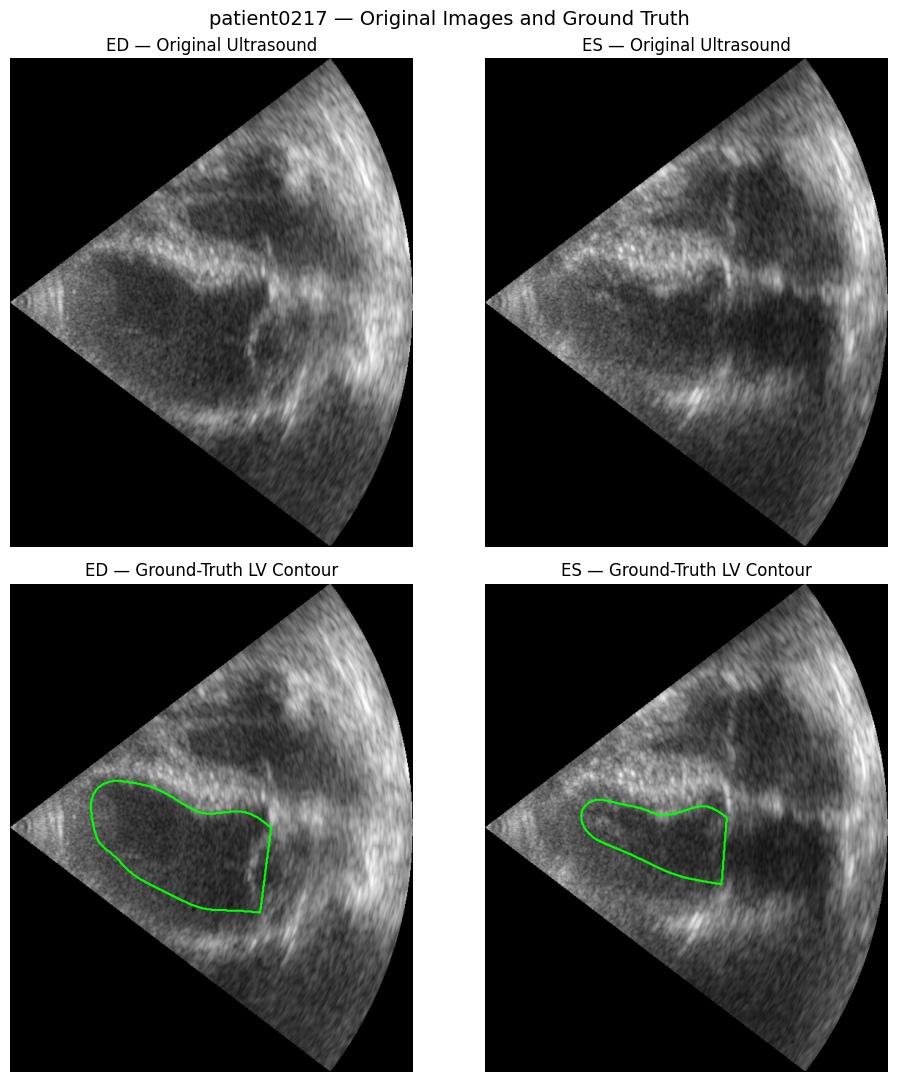


✓ Original images and LV masks visualized.


In [ ]:
# ================================================================
# PHASE 5E — CELL 10
# VISUALIZE ORIGINAL ED/ES IMAGES AND LV GROUND TRUTH
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

def load_nifti_array(path):
    nii = nib.load(str(path))
    arr = np.asarray(nii.get_fdata())

    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got shape {arr.shape}: {path}"
        )

    return arr

ed_image = load_nifti_array(required_files["ED image"])
es_image = load_nifti_array(required_files["ES image"])

ed_gt = load_nifti_array(required_files["ED ground truth"])
es_gt = load_nifti_array(required_files["ES ground truth"])

# CAMUS label 1 = LV cavity
ed_lv_mask = ed_gt == 1
es_lv_mask = es_gt == 1

print("ED image shape:", ed_image.shape)
print("ES image shape:", es_image.shape)

print("ED GT labels:", np.unique(ed_gt))
print("ES GT labels:", np.unique(es_gt))

print("ED LV pixels:", int(ed_lv_mask.sum()))
print("ES LV pixels:", int(es_lv_mask.sum()))

fig, axes = plt.subplots(2, 2, figsize=(10, 11))

axes[0, 0].imshow(ed_image, cmap="gray")
axes[0, 0].set_title("ED — Original Ultrasound")

axes[0, 1].imshow(es_image, cmap="gray")
axes[0, 1].set_title("ES — Original Ultrasound")

axes[1, 0].imshow(ed_image, cmap="gray")
axes[1, 0].contour(
    ed_lv_mask.astype(float),
    levels=[0.5],
    colors="lime",
    linewidths=1.5
)
axes[1, 0].set_title("ED — Ground-Truth LV Contour")

axes[1, 1].imshow(es_image, cmap="gray")
axes[1, 1].contour(
    es_lv_mask.astype(float),
    levels=[0.5],
    colors="lime",
    linewidths=1.5
)
axes[1, 1].set_title("ES — Ground-Truth LV Contour")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"{patient_id} — Original Images and Ground Truth",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\n✓ Original images and LV masks visualized.")

In [ ]:
# ================================================================
# PHASE 5E — CELL 11
# LOAD FROZEN INFERENCE MODULE
# ================================================================

import sys
import importlib
import inspect

MODULE_DIR = (
    PHASE5_ROOT
    / "phase5C_assistive_application"
    / "app"
)

sys.path.insert(0, str(MODULE_DIR))

import frozen_inference as inference

importlib.reload(inference)

print("=" * 75)
print("PHASE 5E — FROZEN INFERENCE MODULE")
print("=" * 75)

print("Module:", inference.__file__)

print("\nAnalyze LV frame signature:")
print(inspect.signature(inference.analyze_lv_frame))

print("\nAnalyze A4C pair signature:")
print(inspect.signature(inference.analyze_a4c_pair))

print("\nModule model-related variables:")

for name in dir(inference):
    if any(
        term in name.lower()
        for term in ["model", "threshold", "project_root"]
    ):
        if not name.startswith("__"):
            value = getattr(inference, name)

            # Avoid printing large model objects
            print(name, ":", str(value)[:200])

print("\n✓ Frozen module imported successfully.")

FROZEN PHASE 2 MEASUREMENT FUNCTIONS

✓ 256×256 stretch preprocessing
✓ Post-resize per-image min-max normalization
✓ Anisotropic effective spacing
✓ Threshold >= 0.50
✓ 8-connected largest component
✓ Binary hole filling
✓ Physical LV area
✓ Exact PCA major-axis length
✓ Single-plane area-length volume
FROZEN SEGMENTATION MODEL LOADED

Parameters: 7,759,521
Input shape : (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)

✓ Frozen Phase 1 model ready for inference.
✓ Single-frame frozen inference function ready.
COMPLETE FROZEN A4C PIPELINE

ED/ES input
   ↓
Frozen LV segmentation
   ↓
Physical LV geometry
   ↓
EDV / ESV / SV / EF
   ↓
Frozen EF-band classifier
   ↓
EF band + uncalibrated confidence

✓ analyze_a4c_pair() ready.
FROZEN PHASE 2 MEASUREMENT FUNCTIONS

✓ 256×256 stretch preprocessing
✓ Post-resize per-image min-max normalization
✓ Anisotropic effective spacing
✓ Threshold >= 0.50
✓ 8-connected largest component
✓ Binary hole filling
✓ Physical LV area
✓ Exact PCA major

In [ ]:
# ================================================================
# PHASE 5E — CELL 12 (CORRECTED)
# RUN FROZEN ED/ES INFERENCE
# ================================================================

import numpy as np

ed_path = required_files["ED image"]
es_path = required_files["ES image"]

ed_input, ed_spacing = inference.load_nifti_2d(ed_path)
es_input, es_spacing = inference.load_nifti_2d(es_path)

print("ED input shape:", ed_input.shape)
print("ES input shape:", es_input.shape)

print("ED spacing:", ed_spacing)
print("ES spacing:", es_spacing)

print("\nRunning frozen inference...")

# Correct argument order
result = inference.analyze_a4c_pair(
    ed_input,
    es_input,
    ed_spacing,
    es_spacing
)

print("\nResult type:", type(result))

if isinstance(result, dict):

    print("\nTop-level result keys:")
    for key in result.keys():
        print(" -", key)

    print("\nScalar outputs:")
    for key, value in result.items():
        if isinstance(
            value,
            (int, float, str, np.integer, np.floating)
        ):
            print(f"{key}: {value}")

else:
    print("\nResult structure:")
    print(str(result)[:1500])

print("\n✓ Frozen inference executed successfully.")

ED input shape: (669, 552)
ES input shape: (669, 552)
ED spacing: (0.30799999833106995, 0.30799999833106995)
ES spacing: (0.30799999833106995, 0.30799999833106995)

Running frozen inference...

Result type: <class 'dict'>

Top-level result keys:
 - segmentation
 - quantitative_measurements
 - classification
 - system

Scalar outputs:

✓ Frozen inference executed successfully.


In [ ]:
# ================================================================
# PHASE 5E — CELL 13
# INSPECT FROZEN PIPELINE OUTPUT STRUCTURE
# ================================================================

import numpy as np

print("=" * 75)
print("PHASE 5E — FROZEN INFERENCE OUTPUT STRUCTURE")
print("=" * 75)

def inspect_structure(obj, prefix="", depth=0, max_depth=3):
    if depth > max_depth:
        return

    if isinstance(obj, dict):
        for key, value in obj.items():
            name = f"{prefix}.{key}" if prefix else key

            if isinstance(value, dict):
                print(f"{name}: dictionary")
                inspect_structure(
                    value,
                    name,
                    depth + 1,
                    max_depth
                )

            elif isinstance(value, np.ndarray):
                print(
                    f"{name}: array "
                    f"shape={value.shape}, "
                    f"dtype={value.dtype}"
                )

            elif isinstance(value, (list, tuple)):
                print(
                    f"{name}: {type(value).__name__}, "
                    f"length={len(value)}"
                )

            else:
                print(f"{name}: {str(value)[:120]}")

inspect_structure(result)

print("\n✓ Frozen output structure inspected.")

PHASE 5E — FROZEN INFERENCE OUTPUT STRUCTURE
segmentation: dictionary
segmentation.ED: dictionary
segmentation.ED.processed_image: array shape=(256, 256), dtype=float32
segmentation.ED.probability_mask: array shape=(256, 256), dtype=float32
segmentation.ED.predicted_mask: array shape=(256, 256), dtype=bool
segmentation.ED.effective_spacing: tuple, length=2
segmentation.ES: dictionary
segmentation.ES.processed_image: array shape=(256, 256), dtype=float32
segmentation.ES.probability_mask: array shape=(256, 256), dtype=float32
segmentation.ES.predicted_mask: array shape=(256, 256), dtype=bool
segmentation.ES.effective_spacing: tuple, length=2
quantitative_measurements: dictionary
quantitative_measurements.ED_area_mm2: 2703.209137566088
quantitative_measurements.ES_area_mm2: 1571.0365147927096
quantitative_measurements.ED_length_mm: 77.14843132734248
quantitative_measurements.ES_length_mm: 68.20490207424155
quantitative_measurements.EDV_ml: 80.39907520427101
quantitative_measurements.ESV_m

In [ ]:
# ================================================================
# PHASE 5E — CELL 14
# REFERENCE VS GT-GEOMETRY VS PREDICTED EF
# ================================================================

patient_record = df.loc[
    df["patient_id"] == "patient0217"
].iloc[0]

print("=" * 75)
print("PATIENT0217 — FROZEN PHASE 2 RECORD")
print("=" * 75)

comparison = pd.DataFrame({
    "Measurement": [
        "EDV (mL)",
        "ESV (mL)",
        "SV (mL)",
        "EF (%)"
    ],
    "Ground-truth geometry": [
        patient_record["ED_GT_volume_ml"],
        patient_record["ES_GT_volume_ml"],
        patient_record["GT_SV_ml"],
        patient_record["GT_EF_pct"]
    ],
    "Predicted geometry": [
        patient_record["ED_PRED_volume_ml"],
        patient_record["ES_PRED_volume_ml"],
        patient_record["PRED_SV_ml"],
        patient_record["PRED_EF_pct"]
    ]
})

display(comparison.round(3))

print(
    "\nCAMUS reference EF:",
    patient_record["reference_EF_pct"]
)

print(
    "Ground-truth geometry EF:",
    round(patient_record["GT_EF_pct"], 3)
)

print(
    "Predicted geometry EF:",
    round(patient_record["PRED_EF_pct"], 3)
)

print(
    "\nReference-to-GT geometry EF difference:",
    round(
        abs(
            patient_record["reference_EF_pct"]
            - patient_record["GT_EF_pct"]
        ),
        3
    ),
    "percentage points"
)

print(
    "GT-to-predicted geometry EF difference:",
    round(
        abs(
            patient_record["GT_EF_pct"]
            - patient_record["PRED_EF_pct"]
        ),
        3
    ),
    "percentage points"
)

print("\n✓ Frozen Phase 2 record inspected.")

PATIENT0217 — FROZEN PHASE 2 RECORD


,Measurement,Ground-truth geometry,Predicted geometry
0,EDV (mL),79.386,80.399
1,ESV (mL),25.663,30.717
2,SV (mL),53.723,49.682
3,EF (%),67.673,61.795



CAMUS reference EF: 19.0
Ground-truth geometry EF: 67.673
Predicted geometry EF: 61.795

Reference-to-GT geometry EF difference: 48.673 percentage points
GT-to-predicted geometry EF difference: 5.878 percentage points

✓ Frozen Phase 2 record inspected.


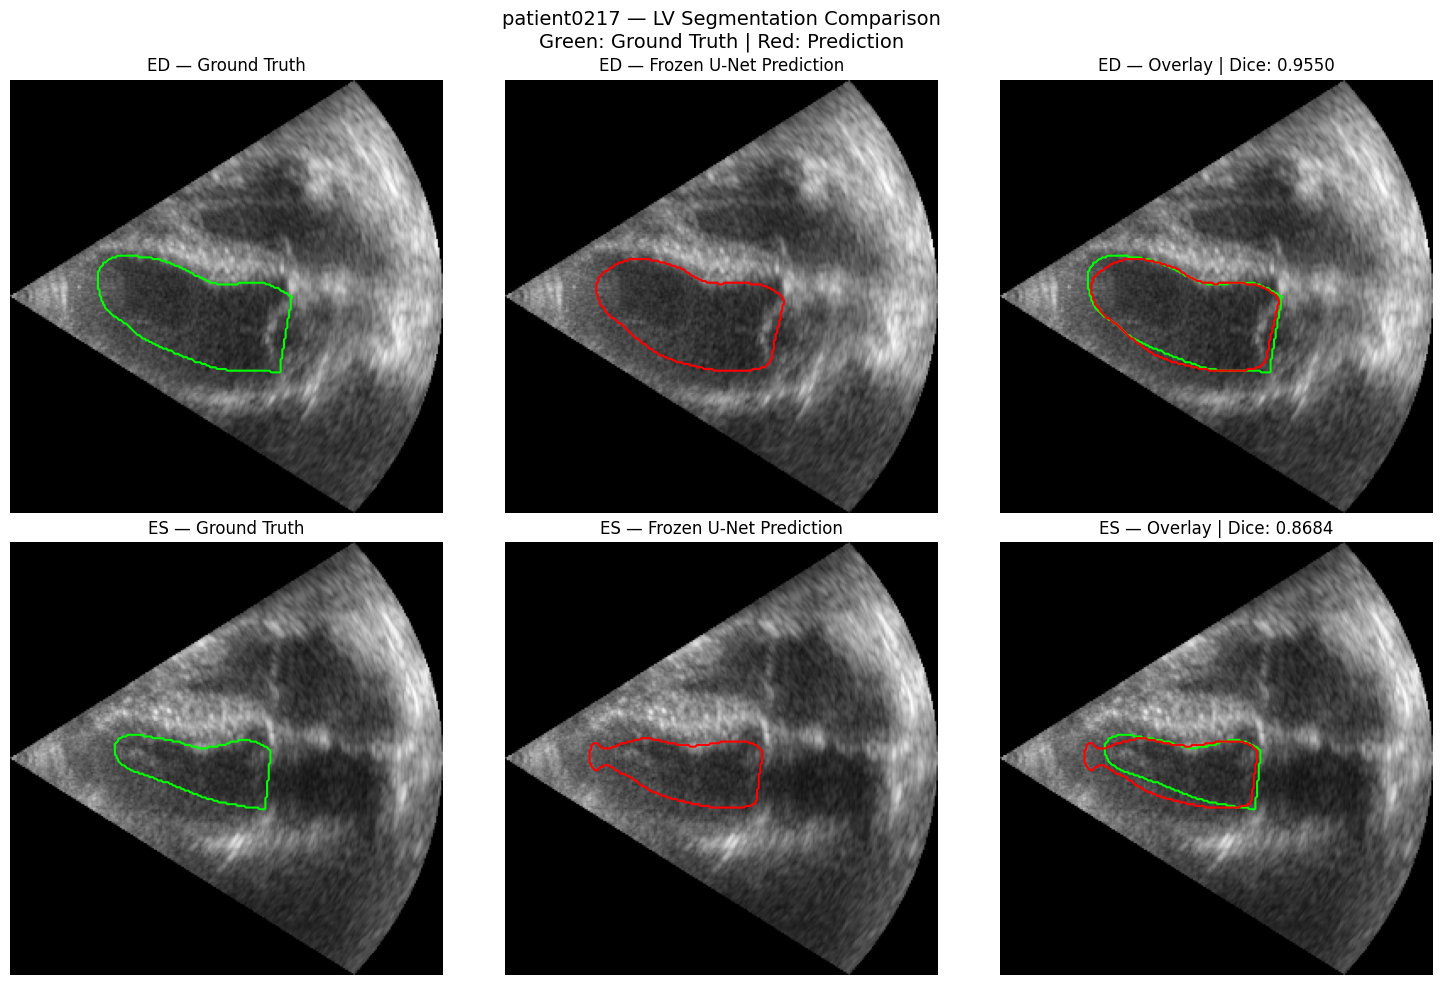

ED Dice: 0.955
ES Dice: 0.8684

Figure saved: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/patient0217_segmentation_comparison.png

✓ Segmentation comparison completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 15
# PREDICTED VS GROUND-TRUTH SEGMENTATION
# ================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

dice_results = {}

for row, phase in enumerate(["ED", "ES"]):

    seg = result["segmentation"][phase]

    processed_image = seg["processed_image"]
    predicted_mask = seg["predicted_mask"].astype(bool)

    native_gt = ed_gt if phase == "ED" else es_gt

    # Label 1 represents LV cavity
    gt_mask = (native_gt == 1).astype(np.uint8)

    gt_resized = cv2.resize(
        gt_mask,
        (256, 256),
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    intersection = np.logical_and(
        predicted_mask, gt_resized
    ).sum()

    denominator = (
        predicted_mask.sum() + gt_resized.sum()
    )

    dice = (
        2 * intersection / denominator
        if denominator > 0 else 1.0
    )

    dice_results[phase] = float(dice)

    axes[row, 0].imshow(
        processed_image, cmap="gray"
    )
    axes[row, 0].contour(
        gt_resized,
        levels=[0.5],
        colors="lime",
        linewidths=1.5
    )
    axes[row, 0].set_title(
        f"{phase} — Ground Truth"
    )

    axes[row, 1].imshow(
        processed_image, cmap="gray"
    )
    axes[row, 1].contour(
        predicted_mask,
        levels=[0.5],
        colors="red",
        linewidths=1.5
    )
    axes[row, 1].set_title(
        f"{phase} — Frozen U-Net Prediction"
    )

    axes[row, 2].imshow(
        processed_image, cmap="gray"
    )
    axes[row, 2].contour(
        gt_resized,
        levels=[0.5],
        colors="lime",
        linewidths=1.5
    )
    axes[row, 2].contour(
        predicted_mask,
        levels=[0.5],
        colors="red",
        linewidths=1.5
    )
    axes[row, 2].set_title(
        f"{phase} — Overlay | Dice: {dice:.4f}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "patient0217 — LV Segmentation Comparison\n"
    "Green: Ground Truth | Red: Prediction",
    fontsize=14
)

plt.tight_layout()

figure_path = (
    ANALYSIS_DIR /
    "patient0217_segmentation_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("ED Dice:", round(dice_results["ED"], 4))
print("ES Dice:", round(dice_results["ES"], 4))

print("\nFigure saved:", figure_path)
print("\n✓ Segmentation comparison completed.")

In [ ]:
# ================================================================
# PHASE 5E — CELL 16
# NUMERICAL REGRESSION + CAMUS REFERENCE METADATA
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

q = result["quantitative_measurements"]

measurement_mapping = {
    "ED_area_mm2": "ED_PRED_area_mm2",
    "ES_area_mm2": "ES_PRED_area_mm2",
    "ED_length_mm": "ED_PRED_length_mm",
    "ES_length_mm": "ES_PRED_length_mm",
    "EDV_ml": "ED_PRED_volume_ml",
    "ESV_ml": "ES_PRED_volume_ml",
    "SV_ml": "PRED_SV_ml",
    "EF_pct": "PRED_EF_pct"
}

comparison_rows = []

for result_key, csv_column in measurement_mapping.items():

    current = float(q[result_key])
    frozen = float(patient_record[csv_column])

    comparison_rows.append({
        "measurement": result_key,
        "current_inference": current,
        "frozen_phase2": frozen,
        "absolute_difference": abs(current - frozen)
    })

regression_df = pd.DataFrame(comparison_rows)

print("=" * 75)
print("FROZEN NUMERICAL REGRESSION")
print("=" * 75)

display(regression_df)

max_difference = regression_df[
    "absolute_difference"
].max()

print("Maximum absolute difference:", max_difference)

assert np.allclose(
    regression_df["current_inference"],
    regression_df["frozen_phase2"],
    rtol=1e-9,
    atol=1e-8
), "Frozen numerical regression failed."

print("\n✓ Frozen quantitative results reproduced.")

print("\n" + "=" * 75)
print("CAMUS PATIENT REFERENCE METADATA")
print("=" * 75)

for filename in ["Info_4CH.cfg", "Info_2CH.cfg"]:

    path = patient_dir / filename

    print(f"\n--- {filename} ---")

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("File not found.")

regression_df.to_csv(
    ANALYSIS_DIR /
    "patient0217_frozen_regression.csv",
    index=False
)

FROZEN NUMERICAL REGRESSION


,measurement,current_inference,frozen_phase2,absolute_difference
0,ED_area_mm2,2703.209138,2703.209138,0.000000e+00
1,ES_area_mm2,1571.036515,1571.036515,0.000000e+00
2,ED_length_mm,77.148431,77.148431,0.000000e+00
3,ES_length_mm,68.204902,68.204902,0.000000e+00
4,EDV_ml,80.399075,80.399075,0.000000e+00
5,ESV_ml,30.716790,30.716790,3.552714e-15
6,SV_ml,49.682285,49.682285,7.105427e-15
7,EF_pct,61.794598,61.794598,0.000000e+00


Maximum absolute difference: 7.105427357601002e-15

✓ Frozen quantitative results reproduced.

CAMUS PATIENT REFERENCE METADATA

--- Info_4CH.cfg ---
ED: 1
ES: 22
NbFrame: 22
Sex: F
Age: 73
ImageQuality: Good
EF: 19
FrameRate: 56.5

--- Info_2CH.cfg ---
ED: 21
ES: 1
NbFrame: 21
Sex: F
Age: 73
ImageQuality: Medium
EF: 19
FrameRate: 56.5


In [ ]:
# ================================================================
# PHASE 5E — CELL 17
# EF ERROR DECOMPOSITION — ALL 50 PATIENTS
# ================================================================

import numpy as np
import pandas as pd

error_df = df.copy()

# Signed differences
error_df["reference_to_GT_signed"] = (
    error_df["GT_EF_pct"]
    - error_df["reference_EF_pct"]
)

error_df["GT_to_PRED_signed"] = (
    error_df["PRED_EF_pct"]
    - error_df["GT_EF_pct"]
)

error_df["reference_to_PRED_signed"] = (
    error_df["PRED_EF_pct"]
    - error_df["reference_EF_pct"]
)

# Absolute differences
error_df["reference_to_GT_abs"] = (
    error_df["reference_to_GT_signed"].abs()
)

error_df["GT_to_PRED_abs"] = (
    error_df["GT_to_PRED_signed"].abs()
)

error_df["reference_to_PRED_abs"] = (
    error_df["reference_to_PRED_signed"].abs()
)

# Exact signed-error decomposition
assert np.allclose(
    error_df["reference_to_PRED_signed"],
    error_df["reference_to_GT_signed"]
    + error_df["GT_to_PRED_signed"],
    atol=1e-10
)

summary = pd.DataFrame({
    "Comparison": [
        "Reference → GT geometry",
        "GT geometry → Predicted geometry",
        "Reference → Predicted geometry"
    ],
    "Mean absolute difference (pp)": [
        error_df["reference_to_GT_abs"].mean(),
        error_df["GT_to_PRED_abs"].mean(),
        error_df["reference_to_PRED_abs"].mean()
    ],
    "Median absolute difference (pp)": [
        error_df["reference_to_GT_abs"].median(),
        error_df["GT_to_PRED_abs"].median(),
        error_df["reference_to_PRED_abs"].median()
    ],
    "Maximum absolute difference (pp)": [
        error_df["reference_to_GT_abs"].max(),
        error_df["GT_to_PRED_abs"].max(),
        error_df["reference_to_PRED_abs"].max()
    ]
})

print("=" * 75)
print("PHASE 5E — EF ERROR DECOMPOSITION")
print("=" * 75)

display(summary.round(3))

print("\nPatients with largest reference-to-GT differences:")

display(
    error_df.sort_values(
        "reference_to_GT_abs",
        ascending=False
    )[
        [
            "patient_id",
            "image_quality",
            "reference_EF_pct",
            "GT_EF_pct",
            "PRED_EF_pct",
            "reference_to_GT_abs",
            "GT_to_PRED_abs"
        ]
    ].head(10)
)

error_path = (
    ANALYSIS_DIR / "ef_error_decomposition_50_patients.csv"
)

summary_path = (
    ANALYSIS_DIR / "ef_error_decomposition_summary.csv"
)

error_df.to_csv(error_path, index=False)
summary.to_csv(summary_path, index=False)

print("\nSaved:", error_path)
print("Saved:", summary_path)
print("\n✓ EF error decomposition completed.")

PHASE 5E — EF ERROR DECOMPOSITION


,Comparison,Mean absolute difference (pp),Median absolute difference (pp),Maximum absolute difference (pp)
0,Reference → GT geometry,6.668,5.425,48.673
1,GT geometry → Predicted geometry,5.894,4.683,18.055
2,Reference → Predicted geometry,8.191,7.288,42.795



Patients with largest reference-to-GT differences:


,patient_id,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,reference_to_GT_abs,GT_to_PRED_abs
33,patient0217,Good,19.0,67.672718,61.794598,48.672718,5.878121
31,patient0016,Good,50.0,66.844136,60.695152,16.844136,6.148983
48,patient0058,Good,31.0,45.972649,43.415762,14.972649,2.556887
5,patient0175,Medium,45.0,57.385194,61.819178,12.385194,4.433984
35,patient0045,Good,38.0,49.543354,47.808328,11.543354,1.735027
19,patient0487,Good,41.0,51.782082,42.864303,10.782082,8.917779
49,patient0328,Poor,25.0,35.672906,47.230385,10.672906,11.557479
17,patient0113,Poor,13.0,2.592787,10.986156,10.407213,8.393369
42,patient0072,Medium,38.0,47.884546,53.531852,9.884546,5.647305
25,patient0014,Good,50.0,59.130401,73.481698,9.130401,14.351298



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/ef_error_decomposition_50_patients.csv
Saved: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/ef_error_decomposition_summary.csv

✓ EF error decomposition completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 18
# EF ERRORS BY IMAGE QUALITY
# ================================================================

quality_summary = (
    error_df.groupby("image_quality")
    .agg(
        patients=("patient_id", "count"),
        reference_GT_MAE=("reference_to_GT_abs", "mean"),
        GT_prediction_MAE=("GT_to_PRED_abs", "mean"),
        reference_prediction_MAE=(
            "reference_to_PRED_abs", "mean"
        )
    )
    .reset_index()
)

print("=" * 75)
print("EF ERROR ANALYSIS BY IMAGE QUALITY")
print("=" * 75)

display(quality_summary.round(3))

quality_summary.to_csv(
    ANALYSIS_DIR / "ef_errors_by_image_quality.csv",
    index=False
)

print(
    "\nNote: Image-quality subgroups are small, "
    "especially the Poor group (7 patients)."
)

print("\n✓ Quality subgroup analysis completed.")

EF ERROR ANALYSIS BY IMAGE QUALITY


,image_quality,patients,reference_GT_MAE,GT_prediction_MAE,reference_prediction_MAE
0,Good,30,7.762,5.029,7.312
1,Medium,13,4.794,6.028,9.734
2,Poor,7,5.457,9.354,9.090



Note: Image-quality subgroups are small, especially the Poor group (7 patients).

✓ Quality subgroup analysis completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 19
# REPRESENTATIVE PATIENT SEGMENTATION EVALUATION
# ================================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

review_rows = []

for _, patient in selected_patients_df.iterrows():

    pid = patient["patient_id"]
    folder = DATASET_ROOT / pid

    ed_path = folder / f"{pid}_4CH_ED.nii.gz"
    es_path = folder / f"{pid}_4CH_ES.nii.gz"

    ed_gt_path = folder / f"{pid}_4CH_ED_gt.nii.gz"
    es_gt_path = folder / f"{pid}_4CH_ES_gt.nii.gz"

    # Load images using frozen loader
    ed_img, ed_spacing = inference.load_nifti_2d(ed_path)
    es_img, es_spacing = inference.load_nifti_2d(es_path)

    # Run frozen pipeline
    output = inference.analyze_a4c_pair(
        ed_img,
        es_img,
        ed_spacing,
        es_spacing
    )

    dice_scores = {}

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for idx, (phase, gt_path) in enumerate([
        ("ED", ed_gt_path),
        ("ES", es_gt_path)
    ]):

        gt_native = load_nifti_array(gt_path)

        gt_mask = cv2.resize(
            (gt_native == 1).astype(np.uint8),
            (256, 256),
            interpolation=cv2.INTER_NEAREST
        ).astype(bool)

        seg = output["segmentation"][phase]

        pred_mask = seg["predicted_mask"].astype(bool)
        processed = seg["processed_image"]

        intersection = np.logical_and(
            gt_mask, pred_mask
        ).sum()

        denominator = gt_mask.sum() + pred_mask.sum()

        dice = (
            2 * intersection / denominator
            if denominator > 0 else 1.0
        )

        dice_scores[phase] = float(dice)

        axes[idx].imshow(processed, cmap="gray")

        axes[idx].contour(
            gt_mask,
            levels=[0.5],
            colors="lime",
            linewidths=1.5
        )

        axes[idx].contour(
            pred_mask,
            levels=[0.5],
            colors="red",
            linewidths=1.5
        )

        axes[idx].set_title(
            f"{phase} | Dice: {dice:.4f}"
        )

        axes[idx].axis("off")

    fig.suptitle(
        f"{pid} | Quality: {patient['image_quality']}\n"
        f"Reference EF: {patient['reference_EF_pct']:.1f}% | "
        f"Predicted EF: {output['quantitative_measurements']['EF_pct']:.1f}%\n"
        "Green: Ground Truth | Red: Prediction"
    )

    fig.tight_layout()

    fig.savefig(
        ANALYSIS_DIR / f"{pid}_review.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    q = output["quantitative_measurements"]

    review_rows.append({
        "patient_id": pid,
        "image_quality": patient["image_quality"],
        "reference_band": patient["reference_band"],
        "ED_Dice": dice_scores["ED"],
        "ES_Dice": dice_scores["ES"],
        "reference_EF_pct": patient["reference_EF_pct"],
        "GT_EF_pct": patient["GT_EF_pct"],
        "PRED_EF_pct": q["EF_pct"],
        "EF_abs_error_pp": abs(
            q["EF_pct"] - patient["reference_EF_pct"]
        ),
        "predicted_class": output[
            "classification"
        ]["estimated_EF_band"]
    })

    print(
        f"✓ {pid} | "
        f"ED Dice={dice_scores['ED']:.4f} | "
        f"ES Dice={dice_scores['ES']:.4f}"
    )

review_df = pd.DataFrame(review_rows)

review_path = (
    ANALYSIS_DIR / "representative_patient_review.csv"
)

review_df.to_csv(review_path, index=False)

print("\n" + "=" * 75)
print("12-PATIENT REVIEW SUMMARY")
print("=" * 75)

display(review_df.round(3))

print("\nSaved:", review_path)
print("\n✓ Representative patient evaluation completed.")

✓ patient0014 | ED Dice=0.9042 | ES Dice=0.7170
✓ patient0048 | ED Dice=0.9060 | ES Dice=0.9305
✓ patient0360 | ED Dice=0.9424 | ES Dice=0.8716
✓ patient0141 | ED Dice=0.9568 | ES Dice=0.9592
✓ patient0259 | ED Dice=0.9334 | ES Dice=0.9147
✓ patient0446 | ED Dice=0.9696 | ES Dice=0.9540
✓ patient0465 | ED Dice=0.9473 | ES Dice=0.8761
✓ patient0378 | ED Dice=0.9438 | ES Dice=0.9291
✓ patient0126 | ED Dice=0.9383 | ES Dice=0.9532
✓ patient0217 | ED Dice=0.9550 | ES Dice=0.8684
✓ patient0113 | ED Dice=0.9130 | ES Dice=0.9059
✓ patient0120 | ED Dice=0.9337 | ES Dice=0.9322

12-PATIENT REVIEW SUMMARY


,patient_id,image_quality,reference_band,ED_Dice,ES_Dice,reference_EF_pct,GT_EF_pct,PRED_EF_pct,EF_abs_error_pp,predicted_class
0,patient0014,Good,Higher_EF,0.904,0.717,50.0,59.130,73.482,23.482,Higher_EF
1,patient0048,Good,Higher_EF,0.906,0.930,55.0,61.165,58.972,3.972,Higher_EF
2,patient0360,Good,Higher_EF,0.942,0.872,68.0,71.873,68.117,0.117,Higher_EF
3,patient0141,Medium,Higher_EF,0.957,0.959,55.0,59.989,62.742,7.742,Higher_EF
4,patient0259,Good,Intermediate_EF,0.933,0.915,47.0,43.932,46.306,0.694,Intermediate_EF
5,patient0446,Good,Intermediate_EF,0.970,0.954,48.0,55.691,56.243,8.243,Intermediate_EF
6,patient0465,Medium,Intermediate_EF,0.947,0.876,45.0,53.044,63.437,18.437,Higher_EF
7,patient0378,Poor,Intermediate_EF,0.944,0.929,49.0,52.111,43.022,5.978,Lower_EF
8,patient0126,Good,Lower_EF,0.938,0.953,38.0,30.024,37.011,0.989,Lower_EF
9,patient0217,Good,Lower_EF,0.955,0.868,19.0,67.673,61.795,42.795,Higher_EF



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/representative_patient_review.csv

✓ Representative patient evaluation completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 20
# SUMMARIZE REPRESENTATIVE PATIENT RESULTS
# ================================================================

print("=" * 75)
print("PHASE 5E — REPRESENTATIVE PATIENT SUMMARY")
print("=" * 75)

print("\nSegmentation Dice summary:")
display(
    review_df[["ED_Dice", "ES_Dice"]]
    .describe()
    .round(4)
)

print("\nMean Dice by image quality:")
display(
    review_df.groupby("image_quality")[
        ["ED_Dice", "ES_Dice"]
    ].mean().round(4)
)

print("\nCases with lowest ES Dice:")
display(
    review_df.sort_values("ES_Dice")[
        [
            "patient_id",
            "image_quality",
            "ED_Dice",
            "ES_Dice",
            "reference_EF_pct",
            "GT_EF_pct",
            "PRED_EF_pct"
        ]
    ].head(5).round(3)
)

print("\nMean absolute EF difference:")
print(
    round(review_df["EF_abs_error_pp"].mean(), 3),
    "percentage points"
)

print("\n✓ Phase 5E-A numerical and visual review completed.")

PHASE 5E — REPRESENTATIVE PATIENT SUMMARY

Segmentation Dice summary:


,ED_Dice,ES_Dice
count,12.0000,12.0000
mean,0.9370,0.9010
std,0.0204,0.0662
min,0.9042,0.7170
25%,0.9283,0.8750
50%,0.9404,0.9219
75%,0.9492,0.9374
max,0.9696,0.9592



Mean Dice by image quality:


,ED_Dice,ES_Dice
image_quality,,
Good,0.9356,0.8871
Medium,0.9520,0.9176
Poor,0.9302,0.9224



Cases with lowest ES Dice:


,patient_id,image_quality,ED_Dice,ES_Dice,reference_EF_pct,GT_EF_pct,PRED_EF_pct
0,patient0014,Good,0.904,0.717,50.0,59.130,73.482
9,patient0217,Good,0.955,0.868,19.0,67.673,61.795
2,patient0360,Good,0.942,0.872,68.0,71.873,68.117
6,patient0465,Medium,0.947,0.876,45.0,53.044,63.437
10,patient0113,Poor,0.913,0.906,13.0,2.593,10.986



Mean absolute EF difference:
10.269 percentage points

✓ Phase 5E-A numerical and visual review completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 21
# CREATE INDEPENDENT QUALITY CHECKING MODULE
# ================================================================

from pathlib import Path

QUALITY_MODULE_PATH = APP_DIR / "quality_checks.py"

quality_code = '''
import numpy as np


def ef_band(ef):
    """Use the same EF-band boundaries as the frozen pipeline."""
    if not np.isfinite(float(ef)):
        return "Unknown"

    ef = float(ef)

    if ef <= 40:
        return "Lower_EF"
    elif ef < 50:
        return "Intermediate_EF"
    return "Higher_EF"


def assess_quality(result):
    """
    Technical quality checks for frozen A4C inference.

    These are review flags, not validated clinical
    reliability or diagnostic assessments.
    """

    warnings = []

    segmentation = result["segmentation"]
    measurements = result["quantitative_measurements"]
    classification = result["classification"]

    ed_mask = np.asarray(
        segmentation["ED"]["predicted_mask"],
        dtype=bool
    )

    es_mask = np.asarray(
        segmentation["ES"]["predicted_mask"],
        dtype=bool
    )

    # ------------------------------------------------------------
    # 1. Empty masks
    # ------------------------------------------------------------
    if not ed_mask.any():
        warnings.append(
            "ED segmentation is empty. "
            "LV measurements require review."
        )

    if not es_mask.any():
        warnings.append(
            "ES segmentation is empty. "
            "LV measurements require review."
        )

    # ------------------------------------------------------------
    # 2. Small-mask technical flag
    # ------------------------------------------------------------
    # 0.5% is an exploratory image-coverage heuristic,
    # not a clinically validated cutoff.
    # ------------------------------------------------------------
    min_fraction = 0.005

    ed_fraction = ed_mask.mean()
    es_fraction = es_mask.mean()

    if 0 < ed_fraction < min_fraction:
        warnings.append(
            "ED LV mask occupies less than 0.5% of "
            "the processed image. Review segmentation."
        )

    if 0 < es_fraction < min_fraction:
        warnings.append(
            "ES LV mask occupies less than 0.5% of "
            "the processed image. Review segmentation."
        )

    # ------------------------------------------------------------
    # 3. ED/ES consistency checks
    # ------------------------------------------------------------
    ed_area = float(measurements["ED_area_mm2"])
    es_area = float(measurements["ES_area_mm2"])

    edv = float(measurements["EDV_ml"])
    esv = float(measurements["ESV_ml"])

    if np.isfinite(ed_area) and np.isfinite(es_area):
        if ed_area <= es_area:
            warnings.append(
                "ED LV area is not larger than ES LV area. "
                "Verify frame selection and segmentation."
            )

    if np.isfinite(edv) and np.isfinite(esv):
        if edv <= esv:
            warnings.append(
                "Estimated EDV is not larger than ESV. "
                "Verify frame selection and measurements."
            )

    # ------------------------------------------------------------
    # 4. EF-band disagreement
    # ------------------------------------------------------------
    ef = float(measurements["EF_pct"])

    geometry_band = ef_band(ef)

    classifier_band = classification[
        "estimated_EF_band"
    ]

    if geometry_band != classifier_band:
        warnings.append(
            "Geometry-derived EF band differs from "
            "the frozen classifier's estimated EF band. "
            "Interpret both outputs cautiously."
        )

    # ------------------------------------------------------------
    # 5. Invalid numerical measurements
    # ------------------------------------------------------------
    for key in [
        "ED_area_mm2",
        "ES_area_mm2",
        "ED_length_mm",
        "ES_length_mm",
        "EDV_ml",
        "ESV_ml",
        "SV_ml",
        "EF_pct"
    ]:
        value = float(measurements[key])

        if not np.isfinite(value):
            warnings.append(
                f"{key} is not finite. "
                "Quantitative output requires review."
            )

    return {
        "status": (
            "REVIEW_RECOMMENDED"
            if warnings else "NO_RULE_FLAGS"
        ),
        "warnings": warnings,
        "ED_mask_fraction": float(ed_fraction),
        "ES_mask_fraction": float(es_fraction),
        "geometry_EF_band": geometry_band,
        "classifier_EF_band": classifier_band,
        "interpretation": (
            "Technical review flags only. "
            "Absence of flags does not establish "
            "segmentation accuracy, EF accuracy, "
            "or clinical reliability."
        )
    }
'''

QUALITY_MODULE_PATH.write_text(
    quality_code,
    encoding="utf-8"
)

print("Quality module saved:")
print(QUALITY_MODULE_PATH)

assert QUALITY_MODULE_PATH.exists()

print("\n✓ Independent quality module created.")

Quality module saved:
/content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/app/quality_checks.py

✓ Independent quality module created.


In [ ]:
# ================================================================
# PHASE 5E — CELL 22
# TEST QUALITY CHECKS ON EXISTING FROZEN OUTPUT
# ================================================================

import sys
import importlib

sys.path.insert(0, str(APP_DIR))

import quality_checks

importlib.reload(quality_checks)

quality_result = quality_checks.assess_quality(result)

print("=" * 75)
print("PHASE 5E — QUALITY ASSESSMENT")
print("=" * 75)

print("Patient: patient0217")

print("\nStatus:", quality_result["status"])

print(
    "ED mask coverage:",
    round(quality_result["ED_mask_fraction"] * 100, 3),
    "%"
)

print(
    "ES mask coverage:",
    round(quality_result["ES_mask_fraction"] * 100, 3),
    "%"
)

print(
    "\nGeometry EF band:",
    quality_result["geometry_EF_band"]
)

print(
    "Classifier EF band:",
    quality_result["classifier_EF_band"]
)

print("\nWarnings:")

if quality_result["warnings"]:
    for i, warning in enumerate(
        quality_result["warnings"], 1
    ):
        print(f"{i}. {warning}")
else:
    print("No predefined technical flags triggered.")

print("\nInterpretation:")
print(quality_result["interpretation"])

print("\n✓ Quality assessment executed.")

PHASE 5E — QUALITY ASSESSMENT
Patient: patient0217

Status: NO_RULE_FLAGS
ED mask coverage: 7.716 %
ES mask coverage: 4.485 %

Geometry EF band: Higher_EF
Classifier EF band: Higher_EF

Warnings:
No predefined technical flags triggered.

Interpretation:
Technical review flags only. Absence of flags does not establish segmentation accuracy, EF accuracy, or clinical reliability.

✓ Quality assessment executed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 23
# SYNTHETIC QUALITY-CHECK TESTS
# ================================================================

import copy
import numpy as np

def check_case(name, modified, expected_phrase):
    assessment = quality_checks.assess_quality(modified)

    passed = any(
        expected_phrase.lower() in warning.lower()
        for warning in assessment["warnings"]
    )

    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

    assert passed, f"Test failed: {name}"


# 1. Empty ED mask
case1 = copy.deepcopy(result)
case1["segmentation"]["ED"]["predicted_mask"] = (
    np.zeros((256, 256), dtype=bool)
)

check_case(
    "Empty ED mask",
    case1,
    "ED segmentation is empty"
)


# 2. Very small ES mask
case2 = copy.deepcopy(result)

small_mask = np.zeros((256, 256), dtype=bool)
small_mask[100:105, 100:105] = True

case2["segmentation"]["ES"]["predicted_mask"] = small_mask

check_case(
    "Very small ES mask",
    case2,
    "less than 0.5%"
)


# 3. ED area <= ES area
case3 = copy.deepcopy(result)

case3["quantitative_measurements"]["ED_area_mm2"] = 100.0
case3["quantitative_measurements"]["ES_area_mm2"] = 150.0

check_case(
    "Unexpected ED/ES area relationship",
    case3,
    "ED LV area is not larger"
)


# 4. EDV <= ESV
case4 = copy.deepcopy(result)

case4["quantitative_measurements"]["EDV_ml"] = 20.0
case4["quantitative_measurements"]["ESV_ml"] = 30.0

check_case(
    "Unexpected EDV/ESV relationship",
    case4,
    "Estimated EDV is not larger"
)


# 5. Geometry/classifier disagreement
case5 = copy.deepcopy(result)

case5["classification"]["estimated_EF_band"] = "Lower_EF"

check_case(
    "Geometry/classifier EF-band disagreement",
    case5,
    "Geometry-derived EF band differs"
)


print("\n✓ All five synthetic warning tests passed.")

PASS | Empty ED mask
PASS | Very small ES mask
PASS | Unexpected ED/ES area relationship
PASS | Unexpected EDV/ESV relationship
PASS | Geometry/classifier EF-band disagreement

✓ All five synthetic warning tests passed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 24
# QUALITY WARNING EVALUATION ON 12 PATIENTS
# ================================================================

import pandas as pd
import numpy as np

quality_review_rows = []

for _, patient in selected_patients_df.iterrows():

    pid = patient["patient_id"]
    folder = DATASET_ROOT / pid

    ed_path = folder / f"{pid}_4CH_ED.nii.gz"
    es_path = folder / f"{pid}_4CH_ES.nii.gz"

    ed_img, ed_spacing = inference.load_nifti_2d(ed_path)
    es_img, es_spacing = inference.load_nifti_2d(es_path)

    output = inference.analyze_a4c_pair(
        ed_img,
        es_img,
        ed_spacing,
        es_spacing
    )

    assessment = quality_checks.assess_quality(output)

    predicted_ef = float(
        output["quantitative_measurements"]["EF_pct"]
    )

    # Verify frozen Phase 2 numerical consistency
    frozen_ef = float(patient["PRED_EF_pct"])

    assert np.isclose(
        predicted_ef,
        frozen_ef,
        rtol=1e-9,
        atol=1e-8
    ), f"Frozen EF mismatch for {pid}"

    quality_review_rows.append({
        "patient_id": pid,
        "image_quality": patient["image_quality"],
        "reference_band": patient["reference_band"],
        "reference_EF_pct": patient["reference_EF_pct"],
        "predicted_EF_pct": predicted_ef,
        "EF_abs_error_pp": abs(
            predicted_ef - patient["reference_EF_pct"]
        ),
        "ED_mask_coverage_pct": (
            assessment["ED_mask_fraction"] * 100
        ),
        "ES_mask_coverage_pct": (
            assessment["ES_mask_fraction"] * 100
        ),
        "geometry_EF_band": assessment["geometry_EF_band"],
        "classifier_EF_band": assessment["classifier_EF_band"],
        "quality_status": assessment["status"],
        "warning_count": len(assessment["warnings"]),
        "warnings": " | ".join(assessment["warnings"])
    })

    print(
        f"✓ {pid} | "
        f"{assessment['status']} | "
        f"{len(assessment['warnings'])} warning(s)"
    )

quality_review_df = pd.DataFrame(quality_review_rows)

print("\n" + "=" * 75)
print("PHASE 5E — QUALITY WARNING REVIEW")
print("=" * 75)

display(
    quality_review_df[
        [
            "patient_id",
            "image_quality",
            "EF_abs_error_pp",
            "geometry_EF_band",
            "classifier_EF_band",
            "quality_status",
            "warning_count"
        ]
    ].round(3)
)

quality_review_path = (
    ANALYSIS_DIR / "quality_warning_review_12_patients.csv"
)

quality_review_df.to_csv(
    quality_review_path,
    index=False
)

print("\nSaved:", quality_review_path)
print("\n✓ All 12 patient results reproduced.")

✓ patient0014 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0048 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0360 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0141 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0259 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0446 | REVIEW_RECOMMENDED | 1 warning(s)
✓ patient0465 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0378 | REVIEW_RECOMMENDED | 1 warning(s)
✓ patient0126 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0217 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0113 | NO_RULE_FLAGS | 0 warning(s)
✓ patient0120 | NO_RULE_FLAGS | 0 warning(s)

PHASE 5E — QUALITY WARNING REVIEW


,patient_id,image_quality,EF_abs_error_pp,geometry_EF_band,classifier_EF_band,quality_status,warning_count
0,patient0014,Good,23.482,Higher_EF,Higher_EF,NO_RULE_FLAGS,0
1,patient0048,Good,3.972,Higher_EF,Higher_EF,NO_RULE_FLAGS,0
2,patient0360,Good,0.117,Higher_EF,Higher_EF,NO_RULE_FLAGS,0
3,patient0141,Medium,7.742,Higher_EF,Higher_EF,NO_RULE_FLAGS,0
4,patient0259,Good,0.694,Intermediate_EF,Intermediate_EF,NO_RULE_FLAGS,0
5,patient0446,Good,8.243,Higher_EF,Intermediate_EF,REVIEW_RECOMMENDED,1
6,patient0465,Medium,18.437,Higher_EF,Higher_EF,NO_RULE_FLAGS,0
7,patient0378,Poor,5.978,Intermediate_EF,Lower_EF,REVIEW_RECOMMENDED,1
8,patient0126,Good,0.989,Lower_EF,Lower_EF,NO_RULE_FLAGS,0
9,patient0217,Good,42.795,Higher_EF,Higher_EF,NO_RULE_FLAGS,0



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/analysis/quality_warning_review_12_patients.csv

✓ All 12 patient results reproduced.


In [ ]:
# ================================================================
# PHASE 5E — CELL 25
# QUALITY WARNING BEHAVIOR SUMMARY
# ================================================================

print("=" * 75)
print("PHASE 5E — QUALITY WARNING SUMMARY")
print("=" * 75)

print("\nQuality status distribution:")
display(
    quality_review_df["quality_status"].value_counts()
)

print("\nPatients with technical warnings:")
display(
    quality_review_df.loc[
        quality_review_df["warning_count"] > 0,
        [
            "patient_id",
            "image_quality",
            "EF_abs_error_pp",
            "warning_count",
            "warnings"
        ]
    ]
)

print("\nPatients without technical warnings:")
display(
    quality_review_df.loc[
        quality_review_df["warning_count"] == 0,
        [
            "patient_id",
            "image_quality",
            "EF_abs_error_pp"
        ]
    ].round(3)
)

print("\nExploratory comparison of EF error by warning status:")

display(
    quality_review_df.groupby("quality_status").agg(
        patients=("patient_id", "count"),
        mean_EF_abs_error_pp=("EF_abs_error_pp", "mean"),
        max_EF_abs_error_pp=("EF_abs_error_pp", "max")
    ).round(3)
)

print(
    "\nReminder: This is a selected 12-patient sample. "
    "The warnings are not validated predictors of EF accuracy."
)

print("\n✓ Warning behavior analysis completed.")

PHASE 5E — QUALITY WARNING SUMMARY

Quality status distribution:


,count
quality_status,
NO_RULE_FLAGS,10
REVIEW_RECOMMENDED,2



Patients with technical warnings:


,patient_id,image_quality,EF_abs_error_pp,warning_count,warnings
5,patient0446,Good,8.243038,1,Geometry-derived EF band differs from the froz...
7,patient0378,Poor,5.978485,1,Geometry-derived EF band differs from the froz...



Patients without technical warnings:


,patient_id,image_quality,EF_abs_error_pp
0,patient0014,Good,23.482
1,patient0048,Good,3.972
2,patient0360,Good,0.117
3,patient0141,Medium,7.742
4,patient0259,Good,0.694
6,patient0465,Medium,18.437
8,patient0126,Good,0.989
9,patient0217,Good,42.795
10,patient0113,Poor,2.014
11,patient0120,Poor,8.762



Exploratory comparison of EF error by warning status:


,patients,mean_EF_abs_error_pp,max_EF_abs_error_pp
quality_status,,,
NO_RULE_FLAGS,10,10.900,42.795
REVIEW_RECOMMENDED,2,7.111,8.243



Reminder: This is a selected 12-patient sample. The warnings are not validated predictors of EF accuracy.

✓ Warning behavior analysis completed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 26
# CREATE EF INTERPRETATION MODULE
# ================================================================

from pathlib import Path

INTERPRETATION_MODULE_PATH = APP_DIR / "ef_interpretation.py"

interpretation_code = '''
import numpy as np


def get_ef_band(ef):
    """Use the frozen pipeline's EF-band definitions."""
    ef = float(ef)

    if not np.isfinite(ef):
        return "Unknown"

    if ef <= 40:
        return "Lower_EF"
    elif ef < 50:
        return "Intermediate_EF"
    return "Higher_EF"


def build_ef_interpretation(result, quality_assessment):
    """
    Explain frozen geometric EF and classifier outputs.

    Does not modify measurements or classifier predictions.
    """

    measurements = result["quantitative_measurements"]
    classification = result["classification"]

    edv = float(measurements["EDV_ml"])
    esv = float(measurements["ESV_ml"])
    ef = float(measurements["EF_pct"])

    classifier_band = classification["estimated_EF_band"]
    geometry_band = get_ef_band(ef)

    class_scores = classification.get("class_scores", {})

    if not all(np.isfinite(x) for x in [edv, esv, ef]):
        ef_formula_status = "INVALID_NUMERICAL_VALUES"
    elif edv <= 0:
        ef_formula_status = "INVALID_EDV"
    else:
        reconstructed_ef = 100.0 * (edv - esv) / edv

        ef_formula_status = (
            "CONSISTENT"
            if np.isclose(
                reconstructed_ef,
                ef,
                atol=1e-6,
                rtol=1e-9
            )
            else "INCONSISTENT"
        )

    agreement = geometry_band == classifier_band

    return {
        "geometry_EF_pct": ef,
        "geometry_EF_band": geometry_band,
        "classifier_EF_band": classifier_band,
        "bands_agree": bool(agreement),
        "EF_formula_status": ef_formula_status,
        "class_scores": dict(class_scores),
        "technical_flags": list(
            quality_assessment["warnings"]
        ),
        "method_description": (
            "EF is estimated from EDV and ESV derived "
            "from predicted LV segmentation masks using "
            "a simplified single-plane A4C area-length method."
        ),
        "classifier_description": (
            "The EF-band classifier is a separate learned "
            "model using predicted geometric measurements. "
            "Its band may differ from the band obtained "
            "by directly thresholding the geometric EF."
        ),
        "limitations": [
            (
                "Single-plane geometric EF may differ from "
                "reference EF measurements."
            ),
            (
                "Segmentation errors may propagate into "
                "EDV, ESV, SV and EF."
            ),
            (
                "Classifier scores are uncalibrated and do "
                "not represent clinical reliability."
            ),
            (
                "Absence of technical flags does not "
                "establish quantitative accuracy."
            ),
            (
                "This system is an assistive research "
                "prototype and is not diagnostic."
            )
        ]
    }
'''

INTERPRETATION_MODULE_PATH.write_text(
    interpretation_code,
    encoding="utf-8"
)

assert INTERPRETATION_MODULE_PATH.exists()

print("EF interpretation module saved:")
print(INTERPRETATION_MODULE_PATH)

print("\n✓ EF interpretation module created.")

EF interpretation module saved:
/content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/app/ef_interpretation.py

✓ EF interpretation module created.


In [ ]:
# ================================================================
# PHASE 5E — CELL 27
# VERIFY EF INTERPRETATION
# ================================================================

import importlib
import sys

sys.path.insert(0, str(APP_DIR))

import ef_interpretation

importlib.reload(ef_interpretation)

interpretation = (
    ef_interpretation.build_ef_interpretation(
        result,
        quality_result
    )
)

print("=" * 75)
print("PHASE 5E — EF INTERPRETATION")
print("=" * 75)

print(
    "Geometry-derived EF:",
    round(interpretation["geometry_EF_pct"], 3),
    "%"
)

print(
    "Geometry-derived EF band:",
    interpretation["geometry_EF_band"]
)

print(
    "Classifier-estimated EF band:",
    interpretation["classifier_EF_band"]
)

print(
    "Bands agree:",
    interpretation["bands_agree"]
)

print(
    "EF formula check:",
    interpretation["EF_formula_status"]
)

print("\nMethod:")
print(interpretation["method_description"])

print("\nClassifier:")
print(interpretation["classifier_description"])

print("\nLimitations:")
for item in interpretation["limitations"]:
    print(" -", item)

assert interpretation["EF_formula_status"] == "CONSISTENT"

assert np.isclose(
    interpretation["geometry_EF_pct"],
    result["quantitative_measurements"]["EF_pct"]
)

assert (
    interpretation["classifier_EF_band"]
    == result["classification"]["estimated_EF_band"]
)

print("\n✓ EF interpretation verified.")

PHASE 5E — EF INTERPRETATION
Geometry-derived EF: 61.795 %
Geometry-derived EF band: Higher_EF
Classifier-estimated EF band: Higher_EF
Bands agree: True
EF formula check: CONSISTENT

Method:
EF is estimated from EDV and ESV derived from predicted LV segmentation masks using a simplified single-plane A4C area-length method.

Classifier:
The EF-band classifier is a separate learned model using predicted geometric measurements. Its band may differ from the band obtained by directly thresholding the geometric EF.

Limitations:
 - Single-plane geometric EF may differ from reference EF measurements.
 - Segmentation errors may propagate into EDV, ESV, SV and EF.
 - Classifier scores are uncalibrated and do not represent clinical reliability.
 - Absence of technical flags does not establish quantitative accuracy.
 - This system is an assistive research prototype and is not diagnostic.

✓ EF interpretation verified.


In [ ]:
# ================================================================
# PHASE 5E — CELL 28
# ENHANCED ANALYSIS HANDLER
# ================================================================

import numpy as np
import pandas as pd
import gradio as gr

def validate_frame(image, spacing, label):

    image = np.asarray(image)

    if image.ndim != 2:
        raise ValueError(
            f"{label}: Expected a 2D ultrasound image."
        )

    if min(image.shape) < 2:
        raise ValueError(
            f"{label}: Image dimensions are too small."
        )

    if not np.issubdtype(image.dtype, np.number):
        raise ValueError(
            f"{label}: Image must contain numeric pixels."
        )

    if not np.all(np.isfinite(image)):
        raise ValueError(
            f"{label}: Image contains invalid pixel values."
        )

    if image.max() <= image.min():
        raise ValueError(
            f"{label}: Image has no intensity variation."
        )

    try:
        spacing = np.asarray(spacing, dtype=float)
    except (TypeError, ValueError):
        raise ValueError(
            f"{label}: Invalid pixel-spacing metadata."
        )

    if spacing.shape != (2,):
        raise ValueError(
            f"{label}: Pixel spacing must have two values."
        )

    if not np.all(np.isfinite(spacing)) or np.any(spacing <= 0):
        raise ValueError(
            f"{label}: Pixel spacing must be positive and finite."
        )


def enhanced_analysis(ed_file, es_file):

    if ed_file is None or es_file is None:
        raise gr.Error(
            "Please upload both ED and ES NIfTI files."
        )

    try:
        ed_image, ed_spacing = inference.load_nifti_2d(ed_file)
        es_image, es_spacing = inference.load_nifti_2d(es_file)

        validate_frame(ed_image, ed_spacing, "ED")
        validate_frame(es_image, es_spacing, "ES")

        # Exact frozen pipeline
        output = inference.analyze_a4c_pair(
            ed_image,
            es_image,
            ed_spacing,
            es_spacing
        )

        # New independent assessment layers
        assessment = quality_checks.assess_quality(output)

        interpretation = (
            ef_interpretation.build_ef_interpretation(
                output,
                assessment
            )
        )

        return output, assessment, interpretation

    except gr.Error:
        raise

    except Exception as exc:
        raise gr.Error(
            f"Unable to analyze the uploaded ED/ES pair: {exc}"
        )


print("=" * 75)
print("PHASE 5E — ENHANCED ANALYSIS HANDLER")
print("=" * 75)

print("✓ Input validation ready.")
print("✓ Frozen pipeline connected.")
print("✓ Technical quality checks connected.")
print("✓ EF interpretation connected.")
print("✓ Enhanced analysis handler ready.")

PHASE 5E — ENHANCED ANALYSIS HANDLER
✓ Input validation ready.
✓ Frozen pipeline connected.
✓ Technical quality checks connected.
✓ EF interpretation connected.
✓ Enhanced analysis handler ready.


In [ ]:
# ================================================================
# PHASE 5E — CELL 29
# ENHANCED HANDLER REGRESSION TEST
# ================================================================

enhanced_output, enhanced_quality, enhanced_interpretation = (
    enhanced_analysis(
        str(required_files["ED image"]),
        str(required_files["ES image"])
    )
)

q = enhanced_output["quantitative_measurements"]

mapping = {
    "ED_area_mm2": "ED_PRED_area_mm2",
    "ES_area_mm2": "ES_PRED_area_mm2",
    "ED_length_mm": "ED_PRED_length_mm",
    "ES_length_mm": "ES_PRED_length_mm",
    "EDV_ml": "ED_PRED_volume_ml",
    "ESV_ml": "ES_PRED_volume_ml",
    "SV_ml": "PRED_SV_ml",
    "EF_pct": "PRED_EF_pct"
}

for output_key, frozen_column in mapping.items():

    actual = float(q[output_key])
    expected = float(patient_record[frozen_column])

    assert np.isclose(
        actual,
        expected,
        rtol=1e-9,
        atol=1e-8
    ), f"Mismatch: {output_key}"

assert (
    enhanced_output["classification"]["estimated_EF_band"]
    == result["classification"]["estimated_EF_band"]
)

assert (
    enhanced_interpretation["EF_formula_status"]
    == "CONSISTENT"
)

print("=" * 75)
print("PHASE 5E — ENHANCED HANDLER VERIFICATION")
print("=" * 75)

print("Patient: patient0217")
print("Frozen measurements: 8/8 MATCHED")
print(
    "Frozen classifier:",
    enhanced_output["classification"]["estimated_EF_band"]
)
print("Technical status:", enhanced_quality["status"])
print(
    "EF formula:",
    enhanced_interpretation["EF_formula_status"]
)

print("\n✓ Enhanced handler regression test PASSED.")

PHASE 5E — ENHANCED HANDLER VERIFICATION
Patient: patient0217
Frozen measurements: 8/8 MATCHED
Frozen classifier: Higher_EF
Technical status: NO_RULE_FLAGS
EF formula: CONSISTENT

✓ Enhanced handler regression test PASSED.


In [ ]:
# ================================================================
# PHASE 5E — CELL 30
# ENHANCED GRADIO APPLICATION
# ================================================================

import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def create_lv_overlay(frame_result, title):

    image = np.asarray(
        frame_result["processed_image"]
    )

    mask = np.asarray(
        frame_result["predicted_mask"],
        dtype=bool
    )

    fig, ax = plt.subplots(figsize=(5, 5))

    ax.imshow(image, cmap="gray")

    if mask.any():
        ax.contour(
            mask.astype(float),
            levels=[0.5],
            colors="lime",
            linewidths=1.7
        )

    ax.set_title(title)
    ax.axis("off")

    fig.tight_layout()
    return fig


def run_enhanced_application(ed_file, es_file):

    output, assessment, interpretation = enhanced_analysis(
        ed_file, es_file
    )

    segmentation = output["segmentation"]
    measurements = output["quantitative_measurements"]
    classification = output["classification"]

    ed_overlay = create_lv_overlay(
        segmentation["ED"],
        "End-Diastole (ED) — Predicted LV"
    )

    es_overlay = create_lv_overlay(
        segmentation["ES"],
        "End-Systole (ES) — Predicted LV"
    )

    # Quantitative measurements
    units = {
        "ED_area_mm2": "mm²",
        "ES_area_mm2": "mm²",
        "ED_length_mm": "mm",
        "ES_length_mm": "mm",
        "EDV_ml": "mL",
        "ESV_ml": "mL",
        "SV_ml": "mL",
        "EF_pct": "%"
    }

    measurement_rows = []

    for key, unit in units.items():
        measurement_rows.append({
            "Measurement": key,
            "Value": round(float(measurements[key]), 3),
            "Unit": unit
        })

    measurements_df = pd.DataFrame(measurement_rows)

    # Separate geometric EF from classifier
    ef_summary = f"""
### EF Interpretation

**Geometry-derived EF:** {interpretation['geometry_EF_pct']:.2f}%

**Geometry-derived EF band:** {interpretation['geometry_EF_band']}

**Frozen classifier EF band:** {interpretation['classifier_EF_band']}

**Band agreement:** {'Yes' if interpretation['bands_agree'] else 'No'}

**EF formula verification:** {interpretation['EF_formula_status']}

**Method:** {interpretation['method_description']}

**Classifier:** {interpretation['classifier_description']}
"""

    # Technical consistency warnings
    if assessment["warnings"]:

        warning_text = "\n".join(
            f"- {warning}"
            for warning in assessment["warnings"]
        )

    else:
        warning_text = (
            "No predefined technical consistency flags "
            "were triggered. This does not establish "
            "measurement accuracy."
        )

    quality_summary = f"""
### Technical Consistency Review

**Status:** {assessment['status']}

**ED mask coverage:** {assessment['ED_mask_fraction'] * 100:.2f}%

**ES mask coverage:** {assessment['ES_mask_fraction'] * 100:.2f}%

**Technical flags:**

{warning_text}

**Important:** These checks are exploratory technical
rules, not clinically validated accuracy or safety checks.
"""

    # Frozen classifier scores
    scores_df = pd.DataFrame([
        {
            "EF Band": label,
            "Uncalibrated Score": round(float(score), 4)
        }
        for label, score in classification[
            "class_scores"
        ].items()
    ])

    # Limitations
    limitations_text = "\n".join(
        f"- {item}"
        for item in interpretation["limitations"]
    )

    limitations_summary = f"""
### Interpretation Limitations

{limitations_text}

**Research use only. Not for diagnosis or clinical decisions.**
"""

    return (
        ed_overlay,
        es_overlay,
        measurements_df,
        ef_summary,
        quality_summary,
        scores_df,
        limitations_summary
    )


with gr.Blocks(
    title="ASCEND — LV A4C Assistive Analysis"
) as enhanced_demo:

    gr.Markdown(
        """
        # ASCEND — LV (A4C) Assistive Analysis

        **Computer Vision-Based Echocardiography Analysis**

        Upload end-diastolic (ED) and end-systolic (ES)
        A4C NIfTI images to view LV segmentation,
        geometric measurements and EF-band estimation.

        **Research prototype — non-diagnostic.**
        """
    )

    with gr.Row():

        ed_upload = gr.File(
            label="ED A4C NIfTI",
            file_types=[".nii", ".gz"],
            type="filepath"
        )

        es_upload = gr.File(
            label="ES A4C NIfTI",
            file_types=[".nii", ".gz"],
            type="filepath"
        )

    analyze_button = gr.Button(
        "Analyze A4C Pair",
        variant="primary"
    )

    with gr.Row():

        ed_output = gr.Plot(
            label="ED LV Segmentation"
        )

        es_output = gr.Plot(
            label="ES LV Segmentation"
        )

    gr.Markdown("## Quantitative LV Measurements")

    measurements_output = gr.Dataframe(
        interactive=False
    )

    with gr.Row():

        ef_output = gr.Markdown()

        quality_output = gr.Markdown()

    gr.Markdown(
        "## Frozen Classifier Scores (Uncalibrated)"
    )

    scores_output = gr.Dataframe(
        interactive=False
    )

    limitations_output = gr.Markdown()

    analyze_button.click(
        fn=run_enhanced_application,
        inputs=[ed_upload, es_upload],
        outputs=[
            ed_output,
            es_output,
            measurements_output,
            ef_output,
            quality_output,
            scores_output,
            limitations_output
        ]
    )

print("=" * 75)
print("PHASE 5E — ENHANCED GRADIO INTERFACE")
print("=" * 75)
print("✓ ED/ES image upload components created.")
print("✓ Segmentation overlays connected.")
print("✓ Frozen measurements connected.")
print("✓ EF interpretation connected.")
print("✓ Technical consistency flags connected.")
print("✓ Classifier scores connected.")
print("✓ Limitations section connected.")
print("\n✓ Enhanced interface constructed.")

PHASE 5E — ENHANCED GRADIO INTERFACE
✓ ED/ES image upload components created.
✓ Segmentation overlays connected.
✓ Frozen measurements connected.
✓ EF interpretation connected.
✓ Technical consistency flags connected.
✓ Classifier scores connected.
✓ Limitations section connected.

✓ Enhanced interface constructed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 31
# VERIFY ENHANCED INTERFACE OUTPUTS
# ================================================================

import matplotlib.pyplot as plt

test_outputs = run_enhanced_application(
    str(required_files["ED image"]),
    str(required_files["ES image"])
)

assert len(test_outputs) == 7

assert isinstance(test_outputs[0], plt.Figure)
assert isinstance(test_outputs[1], plt.Figure)

assert isinstance(test_outputs[2], pd.DataFrame)
assert len(test_outputs[2]) == 8

assert "Geometry-derived EF" in test_outputs[3]
assert "Technical Consistency Review" in test_outputs[4]

assert isinstance(test_outputs[5], pd.DataFrame)
assert len(test_outputs[5]) == 3

assert "Interpretation Limitations" in test_outputs[6]

ef_row = test_outputs[2].loc[
    test_outputs[2]["Measurement"] == "EF_pct",
    "Value"
].iloc[0]

assert np.isclose(
    float(ef_row),
    float(patient_record["PRED_EF_pct"]),
    atol=0.001
)

print("=" * 75)
print("PHASE 5E — INTERFACE OUTPUT VERIFICATION")
print("=" * 75)

print("Output components: 7/7 verified")
print("ED/ES plots: verified")
print("Measurements: 8/8 verified")
print("EF interpretation: verified")
print("Technical flags: verified")
print("Classifier scores: verified")
print("Limitations: verified")
print("Frozen EF regression: PASSED")

plt.close(test_outputs[0])
plt.close(test_outputs[1])

print("\n✓ Enhanced interface verification PASSED.")

PHASE 5E — INTERFACE OUTPUT VERIFICATION
Output components: 7/7 verified
ED/ES plots: verified
Measurements: 8/8 verified
EF interpretation: verified
Technical flags: verified
Classifier scores: verified
Limitations: verified
Frozen EF regression: PASSED

✓ Enhanced interface verification PASSED.


In [ ]:
# ================================================================
# PHASE 5E — CELL 32
# LAUNCH ENHANCED GRADIO APPLICATION
# ================================================================

enhanced_demo.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bbed51bc0b9e4bb7d8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================================================
# PHASE 5E — CELL 33
# DUAL-VIEW DASHBOARD SETUP
# ================================================================

from pathlib import Path
import gradio as gr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import json
import sys

DASHBOARD_DIR = PHASE5E_ROOT / "dual_view_dashboard"
DASHBOARD_APP_DIR = DASHBOARD_DIR / "app"
DASHBOARD_REPORT_DIR = DASHBOARD_DIR / "reports"
DASHBOARD_VERIFY_DIR = DASHBOARD_DIR / "verification"

for folder in [
    DASHBOARD_DIR,
    DASHBOARD_APP_DIR,
    DASHBOARD_REPORT_DIR,
    DASHBOARD_VERIFY_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("ASCEND ECHOLV — DUAL-VIEW DASHBOARD")
print("=" * 70)

print("Gradio version:", gr.__version__)
print("Matplotlib version:", matplotlib.__version__)

print("\nDashboard directories:")
print("App:", DASHBOARD_APP_DIR)
print("Reports:", DASHBOARD_REPORT_DIR)
print("Verification:", DASHBOARD_VERIFY_DIR)

print("\nChecking existing components...")

required_components = {
    "Frozen inference": inference,
    "Quality checks": quality_checks,
    "EF interpretation": ef_interpretation
}

for name, module in required_components.items():
    print(f"✓ {name}: {module.__name__}")

assert callable(inference.analyze_a4c_pair)
assert callable(quality_checks.assess_quality)
assert callable(
    ef_interpretation.build_ef_interpretation
)

print("\n✓ Dashboard environment ready.")

ASCEND ECHOLV — DUAL-VIEW DASHBOARD
Gradio version: 6.29.0
Matplotlib version: 3.10.0

Dashboard directories:
App: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/dual_view_dashboard/app
Reports: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/dual_view_dashboard/reports
Verification: /content/drive/MyDrive/CAMUS_FINAL/phase5_application/phase5E_quality_and_interpretation/dual_view_dashboard/verification

Checking existing components...
✓ Frozen inference: frozen_inference
✓ Quality checks: quality_checks
✓ EF interpretation: ef_interpretation

✓ Dashboard environment ready.


In [ ]:
# ================================================================
# PHASE 5E — CELL 34
# DASHBOARD DESIGN SYSTEM
# ================================================================

DASHBOARD_CSS = """
.gradio-container {
    max-width: 1450px !important;
    margin: auto !important;
    font-family: Inter, Arial, sans-serif !important;
}

#echolv-header {
    background: linear-gradient(120deg, #10263e, #173d54);
    color: white;
    border-radius: 18px;
    padding: 26px 32px;
    margin-bottom: 16px;
}

#echolv-header h1,
#echolv-header h2,
#echolv-header p {
    color: white !important;
}

#echolv-header h1 {
    font-size: 30px !important;
    font-weight: 750 !important;
}

#echolv-header p {
    color: #d4e6ed !important;
}

#upload-panel {
    border: 1px solid #dce6ec;
    border-radius: 14px;
    padding: 15px;
}

.metric-card {
    background: #f4f9fb;
    border: 1px solid #dce8ec;
    border-radius: 14px;
    padding: 17px;
    min-height: 120px;
}

.metric-label {
    font-size: 13px;
    color: #52677a;
    font-weight: 600;
    margin-bottom: 8px;
}

.metric-value {
    font-size: 29px;
    font-weight: 750;
    color: #173d54;
}

.metric-subtitle {
    font-size: 12px;
    color: #667d8c;
    margin-top: 5px;
}

.section-heading {
    font-size: 20px;
    font-weight: 700;
    color: #173d54;
    margin-top: 12px;
}

.info-panel {
    background: #eef6f8;
    border-left: 4px solid #298a98;
    padding: 15px 18px;
    border-radius: 9px;
    margin-top: 10px;
}

.review-panel {
    background: #fff8ed;
    border-left: 4px solid #d2943d;
    padding: 15px 18px;
    border-radius: 9px;
}

.disclaimer {
    background: #f4f6f8;
    border: 1px solid #e1e6eb;
    border-radius: 10px;
    padding: 14px;
    font-size: 13px;
    color: #526171;
}

footer {
    opacity: 0.7;
}
"""

DASHBOARD_THEME = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="slate",
    neutral_hue="slate"
)

print("=" * 70)
print("DASHBOARD DESIGN SYSTEM")
print("=" * 70)

print("✓ Navy and teal medical dashboard styling.")
print("✓ Measurement cards.")
print("✓ Technical review panels.")
print("✓ Responsive Gradio layout theme.")
print("\n✓ Styling configured.")

DASHBOARD DESIGN SYSTEM
✓ Navy and teal medical dashboard styling.
✓ Measurement cards.
✓ Technical review panels.
✓ Responsive Gradio layout theme.

✓ Styling configured.


In [ ]:
# ================================================================
# PHASE 5E — CELL 35
# CLINICAL MEASUREMENT CARDS
# ================================================================

from html import escape

def metric_card(label, value, unit, description):

    return f"""
    <div class="metric-card">
        <div class="metric-label">
            {escape(str(label))}
        </div>

        <div class="metric-value">
            {float(value):.2f}
            <span style="font-size:15px;font-weight:500;">
                {escape(str(unit))}
            </span>
        </div>

        <div class="metric-subtitle">
            {escape(str(description))}
        </div>
    </div>
    """


def create_clinical_metrics(measurements):

    ef = measurements["EF_pct"]
    edv = measurements["EDV_ml"]
    esv = measurements["ESV_ml"]
    sv = measurements["SV_ml"]

    return [
        metric_card(
            "Estimated Ejection Fraction",
            ef,
            "%",
            "Single-plane geometric estimate"
        ),
        metric_card(
            "End-Diastolic Volume",
            edv,
            "mL",
            "Estimated LV volume at ED"
        ),
        metric_card(
            "End-Systolic Volume",
            esv,
            "mL",
            "Estimated LV volume at ES"
        ),
        metric_card(
            "Stroke Volume",
            sv,
            "mL",
            "Estimated EDV minus ESV"
        )
    ]


# Verify with frozen patient0217 results
test_cards = create_clinical_metrics(
    enhanced_output["quantitative_measurements"]
)

assert len(test_cards) == 4

for card in test_cards:
    assert "metric-card" in card

print("=" * 70)
print("CLINICAL MEASUREMENT CARDS")
print("=" * 70)

print("✓ Estimated EF card.")
print("✓ EDV card.")
print("✓ ESV card.")
print("✓ SV card.")
print("\n✓ All four measurement cards generated.")

CLINICAL MEASUREMENT CARDS
✓ Estimated EF card.
✓ EDV card.
✓ ESV card.
✓ SV card.

✓ All four measurement cards generated.


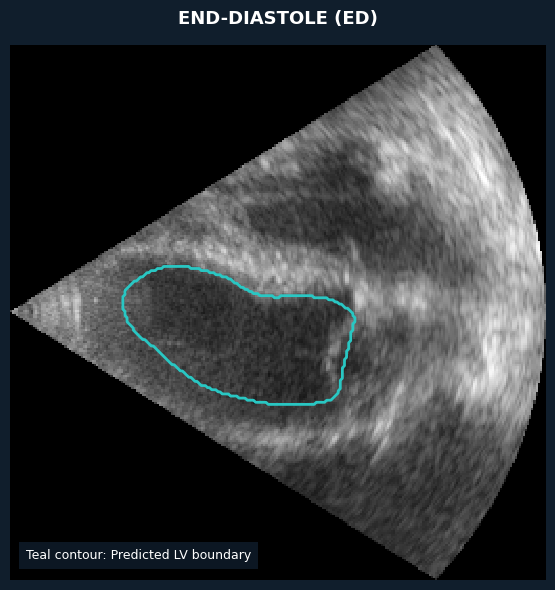

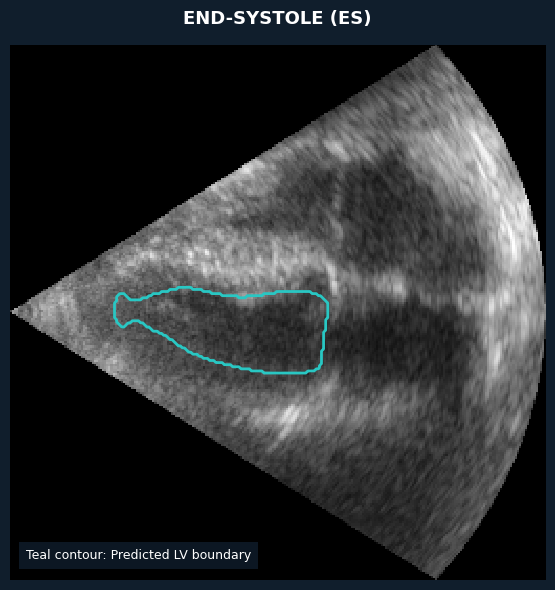

✓ Clinical ED/ES visualizations created.


In [ ]:
# ================================================================
# PHASE 5E — CELL 36
# CLINICAL ULTRASOUND VISUALIZATION
# ================================================================

import numpy as np
import matplotlib.pyplot as plt


def create_clinical_overlay(frame_result, phase):

    image = np.asarray(
        frame_result["processed_image"]
    )

    mask = np.asarray(
        frame_result["predicted_mask"],
        dtype=bool
    )

    fig, ax = plt.subplots(
        figsize=(6, 6),
        facecolor="#101e2c"
    )

    ax.set_facecolor("#101e2c")

    ax.imshow(
        image,
        cmap="gray",
        interpolation="nearest"
    )

    if mask.any():
        ax.contour(
            mask.astype(float),
            levels=[0.5],
            colors=["#29c7c3"],
            linewidths=2.0
        )

    phase_title = {
        "ED": "END-DIASTOLE (ED)",
        "ES": "END-SYSTOLE (ES)"
    }

    ax.set_title(
        phase_title.get(phase, phase),
        color="white",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.text(
        0.03,
        0.04,
        "Teal contour: Predicted LV boundary",
        transform=ax.transAxes,
        color="white",
        fontsize=9,
        bbox=dict(
            facecolor="#101e2c",
            alpha=0.8,
            edgecolor="none",
            pad=5
        )
    )

    ax.axis("off")
    fig.tight_layout()

    return fig


# Test using frozen patient0217 output
clinical_ed_fig = create_clinical_overlay(
    enhanced_output["segmentation"]["ED"],
    "ED"
)

clinical_es_fig = create_clinical_overlay(
    enhanced_output["segmentation"]["ES"],
    "ES"
)

display(clinical_ed_fig)
display(clinical_es_fig)

plt.close(clinical_ed_fig)
plt.close(clinical_es_fig)

print("✓ Clinical ED/ES visualizations created.")

In [ ]:
# ================================================================
# PHASE 5E — CELL 37
# CLINICAL INTERPRETATION PANEL
# ================================================================

from html import escape


def create_clinical_interpretation(interpretation):

    ef = interpretation["geometry_EF_pct"]

    geometry_band = interpretation["geometry_EF_band"]
    classifier_band = interpretation["classifier_EF_band"]

    agreement = interpretation["bands_agree"]

    agreement_text = (
        "The geometric EF band and learned classifier "
        "band agree."
        if agreement
        else
        "The geometric EF band and learned classifier "
        "band differ. Both outputs should be reviewed."
    )

    html = f"""
    <div class="info-panel">

        <h3>LV Functional Analysis</h3>

        <p>
            <b>Estimated Ejection Fraction:</b>
            {float(ef):.2f}%
        </p>

        <p>
            <b>Geometry-derived EF band:</b>
            {escape(str(geometry_band))}
        </p>

        <p>
            <b>Classifier-estimated EF band:</b>
            {escape(str(classifier_band))}
        </p>

        <p>{escape(agreement_text)}</p>

        <p style="font-size:13px;">
            EF is estimated using a simplified
            single-plane A4C area-length method.
            This result may differ from reference
            echocardiographic measurements.
        </p>

    </div>
    """

    return html


clinical_interpretation_html = (
    create_clinical_interpretation(
        enhanced_interpretation
    )
)

assert "LV Functional Analysis" in clinical_interpretation_html

print("✓ Clinical interpretation panel created.")

✓ Clinical interpretation panel created.


In [ ]:
# ================================================================
# PHASE 5E — CELL 38
# TECHNICAL REVIEW PANEL
# ================================================================

def create_technical_review_panel(assessment):

    warnings = assessment["warnings"]

    if warnings:

        items = "".join(
            f"<li>{escape(str(warning))}</li>"
            for warning in warnings
        )

        content = f"""
        <p>
            <b>Technical review recommended.</b>
            One or more predefined consistency
            checks were triggered.
        </p>
        <ul>{items}</ul>
        """

    else:

        content = """
        <p>
            No predefined technical consistency
            flags were triggered.
        </p>
        """

    return f"""
    <div class="review-panel">

        <h3>Technical Consistency Review</h3>

        {content}

        <p style="font-size:13px;">
            These are exploratory technical checks.
            No flags does not mean the EF estimate
            is accurate or clinically validated.
        </p>

    </div>
    """


clinical_review_html = create_technical_review_panel(
    enhanced_quality
)

assert "Technical Consistency Review" in clinical_review_html

print("✓ Technical review panel created.")

✓ Technical review panel created.


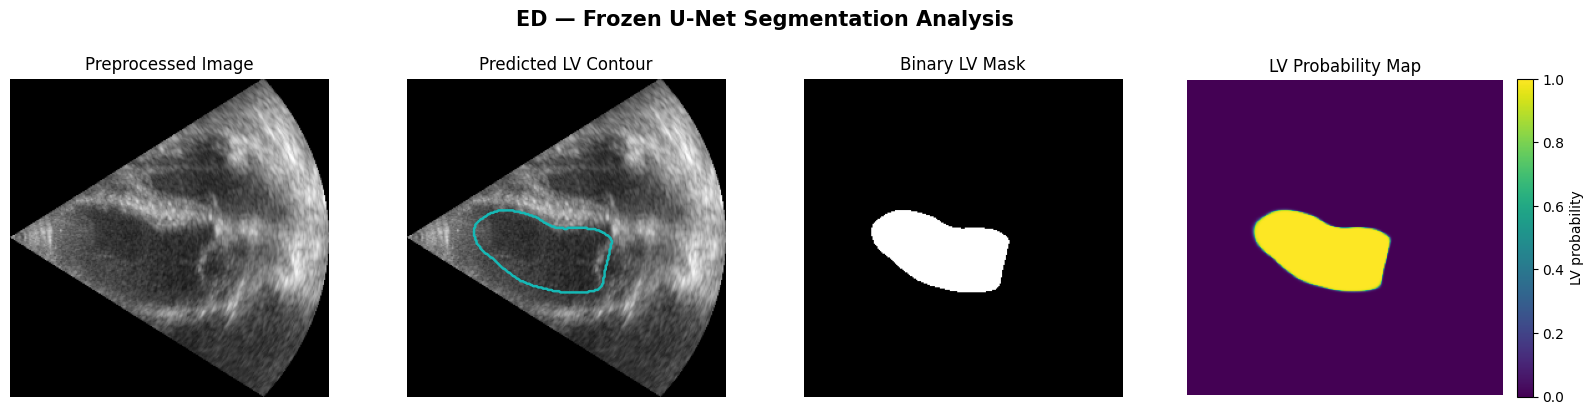

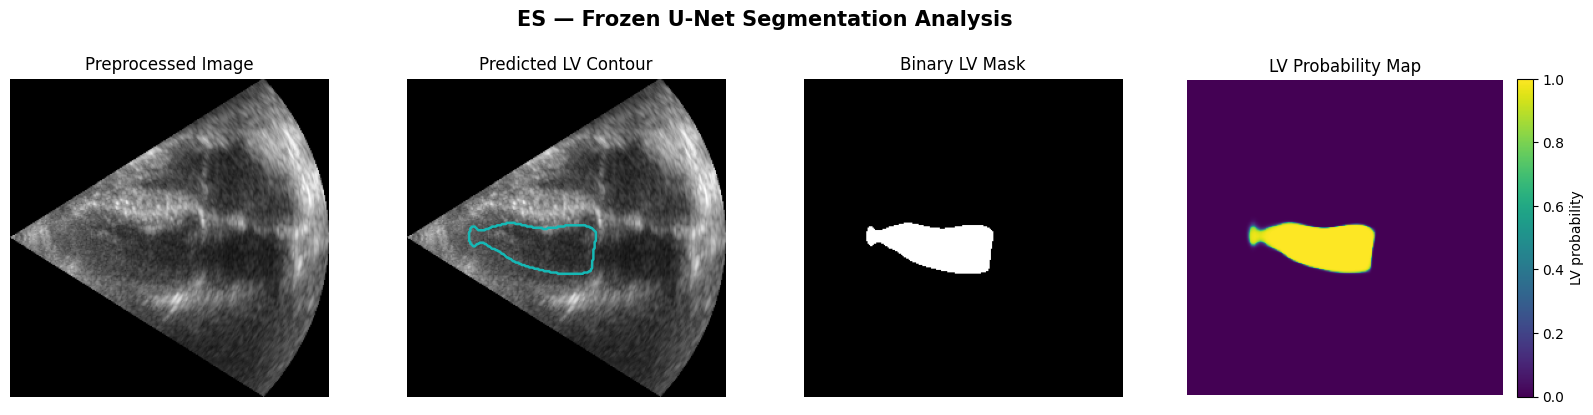

✓ ED four-panel segmentation visualization created.
✓ ES four-panel segmentation visualization created.
✓ Actual frozen probability masks used.


In [ ]:
# ================================================================
# PHASE 5E — CELL 39
# ML RESEARCH SEGMENTATION VISUALIZATIONS
# ================================================================

import numpy as np
import matplotlib.pyplot as plt


def create_ml_segmentation_figure(frame_result, phase):

    image = np.asarray(
        frame_result["processed_image"]
    )

    probability = np.asarray(
        frame_result["probability_mask"]
    )

    mask = np.asarray(
        frame_result["predicted_mask"],
        dtype=bool
    )

    assert image.shape == (256, 256)
    assert probability.shape == image.shape
    assert mask.shape == image.shape

    fig, axes = plt.subplots(
        1, 4,
        figsize=(16, 4.3)
    )

    # 1. Preprocessed ultrasound
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Preprocessed Image")

    # 2. Predicted LV boundary
    axes[1].imshow(image, cmap="gray")

    if mask.any():
        axes[1].contour(
            mask.astype(float),
            levels=[0.5],
            colors="#16b8b5",
            linewidths=1.8
        )

    axes[1].set_title("Predicted LV Contour")

    # 3. Binary segmentation
    axes[2].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Binary LV Mask")

    # 4. Probability heatmap
    heatmap = axes[3].imshow(
        probability,
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    axes[3].set_title("LV Probability Map")

    for ax in axes:
        ax.axis("off")

    fig.colorbar(
        heatmap,
        ax=axes[3],
        fraction=0.046,
        pad=0.04,
        label="LV probability"
    )

    fig.suptitle(
        f"{phase} — Frozen U-Net Segmentation Analysis",
        fontsize=15,
        fontweight="bold"
    )

    fig.subplots_adjust(
        left=0.02,
        right=0.98,
        bottom=0.08,
        top=0.82,
        wspace=0.15
    )

    return fig


ml_ed_fig = create_ml_segmentation_figure(
    enhanced_output["segmentation"]["ED"],
    "ED"
)

ml_es_fig = create_ml_segmentation_figure(
    enhanced_output["segmentation"]["ES"],
    "ES"
)

display(ml_ed_fig)
display(ml_es_fig)

plt.close(ml_ed_fig)
plt.close(ml_es_fig)

print("✓ ED four-panel segmentation visualization created.")
print("✓ ES four-panel segmentation visualization created.")
print("✓ Actual frozen probability masks used.")

In [ ]:
# ================================================================
# PHASE 5E — CELL 40
# FROZEN MODEL INFORMATION PANEL
# ================================================================

def create_model_information_panel():

    return """
    <div class="info-panel">

    <h3>Frozen Segmentation Model</h3>

    <table style="width:100%;line-height:2;">
      <tr><td><b>Architecture</b></td><td>Large U-Net</td></tr>
      <tr><td><b>Trainable parameters</b></td><td>7,759,521</td></tr>
      <tr><td><b>Input resolution</b></td><td>256 × 256</td></tr>
      <tr><td><b>Input modality</b></td><td>Grayscale A4C ultrasound</td></tr>
      <tr><td><b>Output</b></td><td>LV cavity probability mask</td></tr>
      <tr><td><b>Threshold</b></td><td>0.50</td></tr>
      <tr><td><b>Post-processing</b></td><td>Largest connected component + hole filling</td></tr>
      <tr><td><b>Held-out test Dice</b></td><td>0.9292</td></tr>
    </table>

    <p style="font-size:12px;">
    The Dice value is a dataset-level evaluation result,
    not a Dice score for the currently uploaded scan.
    </p>

    <hr>

    <h3>Frozen EF Classification Model</h3>

    <table style="width:100%;line-height:2;">
      <tr><td><b>Algorithm</b></td><td>StandardScaler + Logistic Regression</td></tr>
      <tr><td><b>Input</b></td><td>Eight predicted LV geometric measurements</td></tr>
      <tr><td><b>Output</b></td><td>Three EF-based bands</td></tr>
      <tr><td><b>Held-out test accuracy</b></td><td>70%</td></tr>
      <tr><td><b>Held-out macro-F1</b></td><td>0.6629</td></tr>
      <tr><td><b>Classifier scores</b></td><td>Uncalibrated</td></tr>
    </table>

    <p style="font-size:12px;">
    Performance values come from the frozen research
    evaluation. They are not patient-specific reliability
    or diagnostic accuracy estimates.
    </p>

    </div>
    """


model_information_html = create_model_information_panel()

assert "Large U-Net" in model_information_html
assert "Logistic Regression" in model_information_html
assert "0.9292" in model_information_html

print("✓ Frozen segmentation specifications included.")
print("✓ Frozen classifier specifications included.")
print("✓ Dataset-level performance identified.")
print("✓ Model information panel created.")

✓ Frozen segmentation specifications included.
✓ Frozen classifier specifications included.
✓ Dataset-level performance identified.
✓ Model information panel created.


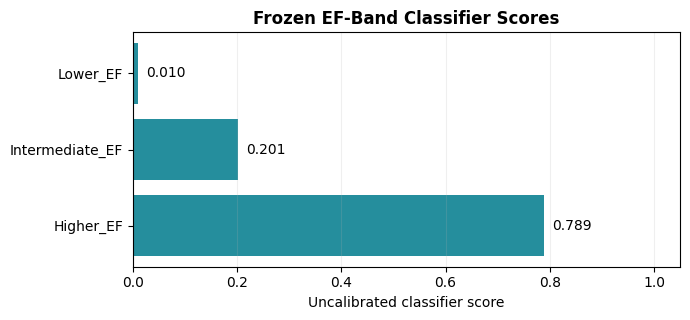

✓ Frozen classifier scores visualized.
✓ Scores explicitly labeled uncalibrated.


In [ ]:
# ================================================================
# PHASE 5E — CELL 41
# CLASSIFIER SCORE VISUALIZATION
# ================================================================

def create_classifier_score_chart(classification):

    scores = classification["class_scores"]

    labels = [
        "Lower_EF",
        "Intermediate_EF",
        "Higher_EF"
    ]

    values = [
        float(scores.get(label, 0.0))
        for label in labels
    ]

    fig, ax = plt.subplots(
        figsize=(7, 3.3)
    )

    bars = ax.barh(
        labels,
        values,
        color="#258e9d"
    )

    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Uncalibrated classifier score")

    ax.set_title(
        "Frozen EF-Band Classifier Scores",
        fontweight="bold"
    )

    for bar, value in zip(bars, values):
        ax.text(
            min(value + 0.015, 1.01),
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=10
        )

    ax.invert_yaxis()
    ax.grid(
        axis="x",
        alpha=0.2
    )

    fig.tight_layout()

    return fig


classifier_chart = create_classifier_score_chart(
    enhanced_output["classification"]
)

display(classifier_chart)
plt.close(classifier_chart)

print("✓ Frozen classifier scores visualized.")
print("✓ Scores explicitly labeled uncalibrated.")

In [ ]:
# ================================================================
# PHASE 5E — CELL 42
# TECHNICAL ANALYSIS PANEL
# ================================================================

from html import escape


def create_ml_technical_panel(assessment, interpretation):

    warnings = assessment["warnings"]

    warning_items = (
        "".join(
            f"<li>{escape(str(w))}</li>"
            for w in warnings
        )
        if warnings
        else "<li>No predefined technical flags triggered.</li>"
    )

    limitation_items = "".join(
        f"<li>{escape(str(item))}</li>"
        for item in interpretation["limitations"]
    )

    return f"""
    <div class="info-panel">

        <h3>Technical Analysis</h3>

        <p>
        <b>ED mask coverage:</b>
        {assessment['ED_mask_fraction'] * 100:.3f}%
        </p>

        <p>
        <b>ES mask coverage:</b>
        {assessment['ES_mask_fraction'] * 100:.3f}%
        </p>

        <p>
        <b>Geometry EF band:</b>
        {escape(interpretation['geometry_EF_band'])}
        </p>

        <p>
        <b>Classifier EF band:</b>
        {escape(interpretation['classifier_EF_band'])}
        </p>

        <p>
        <b>EF formula verification:</b>
        {escape(interpretation['EF_formula_status'])}
        </p>

        <h4>Technical Consistency Flags</h4>
        <ul>{warning_items}</ul>

        <h4>Interpretation Limitations</h4>
        <ul>{limitation_items}</ul>

        <p style="font-size:12px;">
        These checks do not measure segmentation accuracy
        or establish clinical reliability.
        </p>

    </div>
    """


ml_technical_html = create_ml_technical_panel(
    enhanced_quality,
    enhanced_interpretation
)

assert "Technical Analysis" in ml_technical_html
assert "Interpretation Limitations" in ml_technical_html

print("✓ Mask coverage included.")
print("✓ EF-band agreement information included.")
print("✓ Technical flags included.")
print("✓ Interpretation limitations included.")
print("\n✓ ML Research View components ready.")

✓ Mask coverage included.
✓ EF-band agreement information included.
✓ Technical flags included.
✓ Interpretation limitations included.

✓ ML Research View components ready.


In [ ]:
# ================================================================
# PHASE 5E — CELL 43
# SHARED DUAL-VIEW ANALYSIS HANDLER
# ================================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def run_dual_view_analysis(ed_file, es_file):

    # Run frozen inference once
    output, assessment, interpretation = enhanced_analysis(
        ed_file, es_file
    )

    segmentation = output["segmentation"]
    measurements = output["quantitative_measurements"]
    classification = output["classification"]

    # Clinical ultrasound images
    clinical_ed = create_clinical_overlay(
        segmentation["ED"], "ED"
    )

    clinical_es = create_clinical_overlay(
        segmentation["ES"], "ES"
    )

    # Clinical measurement cards
    cards = create_clinical_metrics(measurements)

    # Clinical interpretation
    clinical_interpretation = create_clinical_interpretation(
        interpretation
    )

    clinical_review = create_technical_review_panel(
        assessment
    )

    # ML research visualizations
    ml_ed = create_ml_segmentation_figure(
        segmentation["ED"], "ED"
    )

    ml_es = create_ml_segmentation_figure(
        segmentation["ES"], "ES"
    )

    classifier_fig = create_classifier_score_chart(
        classification
    )

    ml_technical = create_ml_technical_panel(
        assessment, interpretation
    )

    # Exact frozen quantitative values
    measurement_units = {
        "ED_area_mm2": "mm²",
        "ES_area_mm2": "mm²",
        "ED_length_mm": "mm",
        "ES_length_mm": "mm",
        "EDV_ml": "mL",
        "ESV_ml": "mL",
        "SV_ml": "mL",
        "EF_pct": "%"
    }

    measurements_df = pd.DataFrame([
        {
            "Measurement": key,
            "Value": float(measurements[key]),
            "Unit": unit
        }
        for key, unit in measurement_units.items()
    ])

    return (
        clinical_ed,
        clinical_es,
        *cards,
        clinical_interpretation,
        clinical_review,
        ml_ed,
        ml_es,
        classifier_fig,
        ml_technical,
        measurements_df
    )


print("✓ Shared dual-view handler created.")
print("✓ Frozen inference will run once per analysis.")
print("✓ Clinical and ML views use the same results.")

✓ Shared dual-view handler created.
✓ Frozen inference will run once per analysis.
✓ Clinical and ML views use the same results.


In [ ]:
# ================================================================
# PHASE 5E — CELL 44
# PROFESSIONAL DUAL-VIEW GRADIO DASHBOARD
# ================================================================

import gradio as gr

with gr.Blocks(
    title="ASCEND EchoLV — Assistive Analysis",
    theme=DASHBOARD_THEME,
    css=DASHBOARD_CSS
) as dual_view_demo:

    gr.HTML("""
    <div id="echolv-header">
        <h1>ASCEND | EchoLV Analysis</h1>
        <p>
            Computer Vision-Based Assistive Analysis
            of Left Ventricular Function — A4C
        </p>
        <p>
            Research prototype | Non-diagnostic
        </p>
    </div>
    """)

    gr.Markdown(
        "### Upload Echocardiography Images"
    )

    with gr.Group(elem_id="upload-panel"):

        with gr.Row():

            ed_input = gr.File(
                label="End-Diastole (ED) NIfTI",
                file_types=[".nii", ".gz"],
                type="filepath"
            )

            es_input = gr.File(
                label="End-Systole (ES) NIfTI",
                file_types=[".nii", ".gz"],
                type="filepath"
            )

        analyze_btn = gr.Button(
            "Analyze LV Function",
            variant="primary",
            size="lg"
        )

    with gr.Tabs():

        # ========================================================
        # CLINICAL VIEW
        # ========================================================

        with gr.Tab("Clinical View"):

            gr.Markdown(
                "## LV Functional Assessment"
            )

            gr.Markdown(
                "Estimated measurements derived from "
                "automated LV segmentation."
            )

            with gr.Row():

                ef_card = gr.HTML()
                edv_card = gr.HTML()
                esv_card = gr.HTML()
                sv_card = gr.HTML()

            gr.Markdown(
                "## Ultrasound Segmentation"
            )

            with gr.Row():

                clinical_ed_plot = gr.Plot(
                    label="End-Diastole"
                )

                clinical_es_plot = gr.Plot(
                    label="End-Systole"
                )

            with gr.Row():

                clinical_interpretation_panel = gr.HTML()

                clinical_review_panel = gr.HTML()

            gr.HTML("""
            <div class="disclaimer">
                <b>Important:</b>
                This system is an assistive research prototype.
                It does not provide a medical diagnosis.
                Estimated measurements require independent
                expert review and must not be used alone
                for clinical decisions.
            </div>
            """)

        # ========================================================
        # ML RESEARCH VIEW
        # ========================================================

        with gr.Tab("ML Research View"):

            gr.Markdown(
                "## Frozen Segmentation Analysis"
            )

            gr.Markdown(
                "Inspect preprocessing, predicted contours, "
                "binary masks, and pixel-level probability maps."
            )

            ml_ed_plot = gr.Plot(
                label="ED Segmentation Analysis"
            )

            ml_es_plot = gr.Plot(
                label="ES Segmentation Analysis"
            )

            gr.Markdown(
                "## Frozen Classifier Analysis"
            )

            with gr.Row():

                classifier_plot = gr.Plot(
                    label="Classifier Scores"
                )

                ml_technical_panel = gr.HTML()

            gr.Markdown(
                "## Quantitative Measurements"
            )

            measurements_table = gr.Dataframe(
                interactive=False,
                label="Frozen Quantitative Outputs"
            )

            gr.Markdown(
                "## Model Architecture and Evaluation"
            )

            gr.HTML(
                create_model_information_panel()
            )

    # Shared event
    analyze_btn.click(
        fn=run_dual_view_analysis,
        inputs=[
            ed_input,
            es_input
        ],
        outputs=[
            clinical_ed_plot,
            clinical_es_plot,
            ef_card,
            edv_card,
            esv_card,
            sv_card,
            clinical_interpretation_panel,
            clinical_review_panel,
            ml_ed_plot,
            ml_es_plot,
            classifier_plot,
            ml_technical_panel,
            measurements_table
        ]
    )

print("=" * 70)
print("ASCEND ECHOLV — PROFESSIONAL DUAL-VIEW DASHBOARD")
print("=" * 70)

print("✓ Shared ED/ES upload area")
print("✓ Clinical View tab")
print("✓ Four quantitative measurement cards")
print("✓ ED/ES segmentation overlays")
print("✓ Clinical interpretation and review panels")
print("✓ ML Research View tab")
print("✓ ED/ES four-panel segmentation analysis")
print("✓ Classifier score chart")
print("✓ Technical analysis and model information")
print("✓ Single frozen inference per analysis")
print("\n✓ Dual-view dashboard constructed.")

/tmp/ipykernel_522/1498506845.py:8: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


ASCEND ECHOLV — PROFESSIONAL DUAL-VIEW DASHBOARD
✓ Shared ED/ES upload area
✓ Clinical View tab
✓ Four quantitative measurement cards
✓ ED/ES segmentation overlays
✓ Clinical interpretation and review panels
✓ ML Research View tab
✓ ED/ES four-panel segmentation analysis
✓ Classifier score chart
✓ Technical analysis and model information
✓ Single frozen inference per analysis

✓ Dual-view dashboard constructed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 45
# DUAL-VIEW DASHBOARD REGRESSION TEST
# ================================================================

test_outputs = run_dual_view_analysis(
    str(required_files["ED image"]),
    str(required_files["ES image"])
)

assert len(test_outputs) == 13

# Verify all five plots
for index in [0, 1, 8, 9, 10]:
    assert isinstance(test_outputs[index], plt.Figure)

# Verify four metric cards
for index in [2, 3, 4, 5]:
    assert "metric-card" in test_outputs[index]

# Verify interpretation and technical panels
assert "LV Functional Analysis" in test_outputs[6]
assert "Technical Consistency Review" in test_outputs[7]
assert "Technical Analysis" in test_outputs[11]

# Verify frozen quantitative outputs
measurements_df = test_outputs[12]

assert isinstance(measurements_df, pd.DataFrame)
assert len(measurements_df) == 8

for key, frozen_column in mapping.items():

    actual = measurements_df.loc[
        measurements_df["Measurement"] == key,
        "Value"
    ].iloc[0]

    expected = float(patient_record[frozen_column])

    assert np.isclose(
        actual,
        expected,
        atol=1e-8,
        rtol=1e-9
    ), f"Frozen measurement mismatch: {key}"

for index in [0, 1, 8, 9, 10]:
    plt.close(test_outputs[index])

print("=" * 70)
print("DUAL-VIEW DASHBOARD VERIFICATION")
print("=" * 70)

print("Output components: 13/13 verified")
print("Visualization figures: 5/5 verified")
print("Measurement cards: 4/4 verified")
print("Frozen measurements: 8/8 matched")
print("Clinical interpretation: verified")
print("Technical review: verified")
print("ML technical analysis: verified")

print("\n✓ DUAL-VIEW REGRESSION TEST PASSED.")

DUAL-VIEW DASHBOARD VERIFICATION
Output components: 13/13 verified
Visualization figures: 5/5 verified
Measurement cards: 4/4 verified
Frozen measurements: 8/8 matched
Clinical interpretation: verified
Technical review: verified
ML technical analysis: verified

✓ DUAL-VIEW REGRESSION TEST PASSED.


In [ ]:
# ================================================================
# PHASE 5E — CELL 46
# LAUNCH PROFESSIONAL DUAL-VIEW DASHBOARD
# ================================================================

dual_view_demo.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0d268550c6c191762d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================================================
# PHASE 5E — CELL 47
# FIX DARK-THEME CONTRAST AND EMPTY-LOOKING PANELS
# ================================================================

DASHBOARD_CSS += """

/* Clinical interpretation panel */
.info-panel {
    background: #edf7fa !important;
    color: #17324a !important;
    border-left: 4px solid #1696a3 !important;
}

.info-panel *,
.info-panel h3,
.info-panel h4,
.info-panel p,
.info-panel li,
.info-panel td,
.info-panel b {
    color: #17324a !important;
}

/* Technical review panel */
.review-panel {
    background: #fff7e9 !important;
    color: #503b20 !important;
    border-left: 4px solid #d79a36 !important;
}

.review-panel *,
.review-panel h3,
.review-panel p,
.review-panel li,
.review-panel b {
    color: #503b20 !important;
}

/* Measurement cards */
.metric-card,
.metric-card * {
    color: #173d54 !important;
}

/* Disclaimer */
.disclaimer,
.disclaimer * {
    color: #34495e !important;
}

/* Model information tables */
.info-panel table {
    width: 100%;
    border-collapse: collapse;
}

.info-panel td {
    padding: 8px 12px;
    border-bottom: 1px solid #d3e3e8;
    vertical-align: top;
}

.info-panel h3 {
    margin-bottom: 14px;
}

"""

print("✓ Clinical interpretation contrast fixed.")
print("✓ Technical review contrast fixed.")
print("✓ Measurement card text contrast fixed.")
print("✓ Model information table styling fixed.")

✓ Clinical interpretation contrast fixed.
✓ Technical review contrast fixed.
✓ Measurement card text contrast fixed.
✓ Model information table styling fixed.


In [ ]:
# ================================================================
# PHASE 5E — CELL 48
# REBUILD MODEL INFORMATION PANEL
# ================================================================

def create_model_information_panel():

    return """
    <div class="info-panel">

        <h3>Segmentation Model</h3>

        <table>
            <tr>
                <td><b>Architecture</b></td>
                <td>Large U-Net</td>
            </tr>
            <tr>
                <td><b>Trainable Parameters</b></td>
                <td>7,759,521</td>
            </tr>
            <tr>
                <td><b>Input Resolution</b></td>
                <td>256 × 256</td>
            </tr>
            <tr>
                <td><b>Input Type</b></td>
                <td>Grayscale A4C Ultrasound</td>
            </tr>
            <tr>
                <td><b>Output</b></td>
                <td>LV Cavity Segmentation</td>
            </tr>
            <tr>
                <td><b>Post-processing</b></td>
                <td>Largest Component + Hole Filling</td>
            </tr>
            <tr>
                <td><b>Held-out Test Dice</b></td>
                <td>0.9292</td>
            </tr>
        </table>

        <h3 style="margin-top:25px;">
            EF Classification Model
        </h3>

        <table>
            <tr>
                <td><b>Algorithm</b></td>
                <td>StandardScaler + Logistic Regression</td>
            </tr>
            <tr>
                <td><b>Input Features</b></td>
                <td>Eight LV Geometric Measurements</td>
            </tr>
            <tr>
                <td><b>Classes</b></td>
                <td>Lower, Intermediate, Higher EF</td>
            </tr>
            <tr>
                <td><b>Held-out Test Accuracy</b></td>
                <td>70%</td>
            </tr>
            <tr>
                <td><b>Held-out Macro-F1</b></td>
                <td>0.6629</td>
            </tr>
        </table>

        <p style="margin-top:20px;font-size:13px;">
            These are dataset-level research evaluation metrics.
            They are not performance guarantees for the
            uploaded scan.
        </p>

    </div>
    """


model_information_html = create_model_information_panel()

assert "Large U-Net" in model_information_html
assert "Logistic Regression" in model_information_html

print("✓ Model information panel rebuilt.")

✓ Model information panel rebuilt.


In [ ]:
# ================================================================
# PHASE 5E — CELL 49
# RELAUNCH CORRECTED DASHBOARD
# ================================================================

dual_view_demo.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://602de168497421e861.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 50
# ENHANCED EF CLASSIFICATION PANEL
# ================================================================

from html import escape
import numpy as np


def create_enhanced_ef_panel(interpretation):

    ef = float(interpretation["geometry_EF_pct"])

    geometry_band = interpretation["geometry_EF_band"]
    classifier_band = interpretation["classifier_EF_band"]

    bands_agree = bool(interpretation["bands_agree"])

    labels = {
        "Lower_EF": "Lower EF Band",
        "Intermediate_EF": "Intermediate EF Band",
        "Higher_EF": "Higher EF Band"
    }

    geometry_label = labels.get(
        geometry_band, "Unknown EF Band"
    )

    classifier_label = labels.get(
        classifier_band, "Unknown EF Band"
    )

    if bands_agree:
        agreement_message = (
            "The geometric EF category and the "
            "learned classifier category agree."
        )
    else:
        agreement_message = (
            "The geometric EF category and the "
            "learned classifier category differ. "
            "Review the segmentation and measurements."
        )

    ef_display = (
        f"{ef:.2f}%"
        if np.isfinite(ef)
        else "Unavailable"
    )

    return f"""
    <div class="info-panel" style="color:#17324a;">

        <h2 style="color:#17324a;">
            Left Ventricular EF Assessment
        </h2>

        <p style="font-size:14px;color:#52677a;">
            Estimated using the simplified
            single-plane A4C area-length method.
        </p>

        <div style="
            font-size:40px;
            font-weight:800;
            color:#173d54;
            margin:15px 0;
        ">
            {ef_display}
        </div>

        <div style="
            background:#ffffff;
            padding:15px;
            border-radius:10px;
            margin-bottom:12px;
            color:#17324a;
        ">
            <b>Geometry-derived category:</b>
            {escape(geometry_label)}
        </div>

        <div style="
            background:#ffffff;
            padding:15px;
            border-radius:10px;
            margin-bottom:12px;
            color:#17324a;
        ">
            <b>ML classifier category:</b>
            {escape(classifier_label)}
        </div>

        <p style="color:#17324a;">
            {escape(agreement_message)}
        </p>

        <p style="font-size:12px;color:#52677a;">
            Research-defined thresholds:
            Lower ≤40%, Intermediate >40% and <50%,
            Higher ≥50%.
            These categories are not clinical diagnoses.
            Agreement does not establish accuracy.
        </p>

    </div>
    """


# Verify using frozen patient0217 output
enhanced_ef_html = create_enhanced_ef_panel(
    enhanced_interpretation
)

assert "Left Ventricular EF Assessment" in enhanced_ef_html
assert "Higher EF Band" in enhanced_ef_html

print("✓ Enhanced EF assessment panel created.")
print("✓ Geometry-derived and ML classifier bands separated.")
print("✓ Research-defined EF thresholds documented.")

✓ Enhanced EF assessment panel created.
✓ Geometry-derived and ML classifier bands separated.
✓ Research-defined EF thresholds documented.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 51
# DETAILED LV MEASUREMENT PANEL
# ================================================================

def create_detailed_measurements_panel(measurements):

    measurement_details = [
        (
            "ED_area_mm2",
            "ED LV Cavity Area",
            "mm²",
            "Predicted LV cavity area at end-diastole."
        ),
        (
            "ES_area_mm2",
            "ES LV Cavity Area",
            "mm²",
            "Predicted LV cavity area at end-systole."
        ),
        (
            "ED_length_mm",
            "ED Long-Axis Length",
            "mm",
            "Estimated LV long-axis length at end-diastole."
        ),
        (
            "ES_length_mm",
            "ES Long-Axis Length",
            "mm",
            "Estimated LV long-axis length at end-systole."
        ),
        (
            "EDV_ml",
            "End-Diastolic Volume",
            "mL",
            "Estimated LV volume at end-diastole."
        ),
        (
            "ESV_ml",
            "End-Systolic Volume",
            "mL",
            "Estimated LV volume at end-systole."
        ),
        (
            "SV_ml",
            "Stroke Volume",
            "mL",
            "Calculated as EDV minus ESV."
        ),
        (
            "EF_pct",
            "Ejection Fraction",
            "%",
            "Calculated as 100 × (EDV − ESV) / EDV."
        )
    ]

    rows = []

    for key, name, unit, explanation in measurement_details:

        value = float(measurements[key])

        rows.append(f"""
        <tr>
            <td>{escape(name)}</td>
            <td><b>{value:.2f} {escape(unit)}</b></td>
            <td>{escape(explanation)}</td>
        </tr>
        """)

    return f"""
    <div class="info-panel">

        <h3>Detailed LV Geometric Measurements</h3>

        <table style="
            width:100%;
            border-collapse:collapse;
            color:#17324a;
        ">

            <thead>
                <tr>
                    <th style="text-align:left;padding:10px;">
                        Measurement
                    </th>
                    <th style="text-align:left;padding:10px;">
                        Value
                    </th>
                    <th style="text-align:left;padding:10px;">
                        Description
                    </th>
                </tr>
            </thead>

            <tbody>
                {''.join(rows)}
            </tbody>

        </table>

        <p style="
            font-size:12px;
            margin-top:15px;
            color:#52677a;
        ">
            All measurements are generated from
            predicted LV segmentation masks.
            The volume estimates use the simplified
            single-plane A4C area-length method.
        </p>

    </div>
    """


detailed_measurements_html = create_detailed_measurements_panel(
    enhanced_output["quantitative_measurements"]
)

assert "Detailed LV Geometric Measurements" in detailed_measurements_html
assert "Stroke Volume" in detailed_measurements_html

print("✓ Eight LV measurements included.")
print("✓ Measurement descriptions included.")
print("✓ Detailed measurements panel created.")

✓ Eight LV measurements included.
✓ Measurement descriptions included.
✓ Detailed measurements panel created.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 52
# CLINICAL ANALYSIS REVIEW NOTICES
# ================================================================

def create_analysis_review_panel(assessment):

    warnings = assessment["warnings"]

    if warnings:

        heading = "Technical Review Recommended"

        description = (
            "One or more predefined technical "
            "consistency checks were triggered."
        )

        warning_list = "".join(
            f"<li>{escape(str(warning))}</li>"
            for warning in warnings
        )

        warning_section = f"<ul>{warning_list}</ul>"

    else:

        heading = "No Technical Flags Detected"

        description = (
            "The analysis did not trigger the "
            "predefined technical consistency checks."
        )

        warning_section = """
        <p>
            This does not confirm segmentation accuracy,
            EF accuracy, or clinical reliability.
        </p>
        """

    return f"""
    <div class="review-panel">

        <h3>{escape(heading)}</h3>

        <p>{escape(description)}</p>

        {warning_section}

        <hr>

        <p style="font-size:13px;">
            <b>Important:</b>
            These are exploratory technical checks,
            not clinically validated safety checks.
            Predicted contours and measurements
            require independent expert review.
        </p>

    </div>
    """


review_panel_html = create_analysis_review_panel(
    enhanced_quality
)

assert "Technical Flags" in review_panel_html

print("✓ Technical review notice created.")
print("✓ No unsupported accuracy claims.")
print("✓ Independent expert review emphasized.")

✓ Technical review notice created.
✓ No unsupported accuracy claims.
✓ Independent expert review emphasized.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 53 (CORRECTED)
# VERIFY CLINICAL ENHANCEMENTS
# ================================================================

import numpy as np
from IPython.display import display, HTML

# 1. Compare EF numerically against frozen measurements
actual_ef = float(
    enhanced_interpretation["geometry_EF_pct"]
)

frozen_ef = float(
    enhanced_output["quantitative_measurements"]["EF_pct"]
)

assert np.isclose(
    actual_ef,
    frozen_ef,
    rtol=1e-9,
    atol=1e-8
), "EF mismatch with frozen measurements"

# 2. Check the dynamically formatted EF is displayed
expected_ef_text = f"{actual_ef:.2f}%"

assert expected_ef_text in enhanced_ef_html, (
    f"Expected {expected_ef_text} in EF panel"
)

# 3. Check all eight measurements exist
measurement_keys = [
    "ED_area_mm2",
    "ES_area_mm2",
    "ED_length_mm",
    "ES_length_mm",
    "EDV_ml",
    "ESV_ml",
    "SV_ml",
    "EF_pct"
]

for key in measurement_keys:
    assert key in enhanced_output["quantitative_measurements"]

# 4. Verify panel contents
assert "Left Ventricular EF Assessment" in enhanced_ef_html
assert "Detailed LV Geometric Measurements" in detailed_measurements_html
assert "independent expert review" in review_panel_html.lower()

print("=" * 70)
print("PHASE 5E-F — CLINICAL COMPONENT VERIFICATION")
print("=" * 70)

print(f"Frozen EF: {frozen_ef:.6f}%")
print(f"Displayed EF: {expected_ef_text}")

print("\nEF classification panel: PASSED")
print("Detailed LV measurements: PASSED")
print("Technical review notices: PASSED")
print("Frozen EF consistency: PASSED")

print("\nDisplaying enhanced EF assessment:")
display(HTML(enhanced_ef_html))

print("\nDisplaying detailed LV measurements:")
display(HTML(detailed_measurements_html))

print("\nDisplaying technical review notice:")
display(HTML(review_panel_html))

print("\n✓ Clinical component verification PASSED.")

PHASE 5E-F — CLINICAL COMPONENT VERIFICATION
Frozen EF: 61.794598%
Displayed EF: 61.79%

EF classification panel: PASSED
Detailed LV measurements: PASSED
Technical review notices: PASSED
Frozen EF consistency: PASSED

Displaying enhanced EF assessment:



Displaying detailed LV measurements:


Measurement,Value,Description
ED LV Cavity Area,2703.21 mm²,Predicted LV cavity area at end-diastole.
ES LV Cavity Area,1571.04 mm²,Predicted LV cavity area at end-systole.
ED Long-Axis Length,77.15 mm,Estimated LV long-axis length at end-diastole.
ES Long-Axis Length,68.20 mm,Estimated LV long-axis length at end-systole.
End-Diastolic Volume,80.40 mL,Estimated LV volume at end-diastole.
End-Systolic Volume,30.72 mL,Estimated LV volume at end-systole.
Stroke Volume,49.68 mL,Calculated as EDV minus ESV.
Ejection Fraction,61.79 %,Calculated as 100 × (EDV − ESV) / EDV.



Displaying technical review notice:



✓ Clinical component verification PASSED.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 54
# UPDATED DUAL-VIEW ANALYSIS HANDLER
# ================================================================

def run_dual_view_analysis_v2(ed_file, es_file):

    # Frozen inference is executed once
    output, assessment, interpretation = enhanced_analysis(
        ed_file, es_file
    )

    segmentation = output["segmentation"]
    measurements = output["quantitative_measurements"]
    classification = output["classification"]

    # Clinical visualizations
    clinical_ed = create_clinical_overlay(
        segmentation["ED"], "ED"
    )

    clinical_es = create_clinical_overlay(
        segmentation["ES"], "ES"
    )

    # Four clinical measurement cards
    cards = create_clinical_metrics(measurements)

    # New clinical panels
    ef_panel = create_enhanced_ef_panel(interpretation)

    review_panel = create_analysis_review_panel(assessment)

    detailed_panel = create_detailed_measurements_panel(
        measurements
    )

    # ML research visualizations
    ml_ed = create_ml_segmentation_figure(
        segmentation["ED"], "ED"
    )

    ml_es = create_ml_segmentation_figure(
        segmentation["ES"], "ES"
    )

    classifier_fig = create_classifier_score_chart(
        classification
    )

    ml_technical = create_ml_technical_panel(
        assessment, interpretation
    )

    units = {
        "ED_area_mm2": "mm²",
        "ES_area_mm2": "mm²",
        "ED_length_mm": "mm",
        "ES_length_mm": "mm",
        "EDV_ml": "mL",
        "ESV_ml": "mL",
        "SV_ml": "mL",
        "EF_pct": "%"
    }

    measurements_df = pd.DataFrame([
        {
            "Measurement": key,
            "Value": float(measurements[key]),
            "Unit": unit
        }
        for key, unit in units.items()
    ])

    return (
        clinical_ed,
        clinical_es,
        *cards,
        ef_panel,
        review_panel,
        detailed_panel,
        ml_ed,
        ml_es,
        classifier_fig,
        ml_technical,
        measurements_df
    )


print("✓ Updated dual-view analysis handler created.")
print("✓ New EF classification panel connected.")
print("✓ Detailed measurements connected.")
print("✓ Improved review notices connected.")
print("✓ Existing ML Research View preserved.")

✓ Updated dual-view analysis handler created.
✓ New EF classification panel connected.
✓ Detailed measurements connected.
✓ Improved review notices connected.
✓ Existing ML Research View preserved.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 55
# UPDATED HANDLER REGRESSION TEST
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

v2_outputs = run_dual_view_analysis_v2(
    str(required_files["ED image"]),
    str(required_files["ES image"])
)

assert len(v2_outputs) == 14

# Five figures
for i in [0, 1, 9, 10, 11]:
    assert isinstance(v2_outputs[i], plt.Figure)

# Four metric cards
for i in [2, 3, 4, 5]:
    assert "metric-card" in v2_outputs[i]

# Enhanced clinical panels
assert "Left Ventricular EF Assessment" in v2_outputs[6]
assert "Technical Flags" in v2_outputs[7]
assert "Detailed LV Geometric Measurements" in v2_outputs[8]

# ML technical panel
assert "Technical Analysis" in v2_outputs[12]

# Frozen quantitative measurements
measurements_v2 = v2_outputs[13]

assert isinstance(measurements_v2, pd.DataFrame)
assert len(measurements_v2) == 8

for key, frozen_column in mapping.items():

    actual = float(
        measurements_v2.loc[
            measurements_v2["Measurement"] == key,
            "Value"
        ].iloc[0]
    )

    expected = float(patient_record[frozen_column])

    assert np.isclose(
        actual,
        expected,
        rtol=1e-9,
        atol=1e-8
    ), f"Frozen measurement mismatch: {key}"

for i in [0, 1, 9, 10, 11]:
    plt.close(v2_outputs[i])

print("=" * 70)
print("PHASE 5E-F — UPDATED DASHBOARD VERIFICATION")
print("=" * 70)

print("Output components: 14/14 verified")
print("Visualization figures: 5/5 verified")
print("Clinical measurement cards: 4/4 verified")
print("Enhanced EF classification: verified")
print("Analysis review notices: verified")
print("Detailed LV measurements: verified")
print("ML Research View: verified")
print("Frozen quantitative measurements: 8/8 matched")

print("\n✓ UPDATED DASHBOARD REGRESSION TEST PASSED.")

PHASE 5E-F — UPDATED DASHBOARD VERIFICATION
Output components: 14/14 verified
Visualization figures: 5/5 verified
Clinical measurement cards: 4/4 verified
Enhanced EF classification: verified
Analysis review notices: verified
Detailed LV measurements: verified
ML Research View: verified
Frozen quantitative measurements: 8/8 matched

✓ UPDATED DASHBOARD REGRESSION TEST PASSED.


In [ ]:

# ================================================================
# PHASE 5E-F — CELL 56 (UPDATED)
# BUILD ENHANCED DUAL-VIEW DASHBOARD
# ================================================================

import gradio as gr

# Make sure Cells 58–63 have been executed before this cell.
assert callable(run_dual_view_analysis_v3)
assert callable(create_model_information_panel)

with gr.Blocks(
    title="ASCEND EchoLV — Assistive LV Analysis",
    theme=DASHBOARD_THEME,
    css=DASHBOARD_CSS
) as dual_view_demo_v2:

    # ============================================================
    # APPLICATION HEADER
    # ============================================================

    gr.HTML("""
    <div style="
        background:linear-gradient(120deg,#17324a,#145a67);
        color:white;
        padding:26px;
        border-radius:16px;
        margin-bottom:15px;
    ">
        <h1 style="
            color:white;
            margin:0;
            font-size:30px;
            font-weight:800;
        ">
            ASCEND EchoLV
        </h1>

        <p style="
            color:#d9e8ee;
            font-size:16px;
            margin:8px 0;
        ">
            AI-Assisted Left Ventricular Analysis
        </p>

        <p style="
            color:#b9d3dc;
            font-size:13px;
            margin:0;
        ">
            A4C Echocardiography |
            Research Prototype |
            Non-Diagnostic
        </p>
    </div>
    """)

    # ============================================================
    # UPLOAD SECTION
    # ============================================================

    with gr.Group():

        gr.Markdown("### Upload Echocardiography Images")

        gr.Markdown(
            "Upload the corresponding end-diastolic (ED) "
            "and end-systolic (ES) A4C NIfTI images."
        )

        with gr.Row():

            ed_input_v2 = gr.File(
                label="End-Diastolic (ED) NIfTI Image",
                file_types=[".nii", ".gz"],
                type="filepath"
            )

            es_input_v2 = gr.File(
                label="End-Systolic (ES) NIfTI Image",
                file_types=[".nii", ".gz"],
                type="filepath"
            )

        analyze_btn_v2 = gr.Button(
            "Analyze LV Function",
            variant="primary",
            size="lg"
        )

    # ============================================================
    # DUAL-VIEW DASHBOARD
    # ============================================================

    with gr.Tabs():

        # ========================================================
        # CLINICAL VIEW
        # ========================================================

        with gr.Tab("Clinical View"):

            gr.Markdown(
                "## Left Ventricular Functional Summary"
            )

            gr.Markdown(
                "Key geometric estimates derived from "
                "the predicted LV segmentation."
            )

            # Four primary clinical metrics
            with gr.Row():

                ef_card_v2 = gr.HTML()
                edv_card_v2 = gr.HTML()
                esv_card_v2 = gr.HTML()
                sv_card_v2 = gr.HTML()

            # ED/ES ultrasound overlays
            gr.Markdown(
                "## ED/ES Segmentation Inspection"
            )

            gr.Markdown(
                "Teal contours indicate the predicted "
                "left ventricular cavity boundary."
            )

            with gr.Row(equal_height=True):

                clinical_ed_plot_v2 = gr.Plot(
                    label="End-Diastolic LV",
                    format="png"
                )

                clinical_es_plot_v2 = gr.Plot(
                    label="End-Systolic LV",
                    format="png"
                )

            # Enhanced EF classification
            gr.Markdown(
                "## EF Assessment and Classification"
            )

            ef_panel_v2 = gr.HTML()

            # Compact technical review
            gr.Markdown(
                "## Analysis Review Notices"
            )

            review_panel_v2 = gr.HTML()

            # Detailed clinical measurements
            with gr.Accordion(
                "Detailed LV Geometric Measurements",
                open=False
            ):

                detailed_panel_v2 = gr.HTML()

            gr.Markdown("""
            **Research-use limitation:** This is an
            experimental, non-diagnostic application.
            Technical consistency checks do not establish
            segmentation accuracy, EF accuracy, or
            clinical reliability. All results require
            independent expert review.
            """)

        # ========================================================
        # ML RESEARCH VIEW
        # ========================================================

        with gr.Tab("ML Research View"):

            gr.Markdown(
                "## Frozen U-Net Segmentation Analysis"
            )

            gr.Markdown(
                "Inspect the preprocessed ultrasound, "
                "predicted LV contour, binary segmentation, "
                "and probability map for each cardiac phase."
            )

            # Enlarged 2x2 segmentation figures
            with gr.Row(equal_height=True):

                ml_ed_plot_v2 = gr.Plot(
                    label="ED Segmentation Analysis",
                    format="png"
                )

                ml_es_plot_v2 = gr.Plot(
                    label="ES Segmentation Analysis",
                    format="png"
                )

            # Classifier scores
            gr.Markdown(
                "## EF Classifier Scores"
            )

            gr.Markdown(
                "These scores are uncalibrated model "
                "outputs and should not be interpreted "
                "as clinical confidence."
            )

            classifier_plot_v2 = gr.Plot(
                label="Frozen EF-Band Classifier",
                format="png"
            )

            # Technical consistency details
            gr.Markdown(
                "## Technical Analysis"
            )

            ml_technical_panel_v2 = gr.HTML()

            # Formatted quantitative measurements
            gr.Markdown(
                "## Quantitative LV Measurements"
            )

            gr.Markdown(
                "Values are rounded for display only. "
                "The frozen calculations retain their "
                "original precision."
            )

            measurements_table_v2 = gr.Dataframe(
                headers=[
                    "Measurement",
                    "Value",
                    "Unit"
                ],
                datatype=[
                    "str",
                    "str",
                    "str"
                ],
                interactive=False,
                wrap=True
            )

            # Frozen model documentation
            gr.Markdown(
                "## Model Architecture and Evaluation"
            )

            gr.HTML(
                value=create_model_information_panel()
            )

    # ============================================================
    # CONNECT UPDATED INFERENCE HANDLER
    # ============================================================

    analyze_btn_v2.click(
        fn=run_dual_view_analysis_v3,
        inputs=[
            ed_input_v2,
            es_input_v2
        ],
        outputs=[
            clinical_ed_plot_v2,       # 0
            clinical_es_plot_v2,       # 1
            ef_card_v2,                # 2
            edv_card_v2,               # 3
            esv_card_v2,               # 4
            sv_card_v2,                # 5
            ef_panel_v2,               # 6
            review_panel_v2,           # 7
            detailed_panel_v2,         # 8
            ml_ed_plot_v2,             # 9
            ml_es_plot_v2,             # 10
            classifier_plot_v2,        # 11
            ml_technical_panel_v2,     # 12
            measurements_table_v2      # 13
        ],
        show_progress="full"
    )

print("=" * 65)
print("ASCEND EchoLV — ENHANCED DASHBOARD")
print("=" * 65)

print("✓ Clinical View connected.")
print("✓ Improved EF classification connected.")
print("✓ Compact review notices connected.")
print("✓ Detailed LV measurements connected.")
print("✓ Enlarged ML segmentation figures connected.")
print("✓ Formatted measurement table connected.")
print("✓ Model architecture information included.")
print("✓ All 14 output components connected.")
print("✓ Frozen inference pipeline preserved.")
print("\nDashboard ready to launch.")


/tmp/ipykernel_522/1970822944.py:12: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


ASCEND EchoLV — ENHANCED DASHBOARD
✓ Clinical View connected.
✓ Improved EF classification connected.
✓ Compact review notices connected.
✓ Detailed LV measurements connected.
✓ Enlarged ML segmentation figures connected.
✓ Formatted measurement table connected.
✓ Model architecture information included.
✓ All 14 output components connected.
✓ Frozen inference pipeline preserved.

Dashboard ready to launch.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 57
# LAUNCH ENHANCED DASHBOARD
# ================================================================

dual_view_demo_v2.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a81f20eefc0d2940f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 58
# COMPACT TECHNICAL REVIEW PANEL
# ================================================================

from html import escape

def create_analysis_review_panel(assessment):

    warnings = assessment.get("warnings", [])

    if warnings:
        title = "Technical Review Recommended"
        message = (
            "One or more predefined consistency checks "
            "require review."
        )

        warning_html = "".join(
            f"<li>{escape(str(w))}</li>"
            for w in warnings
        )

        details = f"<ul>{warning_html}</ul>"

        border_color = "#d49a40"
        background_color = "#fff6e8"

    else:
        title = "No Technical Flags Detected"
        message = (
            "No predefined technical inconsistencies "
            "were detected."
        )

        details = ""

        border_color = "#7c9aa7"
        background_color = "#eef5f8"

    return f"""
    <div style="
        background:{background_color};
        border-left:4px solid {border_color};
        border-radius:10px;
        padding:16px 20px;
        color:#17324a;
        font-family:Arial,sans-serif;
    ">
        <div style="
            font-size:16px;
            font-weight:700;
            color:#17324a;
            margin-bottom:6px;
        ">
            {escape(title)}
        </div>

        <p style="
            margin:0 0 8px;
            color:#334e63;
            font-size:13px;
        ">
            {escape(message)}
        </p>

        {details}

        <p style="
            margin:8px 0 0;
            font-size:12px;
            color:#52677a;
        ">
            Technical checks are exploratory.
            Absence of flags does not establish
            measurement accuracy or clinical reliability.
            Independent expert review is required.
        </p>
    </div>
    """

print("✓ Compact technical review panel ready.")

✓ Compact technical review panel ready.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 59
# ML MEASUREMENT TABLE PRESENTATION
# ================================================================

def format_measurements_for_display(df):

    formatted = df.copy()

    formatted["Value"] = formatted["Value"].apply(
        lambda x: f"{float(x):.2f}"
    )

    names = {
        "ED_area_mm2": "ED LV Cavity Area",
        "ES_area_mm2": "ES LV Cavity Area",
        "ED_length_mm": "ED Long-Axis Length",
        "ES_length_mm": "ES Long-Axis Length",
        "EDV_ml": "End-Diastolic Volume",
        "ESV_ml": "End-Systolic Volume",
        "SV_ml": "Stroke Volume",
        "EF_pct": "Ejection Fraction"
    }

    formatted["Measurement"] = formatted[
        "Measurement"
    ].replace(names)

    return formatted


# Preview using the previously tested outputs
formatted_preview = format_measurements_for_display(
    v2_outputs[13]
)

display(formatted_preview)

print("✓ Measurement display formatting ready.")
print("✓ Frozen measurement values remain unchanged.")

,Measurement,Value,Unit
0,ED LV Cavity Area,2703.21,mm²
1,ES LV Cavity Area,1571.04,mm²
2,ED Long-Axis Length,77.15,mm
3,ES Long-Axis Length,68.20,mm
4,End-Diastolic Volume,80.40,mL
5,End-Systolic Volume,30.72,mL
6,Stroke Volume,49.68,mL
7,Ejection Fraction,61.79,%


✓ Measurement display formatting ready.
✓ Frozen measurement values remain unchanged.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 60
# IMPROVED EF CLASSIFICATION PRESENTATION
# ================================================================

from html import escape
import numpy as np

def create_enhanced_ef_panel(interpretation):

    ef = float(interpretation["geometry_EF_pct"])

    geometry_band = str(
        interpretation["geometry_EF_band"]
    )

    classifier_band = str(
        interpretation["classifier_EF_band"]
    )

    bands_agree = bool(
        interpretation["bands_agree"]
    )

    labels = {
        "Lower_EF": "Lower EF",
        "Intermediate_EF": "Intermediate EF",
        "Higher_EF": "Higher EF"
    }

    geometry_label = labels.get(
        geometry_band, "Unavailable"
    )

    classifier_label = labels.get(
        classifier_band, "Unavailable"
    )

    if bands_agree:
        agreement_text = "Categories Agree"
        agreement_description = (
            "The geometry-derived EF band and "
            "ML classifier band are the same."
        )
        agreement_color = "#dceeea"
    else:
        agreement_text = "Categories Differ"
        agreement_description = (
            "The geometry-derived and ML classifier "
            "bands differ. Review the segmentation "
            "and quantitative measurements."
        )
        agreement_color = "#fff0dc"

    ef_display = (
        f"{ef:.2f}%"
        if np.isfinite(ef)
        else "Unavailable"
    )

    return f"""
    <div style="
        background:#edf6fa;
        border-left:4px solid #159b9b;
        border-radius:12px;
        padding:20px;
        color:#17324a;
        font-family:Arial,sans-serif;
    ">

        <h3 style="color:#17324a;margin:0 0 8px;">
            EF Assessment
        </h3>

        <p style="color:#52677a;font-size:13px;">
            Single-plane A4C geometric estimate
        </p>

        <div style="
            font-size:34px;
            font-weight:800;
            color:#17324a;
            margin:10px 0 18px;
        ">
            {ef_display}
        </div>

        <div style="
            display:grid;
            grid-template-columns:
                repeat(auto-fit,minmax(180px,1fr));
            gap:12px;
        ">

            <div style="
                background:white;
                border:1px solid #dbe7ed;
                padding:15px;
                border-radius:10px;
            ">
                <div style="
                    font-size:12px;
                    color:#52677a;
                    margin-bottom:6px;
                ">
                    Geometry-Derived Category
                </div>

                <div style="
                    font-size:19px;
                    font-weight:700;
                    color:#17324a;
                ">
                    {escape(geometry_label)}
                </div>
            </div>

            <div style="
                background:white;
                border:1px solid #dbe7ed;
                padding:15px;
                border-radius:10px;
            ">
                <div style="
                    font-size:12px;
                    color:#52677a;
                    margin-bottom:6px;
                ">
                    ML Classifier Category
                </div>

                <div style="
                    font-size:19px;
                    font-weight:700;
                    color:#17324a;
                ">
                    {escape(classifier_label)}
                </div>
            </div>

        </div>

        <div style="
            background:{agreement_color};
            border-radius:8px;
            padding:12px;
            margin-top:14px;
            color:#17324a;
        ">
            <strong>{agreement_text}</strong>

            <div style="font-size:12px;margin-top:4px;">
                {escape(agreement_description)}
            </div>
        </div>

        <p style="
            color:#52677a;
            font-size:12px;
            margin:14px 0 0;
        ">
            Research-defined EF bands:
            Lower ≤40%, Intermediate >40% and <50%,
            Higher ≥50%.
            These are not clinical diagnoses.
            Category agreement does not establish accuracy.
        </p>

    </div>
    """


# Test using existing verified interpretation
preview_ef = create_enhanced_ef_panel(
    enhanced_interpretation
)

from IPython.display import HTML, display
display(HTML(preview_ef))

print("✓ Improved EF classification panel ready.")

✓ Improved EF classification panel ready.


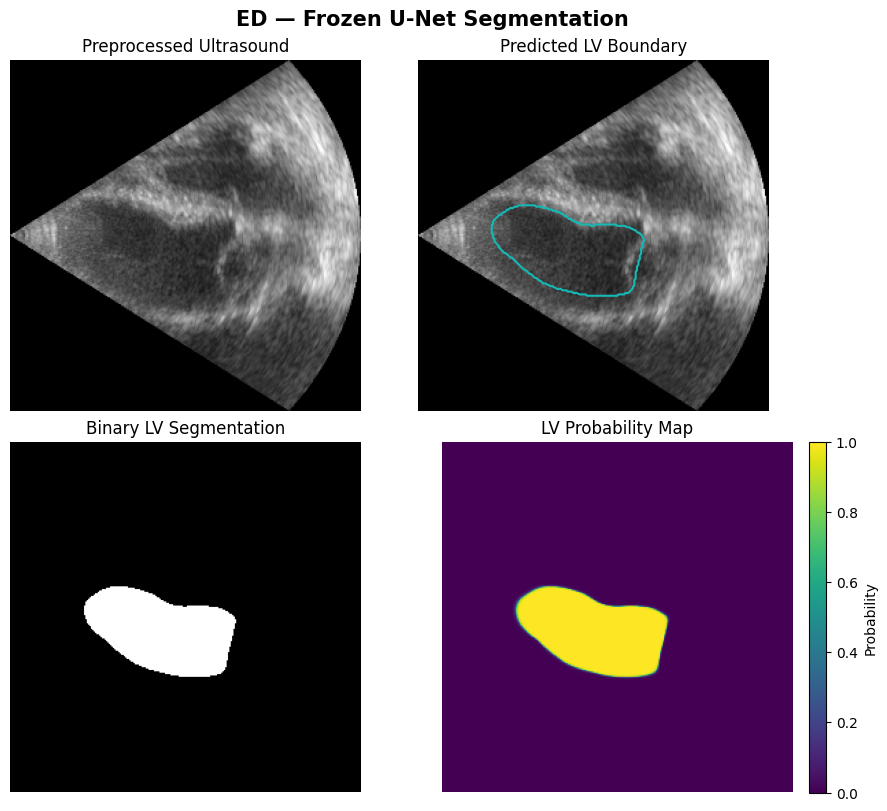

✓ Enlarged 2 × 2 segmentation figure ready.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 61
# ENLARGED ML SEGMENTATION FIGURES
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

def create_ml_segmentation_figure(frame_result, phase):

    image = np.asarray(
        frame_result["processed_image"]
    )

    probability = np.asarray(
        frame_result["probability_mask"]
    )

    mask = np.asarray(
        frame_result["predicted_mask"]
    ).astype(bool)

    fig, axes = plt.subplots(
        2, 2,
        figsize=(9, 8),
        constrained_layout=True
    )

    fig.patch.set_facecolor("white")

    # Original processed ultrasound
    axes[0, 0].imshow(image, cmap="gray")
    axes[0, 0].set_title(
        "Preprocessed Ultrasound",
        fontsize=12
    )

    # Predicted LV contour
    axes[0, 1].imshow(image, cmap="gray")

    if mask.any():
        axes[0, 1].contour(
            mask.astype(float),
            levels=[0.5],
            colors=["#16b8b4"],
            linewidths=1.5
        )

    axes[0, 1].set_title(
        "Predicted LV Boundary",
        fontsize=12
    )

    # Binary segmentation
    axes[1, 0].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, 0].set_title(
        "Binary LV Segmentation",
        fontsize=12
    )

    # Probability map
    probability_image = axes[1, 1].imshow(
        probability,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    axes[1, 1].set_title(
        "LV Probability Map",
        fontsize=12
    )

    fig.colorbar(
        probability_image,
        ax=axes[1, 1],
        fraction=0.046,
        pad=0.04,
        label="Probability"
    )

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(
        f"{phase} — Frozen U-Net Segmentation",
        fontsize=15,
        fontweight="bold"
    )

    return fig


# Preview using the existing frozen result
preview_ml = create_ml_segmentation_figure(
    enhanced_output["segmentation"]["ED"],
    "ED"
)

display(preview_ml)
plt.close(preview_ml)

print("✓ Enlarged 2 × 2 segmentation figure ready.")

In [ ]:
# ================================================================
# PHASE 5E-F — CELL 62
# FINAL PRESENTATION HANDLER
# ================================================================

# Preserve the previous handler
previous_dual_view_handler = run_dual_view_analysis_v2


def run_dual_view_analysis_v3(ed_file, es_file):

    # Reuse the existing frozen inference workflow
    outputs = list(
        previous_dual_view_handler(ed_file, es_file)
    )

    # Format only the displayed ML measurement table
    # Output index 13 is the quantitative measurements DataFrame
    outputs[13] = format_measurements_for_display(
        outputs[13]
    )

    return tuple(outputs)


print("✓ Updated presentation handler ready.")
print("✓ Improved EF panel included.")
print("✓ Compact technical review panel included.")
print("✓ Enlarged ML segmentation figures included.")
print("✓ Measurement table formatting included.")
print("✓ Frozen inference pipeline unchanged.")

✓ Updated presentation handler ready.
✓ Improved EF panel included.
✓ Compact technical review panel included.
✓ Enlarged ML segmentation figures included.
✓ Measurement table formatting included.
✓ Frozen inference pipeline unchanged.


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 63
# FINAL PRESENTATION VERIFICATION
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt

final_outputs = run_dual_view_analysis_v3(
    str(required_files["ED image"]),
    str(required_files["ES image"])
)

assert len(final_outputs) == 14

# Verify EF assessment
assert "EF Assessment" in final_outputs[6]
assert "Geometry-Derived Category" in final_outputs[6]
assert "ML Classifier Category" in final_outputs[6]

# Verify compact review notice
assert (
    "Technical Flags" in final_outputs[7]
    or "Technical Review Recommended" in final_outputs[7]
)

# Verify formatted measurements
table = final_outputs[13]

assert isinstance(table, pd.DataFrame)
assert len(table) == 8

assert "Ejection Fraction" in table["Measurement"].values

# Verify ML figures
assert isinstance(final_outputs[9], plt.Figure)
assert isinstance(final_outputs[10], plt.Figure)

for index in [0, 1, 9, 10, 11]:
    plt.close(final_outputs[index])

print("=" * 65)
print("PHASE 5E-F — FINAL PRESENTATION VERIFICATION")
print("=" * 65)

print("Dashboard outputs: 14/14")
print("Enhanced EF assessment: PASSED")
print("Compact review notices: PASSED")
print("Enlarged segmentation figures: PASSED")
print("Formatted measurements: PASSED")

print("\n✓ Presentation verification PASSED.")

PHASE 5E-F — FINAL PRESENTATION VERIFICATION
Dashboard outputs: 14/14
Enhanced EF assessment: PASSED
Compact review notices: PASSED
Enlarged segmentation figures: PASSED
Formatted measurements: PASSED

✓ Presentation verification PASSED.


In [ ]:
dual_view_demo_v2.launch(
    share=True,
    debug=False,
    show_error=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://42d6ebce1de02cbb7a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================================================
# PHASE 5E-F — CELL 65
# DOWNLOAD ANOTHER CAMUS PATIENT FOR APPLICATION TESTING
# ================================================================

from pathlib import Path
from google.colab import files
import zipfile

# Choose a different patient
PATIENT_ID = "patient0446"

# Existing CAMUS dataset directory
DATASET_ROOT = Path(
    "/content/camus_data_final/database_nifti/database_nifti"
)

# Locate ED and ES images
patient_dir = DATASET_ROOT / PATIENT_ID

ed_path = patient_dir / f"{PATIENT_ID}_4CH_ED.nii.gz"
es_path = patient_dir / f"{PATIENT_ID}_4CH_ES.nii.gz"

# Verify files exist
assert ed_path.exists(), f"ED image not found: {ed_path}"
assert es_path.exists(), f"ES image not found: {es_path}"

print("Selected patient:", PATIENT_ID)
print("ED image:", ed_path.name)
print("ES image:", es_path.name)

# Create ZIP containing both images
zip_path = Path(f"/content/{PATIENT_ID}_A4C_test.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    archive.write(ed_path, arcname=ed_path.name)
    archive.write(es_path, arcname=es_path.name)

print("\n✓ Patient images packaged successfully.")
print("✓ Downloading ZIP file...")

files.download(str(zip_path))

Selected patient: patient0446
ED image: patient0446_4CH_ED.nii.gz
ES image: patient0446_4CH_ES.nii.gz

✓ Patient images packaged successfully.
✓ Downloading ZIP file...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# PHASE 5F — CELL 66
# ASCEND EchoLV V3 — ED/ES INPUT VALIDATION
# ================================================================

from pathlib import Path
import re
import numpy as np
import gradio as gr

print("=" * 65)
print("ASCEND EchoLV V3 — INPUT VALIDATION")
print("=" * 65)


# ================================================================
# 1. EXTRACT FILE INFORMATION
# ================================================================

def extract_echo_file_info(file_path):
    """
    Extract patient ID and cardiac phase from a CAMUS filename.

    Expected example:
        patient0446_4CH_ED.nii.gz

    Filename metadata is not proof of actual cardiac phase.
    """

    name = Path(file_path).name

    pattern = (
        r"^(patient\d+)_4CH_(ED|ES)\.nii(?:\.gz)?$"
    )

    match = re.fullmatch(
        pattern,
        name,
        flags=re.IGNORECASE
    )

    if match:
        return {
            "filename": name,
            "patient_id": match.group(1).lower(),
            "phase": match.group(2).upper(),
            "recognized": True
        }

    return {
        "filename": name,
        "patient_id": None,
        "phase": None,
        "recognized": False
    }


# ================================================================
# 2. VALIDATE UPLOADED ED/ES PAIR
# ================================================================

def validate_echo_pair(ed_file, es_file):
    """
    Validate two uploaded A4C NIfTI images before inference.

    Returns:
        dict containing:
            valid
            messages
            warnings
            ed_info
            es_info

    This function does not execute model inference.
    """

    messages = []
    warnings = []

    # ------------------------------------------------------------
    # Check missing uploads
    # ------------------------------------------------------------

    if ed_file is None:
        messages.append(
            "End-Diastolic (ED) image is missing. "
            "Please upload the ED NIfTI image."
        )

    if es_file is None:
        messages.append(
            "End-Systolic (ES) image is missing. "
            "Please upload the ES NIfTI image."
        )

    if messages:
        return {
            "valid": False,
            "messages": messages,
            "warnings": warnings,
            "ed_info": None,
            "es_info": None
        }

    ed_path = Path(ed_file)
    es_path = Path(es_file)

    # ------------------------------------------------------------
    # Validate file extensions and existence
    # ------------------------------------------------------------

    for label, path in [
        ("ED", ed_path),
        ("ES", es_path)
    ]:

        if not path.is_file():
            messages.append(
                f"{label} file could not be found."
            )

        if not path.name.lower().endswith(
            (".nii", ".nii.gz")
        ):
            messages.append(
                f"{label} file must be a .nii or .nii.gz image."
            )

    if messages:
        return {
            "valid": False,
            "messages": messages,
            "warnings": warnings,
            "ed_info": None,
            "es_info": None
        }

    # ------------------------------------------------------------
    # Extract filename information
    # ------------------------------------------------------------

    ed_info = extract_echo_file_info(ed_path)
    es_info = extract_echo_file_info(es_path)

    # ------------------------------------------------------------
    # Check cardiac phase from filenames
    # ------------------------------------------------------------

    if ed_info["phase"] == "ES":
        messages.append(
            f"Incorrect ED upload: '{ed_path.name}' is "
            "labeled as an ES image. Please upload "
            "the corresponding ED image."
        )

    if es_info["phase"] == "ED":
        messages.append(
            f"Incorrect ES upload: '{es_path.name}' is "
            "labeled as an ED image. Please upload "
            "the corresponding ES image."
        )

    # ------------------------------------------------------------
    # Check patient matching
    # ------------------------------------------------------------

    if (
        ed_info["patient_id"] is not None
        and es_info["patient_id"] is not None
        and ed_info["patient_id"] != es_info["patient_id"]
    ):
        messages.append(
            "Patient mismatch: ED and ES images appear "
            "to belong to different patients."
        )

    # ------------------------------------------------------------
    # Check duplicate files
    # ------------------------------------------------------------

    if ed_path.resolve() == es_path.resolve():
        messages.append(
            "The same file was selected for ED and ES. "
            "Please upload two distinct cardiac-phase images."
        )

    # ------------------------------------------------------------
    # Warn about unrecognized filenames
    # ------------------------------------------------------------

    if not ed_info["recognized"]:
        warnings.append(
            "ED filename does not follow the CAMUS "
            "naming convention. Its cardiac phase "
            "cannot be verified from its name."
        )

    if not es_info["recognized"]:
        warnings.append(
            "ES filename does not follow the CAMUS "
            "naming convention. Its cardiac phase "
            "cannot be verified from its name."
        )

    # ------------------------------------------------------------
    # Validate NIfTI image contents
    # ------------------------------------------------------------

    try:
        import nibabel as nib

        ed_img = nib.load(str(ed_path))
        es_img = nib.load(str(es_path))

        ed_shape = ed_img.shape
        es_shape = es_img.shape

        if len(ed_shape) != 2:
            messages.append(
                f"ED image has shape {ed_shape}. "
                "This prototype expects a 2D ED frame."
            )

        if len(es_shape) != 2:
            messages.append(
                f"ES image has shape {es_shape}. "
                "This prototype expects a 2D ES frame."
            )

        if ed_shape != es_shape:
            messages.append(
                f"Image dimension mismatch: "
                f"ED {ed_shape}, ES {es_shape}."
            )

        if len(ed_shape) == 2 and len(es_shape) == 2:

            ed_data = np.asarray(
                ed_img.dataobj,
                dtype=np.float32
            )

            es_data = np.asarray(
                es_img.dataobj,
                dtype=np.float32
            )

            if not np.isfinite(ed_data).all():
                messages.append(
                    "ED image contains invalid numerical values."
                )

            if not np.isfinite(es_data).all():
                messages.append(
                    "ES image contains invalid numerical values."
                )

    except Exception as error:
        messages.append(
            "Unable to read one or both NIfTI images: "
            f"{type(error).__name__}: {error}"
        )

    # ------------------------------------------------------------
    # Final result
    # ------------------------------------------------------------

    return {
        "valid": len(messages) == 0,
        "messages": messages,
        "warnings": warnings,
        "ed_info": ed_info,
        "es_info": es_info
    }


# ================================================================
# 3. USER-FRIENDLY GRADIO VALIDATION WRAPPER
# ================================================================

def validate_before_analysis(ed_file, es_file):
    """
    Call this before the frozen inference pipeline.
    """

    result = validate_echo_pair(
        ed_file,
        es_file
    )

    if not result["valid"]:

        error_text = "\n".join(
            f"• {message}"
            for message in result["messages"]
        )

        raise gr.Error(
            "Input validation failed:\n" + error_text
        )

    return result


print("✓ Filename inspection function created.")
print("✓ ED/ES phase checks implemented.")
print("✓ Patient-pair matching implemented.")
print("✓ NIfTI readability checks implemented.")
print("✓ Image dimension checks implemented.")
print("✓ Gradio validation wrapper created.")
print("\nCell 66 completed successfully.")


ASCEND EchoLV V3 — INPUT VALIDATION
✓ Filename inspection function created.
✓ ED/ES phase checks implemented.
✓ Patient-pair matching implemented.
✓ NIfTI readability checks implemented.
✓ Image dimension checks implemented.
✓ Gradio validation wrapper created.

Cell 66 completed successfully.


In [ ]:

# ================================================================
# PHASE 5F — CELL 66A
# TEST ED/ES INPUT VALIDATION
# ================================================================

from pathlib import Path

test_patient = "patient0217"

patient_dir = DATASET_ROOT / test_patient

ed_test = patient_dir / f"{test_patient}_4CH_ED.nii.gz"
es_test = patient_dir / f"{test_patient}_4CH_ES.nii.gz"

assert ed_test.exists(), f"Missing: {ed_test}"
assert es_test.exists(), f"Missing: {es_test}"

# TEST 1: Correct ED/ES pair
correct_result = validate_echo_pair(
    str(ed_test),
    str(es_test)
)

print("\nTEST 1 — Correct ED/ES Pair")
print("Valid:", correct_result["valid"])
print("Errors:", correct_result["messages"])
print("Warnings:", correct_result["warnings"])

assert correct_result["valid"]


# TEST 2: Swapped ED/ES files
swapped_result = validate_echo_pair(
    str(es_test),
    str(ed_test)
)

print("\nTEST 2 — Swapped ED/ES Pair")
print("Valid:", swapped_result["valid"])

for message in swapped_result["messages"]:
    print("•", message)

assert not swapped_result["valid"]


# TEST 3: Missing ED image
missing_result = validate_echo_pair(
    None,
    str(es_test)
)

print("\nTEST 3 — Missing ED Image")
print("Valid:", missing_result["valid"])

for message in missing_result["messages"]:
    print("•", message)

assert not missing_result["valid"]


# TEST 4: Same file selected twice
duplicate_result = validate_echo_pair(
    str(ed_test),
    str(ed_test)
)

print("\nTEST 4 — Duplicate File")
print("Valid:", duplicate_result["valid"])

for message in duplicate_result["messages"]:
    print("•", message)

assert not duplicate_result["valid"]


print("\n" + "=" * 65)
print("✓ ALL FOUR INPUT VALIDATION TESTS PASSED")
print("=" * 65)



TEST 1 — Correct ED/ES Pair
Valid: True
Errors: []
Warnings: []

TEST 2 — Swapped ED/ES Pair
Valid: False
• Incorrect ED upload: 'patient0217_4CH_ES.nii.gz' is labeled as an ES image. Please upload the corresponding ED image.
• Incorrect ES upload: 'patient0217_4CH_ED.nii.gz' is labeled as an ED image. Please upload the corresponding ES image.

TEST 3 — Missing ED Image
Valid: False
• End-Diastolic (ED) image is missing. Please upload the ED NIfTI image.

TEST 4 — Duplicate File
Valid: False
• Incorrect ES upload: 'patient0217_4CH_ED.nii.gz' is labeled as an ED image. Please upload the corresponding ES image.
• The same file was selected for ED and ES. Please upload two distinct cardiac-phase images.

✓ ALL FOUR INPUT VALIDATION TESTS PASSED


In [ ]:

# ================================================================
# PHASE 5F — CELL 67
# ASCEND EchoLV V3 — PREMIUM VISUAL DESIGN SYSTEM
# ================================================================

import gradio as gr

# ================================================================
# 1. COLOR PALETTE
# ================================================================

V3_COLORS = {
    "navy": "#0B1726",
    "navy_soft": "#122438",
    "navy_card": "#192E43",
    "navy_border": "#294056",

    "teal": "#0D9488",
    "teal_bright": "#2DD4BF",
    "blue": "#2563EB",

    "clinical_bg": "#F5F8FC",
    "clinical_surface": "#FFFFFF",
    "clinical_border": "#E2E8F0",

    "text_dark": "#14263D",
    "text_muted": "#64748B",
    "text_light": "#EAF3FA",

    "warning": "#D97706",
    "warning_bg": "#FFF7ED",

    "success": "#0F766E",
    "success_bg": "#F0FDFA",
}


# ================================================================
# 2. GRADIO THEME
# ================================================================

V3_THEME = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="blue",
    neutral_hue="slate",
    radius_size=gr.themes.sizes.radius_lg,
    spacing_size=gr.themes.sizes.spacing_md,
    text_size=gr.themes.sizes.text_md,
).set(
    body_background_fill="#F5F8FC",
    body_text_color="#14263D",
    block_background_fill="#FFFFFF",
    block_border_color="#E2E8F0",
    block_label_text_color="#334155",
    button_primary_background_fill="#0D9488",
    button_primary_background_fill_hover="#0F766E",
    button_primary_text_color="#FFFFFF",
)


# ================================================================
# 3. CUSTOM APPLICATION CSS
# ================================================================

V3_CSS = """
/* ============================================================
   ASCEND EchoLV V3 — GLOBAL
   ============================================================ */

:root {
    --echo-navy: #0B1726;
    --echo-navy-soft: #122438;
    --echo-teal: #0D9488;
    --echo-blue: #2563EB;
    --echo-clinical-bg: #F5F8FC;
    --echo-border: #E2E8F0;
    --echo-text: #14263D;
    --echo-muted: #64748B;
}

.gradio-container {
    max-width: 100% !important;
    margin: 0 !important;
    padding: 0 !important;
    font-family: Inter, "Segoe UI", Arial, sans-serif !important;
    background: var(--echo-clinical-bg) !important;
}

.gradio-container h1,
.gradio-container h2,
.gradio-container h3 {
    letter-spacing: -0.025em;
}

/* ============================================================
   APPLICATION SHELL
   ============================================================ */

#v3-app-shell {
    gap: 0 !important;
    align-items: stretch !important;
}

#v3-sidebar {
    background: var(--echo-navy) !important;
    min-width: 235px !important;
    max-width: 235px !important;
    min-height: 100vh;
    padding: 24px 16px !important;
    border: none !important;
    border-radius: 0 !important;
}

#v3-sidebar,
#v3-sidebar * {
    color: #EAF3FA;
}

#v3-main {
    min-width: 0 !important;
    padding: 26px 30px !important;
    background: var(--echo-clinical-bg);
}

/* ============================================================
   SIDEBAR
   ============================================================ */

.v3-brand {
    display: flex;
    align-items: center;
    gap: 12px;
    margin-bottom: 34px;
}

.v3-brand-icon {
    width: 44px;
    height: 44px;
    display: flex;
    align-items: center;
    justify-content: center;
    background: #123F48;
    border-radius: 13px;
    color: #2DD4BF;
    font-size: 25px;
    font-weight: 800;
}

.v3-brand-title {
    font-size: 17px;
    font-weight: 800;
    letter-spacing: -0.03em;
}

.v3-brand-subtitle {
    font-size: 11px;
    color: #9FB3C8 !important;
    margin-top: 3px;
}

#v3-sidebar .v3-nav-btn {
    background: transparent !important;
    border: 1px solid transparent !important;
    color: #C8D7E5 !important;
    text-align: left !important;
    justify-content: flex-start !important;
    border-radius: 11px !important;
    min-height: 46px;
    margin-bottom: 7px;
    font-weight: 500;
}

#v3-sidebar .v3-nav-btn:hover {
    background: #193449 !important;
}

#v3-sidebar .v3-nav-active {
    background: #16445A !important;
    border-left: 3px solid #2DD4BF !important;
    color: #FFFFFF !important;
}

/* ============================================================
   CLINICAL WORKSPACE
   ============================================================ */

#v3-clinical {
    background: var(--echo-clinical-bg);
}

.v3-page-title {
    font-size: 27px;
    font-weight: 800;
    color: #14263D;
    margin-bottom: 4px;
}

.v3-page-subtitle {
    color: #64748B;
    font-size: 14px;
}

.v3-section-title {
    font-size: 17px;
    font-weight: 700;
    color: #14263D;
    margin-bottom: 12px;
}

.v3-metric-card {
    background: #FFFFFF;
    border: 1px solid #E2E8F0;
    border-radius: 14px;
    padding: 19px 20px;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.035);
    min-height: 118px;
}

.v3-metric-label {
    color: #64748B;
    font-size: 12px;
    font-weight: 600;
    margin-bottom: 9px;
}

.v3-metric-value {
    color: #14263D;
    font-size: 29px;
    font-weight: 800;
    letter-spacing: -0.04em;
}

.v3-metric-unit {
    font-size: 13px;
    color: #64748B;
    font-weight: 500;
    margin-left: 5px;
}

.v3-metric-description {
    color: #94A3B8;
    font-size: 11px;
    margin-top: 7px;
}

/* ============================================================
   ULTRASOUND VIEWERS
   ============================================================ */

.v3-image-viewer {
    background: #0B1726;
    border: 1px solid #294056;
    border-radius: 15px;
    padding: 12px;
    overflow: hidden;
}

.v3-viewer-title {
    color: #EAF3FA;
    font-size: 13px;
    font-weight: 700;
    margin-bottom: 10px;
}

.v3-image-viewer img {
    max-width: 100%;
    border-radius: 8px;
}

.v3-viewer-caption {
    color: #94AFC1;
    font-size: 11px;
    margin-top: 9px;
}

/* ============================================================
   PANELS
   ============================================================ */

.v3-panel {
    background: #FFFFFF;
    border: 1px solid #E2E8F0;
    border-radius: 14px;
    padding: 20px;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.03);
}

.v3-panel-title {
    font-size: 15px;
    font-weight: 700;
    color: #14263D;
    margin-bottom: 12px;
}

/* ============================================================
   ML RESEARCH WORKSPACE
   ============================================================ */

#v3-ml {
    background: #0F2032 !important;
    border-radius: 16px;
    padding: 22px !important;
}

#v3-ml .v3-ml-title {
    color: #67D7E7;
    font-size: 24px;
    font-weight: 800;
}

#v3-ml .v3-ml-subtitle {
    color: #A8BED0;
    font-size: 13px;
}

#v3-ml .v3-ml-card {
    background: #192E43;
    border: 1px solid #294056;
    border-radius: 13px;
    padding: 16px;
    color: #EAF3FA;
}

#v3-ml .v3-ml-card-title {
    color: #EAF3FA;
    font-size: 14px;
    font-weight: 700;
    margin-bottom: 12px;
}

/* ============================================================
   REVIEW NOTICES
   ============================================================ */

.v3-notice-neutral {
    background: #F1F5F9;
    border: 1px solid #CBD5E1;
    border-left: 4px solid #64748B;
    border-radius: 11px;
    padding: 15px 17px;
    color: #334155;
}

.v3-notice-warning {
    background: #FFF7ED;
    border: 1px solid #FED7AA;
    border-left: 4px solid #D97706;
    border-radius: 11px;
    padding: 15px 17px;
    color: #92400E;
}

/* ============================================================
   RESPONSIVE LAYOUT
   ============================================================ */

@media (max-width: 900px) {

    #v3-app-shell {
        flex-direction: column !important;
    }

    #v3-sidebar {
        min-width: 100% !important;
        max-width: 100% !important;
        min-height: auto !important;
        padding: 16px !important;
    }

    #v3-main {
        padding: 18px !important;
    }

    .v3-metric-value {
        font-size: 24px;
    }
}
"""

print("=" * 65)
print("ASCEND EchoLV V3 — VISUAL DESIGN SYSTEM")
print("=" * 65)

print("✓ Premium navy sidebar palette defined.")
print("✓ Clean clinical workspace palette defined.")
print("✓ Dark ML research workspace palette defined.")
print("✓ Measurement card styles defined.")
print("✓ Ultrasound viewer styles defined.")
print("✓ Review notice styles defined.")
print("✓ Responsive layout rules defined.")
print("✓ Gradio theme created.")
print("\nCell 67 completed successfully.")
```

## Cell 67A — Preview the new design

Before we build the full dashboard, let's verify that the theme looks right in Gradio.

<CodeBlock language="python" editable>
# ================================================================
# PHASE 5F — CELL 67A
# VISUAL DESIGN SYSTEM PREVIEW
# ================================================================

with gr.Blocks(
    theme=V3_THEME,
    css=V3_CSS,
    title="ASCEND EchoLV V3 — Design Preview"
) as v3_design_preview:

    with gr.Row(elem_id="v3-app-shell"):

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.Button(
                "Clinical View",
                elem_classes=["v3-nav-btn", "v3-nav-active"]
            )

            gr.Button(
                "ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            gr.Button(
                "Download Report",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:60px;
                font-size:12px;
                color:#9FB3C8;
                line-height:1.8;
            ">
                Research Prototype<br>
                Non-Diagnostic<br>
                A4C Echocardiography
            </div>
            """)

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            gr.HTML("""
            <div class="v3-page-title">
                Clinical View
            </div>

            <div class="v3-page-subtitle">
                Left Ventricular Functional Assessment
            </div>
            """)

            gr.HTML("<div style='height:18px'></div>")

            with gr.Row():

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        Ejection Fraction
                    </div>
                    <div class="v3-metric-value">
                        61.79<span class="v3-metric-unit">%</span>
                    </div>
                    <div class="v3-metric-description">
                        Single-plane geometric estimate
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        End-Diastolic Volume
                    </div>
                    <div class="v3-metric-value">
                        80.40<span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        Estimated LV volume at ED
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        End-Systolic Volume
                    </div>
                    <div class="v3-metric-value">
                        30.72<span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        Estimated LV volume at ES
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        Stroke Volume
                    </div>
                    <div class="v3-metric-value">
                        49.68<span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        EDV minus ESV
                    </div>
                </div>
                """)

            gr.HTML("""
            <div style="margin-top:20px"
                 class="v3-panel">

                <div class="v3-panel-title">
                    Analysis Review
                </div>

                <div class="v3-notice-neutral">
                    No predefined technical flags were
                    detected in this example.
                    Independent expert review is still
                    required.
                </div>

            </div>
            """)

            with gr.Column(elem_id="v3-ml"):

                gr.HTML("""
                <div class="v3-ml-title">
                    ML Research View
                </div>

                <div class="v3-ml-subtitle">
                    Segmentation, quantitative analysis
                    and model inspection.
                </div>
                """)

                gr.HTML("""
                <div class="v3-ml-card">
                    <div class="v3-ml-card-title">
                        Frozen U-Net Segmentation
                    </div>

                    Input resolution: 256 × 256<br>
                    Trainable parameters: 7,759,521<br>
                    Architecture: Large U-Net<br>
                    Output: LV cavity segmentation
                </div>
                """)

v3_design_preview.launch(
    share=True,
    debug=False,
    show_error=True
)


SyntaxError: unterminated string literal (detected at line 397) (3642294343.py, line 397)

In [ ]:

# ================================================================
# PHASE 5F — CELL 67
# ASCEND EchoLV V3 — PREMIUM VISUAL DESIGN SYSTEM
# ================================================================

import gradio as gr

# ================================================================
# 1. COLOR PALETTE
# ================================================================

V3_COLORS = {
    "navy": "#0B1726",
    "navy_soft": "#122438",
    "navy_card": "#192E43",
    "navy_border": "#294056",

    "teal": "#0D9488",
    "teal_bright": "#2DD4BF",
    "blue": "#2563EB",

    "clinical_bg": "#F5F8FC",
    "clinical_surface": "#FFFFFF",
    "clinical_border": "#E2E8F0",

    "text_dark": "#14263D",
    "text_muted": "#64748B",
    "text_light": "#EAF3FA",

    "warning": "#D97706",
    "warning_bg": "#FFF7ED",

    "success": "#0F766E",
    "success_bg": "#F0FDFA",
}

# ================================================================
# 2. GRADIO THEME
# ================================================================

V3_THEME = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="blue",
    neutral_hue="slate",
    radius_size=gr.themes.sizes.radius_lg,
    spacing_size=gr.themes.sizes.spacing_md,
    text_size=gr.themes.sizes.text_md,
).set(
    body_background_fill="#F5F8FC",
    body_text_color="#14263D",
    block_background_fill="#FFFFFF",
    block_border_color="#E2E8F0",
    block_label_text_color="#334155",
    button_primary_background_fill="#0D9488",
    button_primary_background_fill_hover="#0F766E",
    button_primary_text_color="#FFFFFF",
)

# ================================================================
# 3. CUSTOM APPLICATION CSS
# ================================================================

V3_CSS = """
/* ============================================================
   ASCEND EchoLV V3 — GLOBAL
   ============================================================ */

:root {
    --echo-navy: #0B1726;
    --echo-navy-soft: #122438;
    --echo-teal: #0D9488;
    --echo-blue: #2563EB;
    --echo-clinical-bg: #F5F8FC;
    --echo-border: #E2E8F0;
    --echo-text: #14263D;
    --echo-muted: #64748B;
}

.gradio-container {
    max-width: 100% !important;
    margin: 0 !important;
    padding: 0 !important;
    font-family: Inter, "Segoe UI", Arial, sans-serif !important;
    background: var(--echo-clinical-bg) !important;
}

.gradio-container h1,
.gradio-container h2,
.gradio-container h3 {
    letter-spacing: -0.025em;
}

/* ============================================================
   APPLICATION SHELL
   ============================================================ */

#v3-app-shell {
    gap: 0 !important;
    align-items: stretch !important;
}

#v3-sidebar {
    background: var(--echo-navy) !important;
    min-width: 235px !important;
    max-width: 235px !important;
    min-height: 100vh;
    padding: 24px 16px !important;
    border: none !important;
    border-radius: 0 !important;
}

#v3-sidebar,
#v3-sidebar * {
    color: #EAF3FA;
}

#v3-main {
    min-width: 0 !important;
    padding: 26px 30px !important;
    background: var(--echo-clinical-bg);
}

/* ============================================================
   SIDEBAR
   ============================================================ */

.v3-brand {
    display: flex;
    align-items: center;
    gap: 12px;
    margin-bottom: 34px;
}

.v3-brand-icon {
    width: 44px;
    height: 44px;
    display: flex;
    align-items: center;
    justify-content: center;
    background: #123F48;
    border-radius: 13px;
    color: #2DD4BF;
    font-size: 25px;
    font-weight: 800;
}

.v3-brand-title {
    font-size: 17px;
    font-weight: 800;
    letter-spacing: -0.03em;
}

.v3-brand-subtitle {
    font-size: 11px;
    color: #9FB3C8 !important;
    margin-top: 3px;
}

#v3-sidebar .v3-nav-btn {
    background: transparent !important;
    border: 1px solid transparent !important;
    color: #C8D7E5 !important;
    text-align: left !important;
    justify-content: flex-start !important;
    border-radius: 11px !important;
    min-height: 46px;
    margin-bottom: 7px;
    font-weight: 500;
}

#v3-sidebar .v3-nav-btn:hover {
    background: #193449 !important;
}

#v3-sidebar .v3-nav-active {
    background: #16445A !important;
    border-left: 3px solid #2DD4BF !important;
    color: #FFFFFF !important;
}

/* ============================================================
   CLINICAL WORKSPACE
   ============================================================ */

#v3-clinical {
    background: var(--echo-clinical-bg);
}

.v3-page-title {
    font-size: 27px;
    font-weight: 800;
    color: #14263D;
    margin-bottom: 4px;
}

.v3-page-subtitle {
    color: #64748B;
    font-size: 14px;
}

.v3-section-title {
    font-size: 17px;
    font-weight: 700;
    color: #14263D;
    margin-bottom: 12px;
}

/* ============================================================
   MEASUREMENT CARDS
   ============================================================ */

.v3-metric-card {
    background: #FFFFFF;
    border: 1px solid #E2E8F0;
    border-radius: 14px;
    padding: 19px 20px;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.035);
    min-height: 118px;
}

.v3-metric-label {
    color: #64748B;
    font-size: 12px;
    font-weight: 600;
    margin-bottom: 9px;
}

.v3-metric-value {
    color: #14263D;
    font-size: 29px;
    font-weight: 800;
    letter-spacing: -0.04em;
}

.v3-metric-unit {
    font-size: 13px;
    color: #64748B;
    font-weight: 500;
    margin-left: 5px;
}

.v3-metric-description {
    color: #94A3B8;
    font-size: 11px;
    margin-top: 7px;
}

/* ============================================================
   ULTRASOUND VIEWERS
   ============================================================ */

.v3-image-viewer {
    background: #0B1726;
    border: 1px solid #294056;
    border-radius: 15px;
    padding: 12px;
    overflow: hidden;
}

.v3-viewer-title {
    color: #EAF3FA;
    font-size: 13px;
    font-weight: 700;
    margin-bottom: 10px;
}

.v3-image-viewer img {
    max-width: 100%;
    border-radius: 8px;
}

.v3-viewer-caption {
    color: #94AFC1;
    font-size: 11px;
    margin-top: 9px;
}

/* ============================================================
   CLINICAL PANELS
   ============================================================ */

.v3-panel {
    background: #FFFFFF;
    border: 1px solid #E2E8F0;
    border-radius: 14px;
    padding: 20px;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.03);
}

.v3-panel-title {
    font-size: 15px;
    font-weight: 700;
    color: #14263D;
    margin-bottom: 12px;
}

/* ============================================================
   ML RESEARCH WORKSPACE
   ============================================================ */

#v3-ml {
    background: #0F2032 !important;
    border-radius: 16px;
    padding: 22px !important;
}

#v3-ml .v3-ml-title {
    color: #67D7E7;
    font-size: 24px;
    font-weight: 800;
}

#v3-ml .v3-ml-subtitle {
    color: #A8BED0;
    font-size: 13px;
}

#v3-ml .v3-ml-card {
    background: #192E43;
    border: 1px solid #294056;
    border-radius: 13px;
    padding: 16px;
    color: #EAF3FA;
}

#v3-ml .v3-ml-card-title {
    color: #EAF3FA;
    font-size: 14px;
    font-weight: 700;
    margin-bottom: 12px;
}

/* ============================================================
   REVIEW NOTICES
   ============================================================ */

.v3-notice-neutral {
    background: #F1F5F9;
    border: 1px solid #CBD5E1;
    border-left: 4px solid #64748B;
    border-radius: 11px;
    padding: 15px 17px;
    color: #334155;
}

.v3-notice-warning {
    background: #FFF7ED;
    border: 1px solid #FED7AA;
    border-left: 4px solid #D97706;
    border-radius: 11px;
    padding: 15px 17px;
    color: #92400E;
}

/* ============================================================
   RESPONSIVE LAYOUT
   ============================================================ */

@media (max-width: 900px) {

    #v3-app-shell {
        flex-direction: column !important;
    }

    #v3-sidebar {
        min-width: 100% !important;
        max-width: 100% !important;
        min-height: auto !important;
        padding: 16px !important;
    }

    #v3-main {
        padding: 18px !important;
    }

    .v3-metric-value {
        font-size: 24px;
    }
}
"""

# ================================================================
# 4. VALIDATION
# ================================================================

assert isinstance(V3_COLORS, dict)
assert len(V3_COLORS) > 0

assert isinstance(V3_CSS, str)
assert len(V3_CSS) > 1000

assert V3_THEME is not None

required_css_classes = [
    ".v3-brand",
    ".v3-metric-card",
    ".v3-image-viewer",
    ".v3-panel",
    ".v3-ml-card",
    ".v3-notice-neutral",
    ".v3-notice-warning",
]

for css_class in required_css_classes:
    assert css_class in V3_CSS, (
        f"Missing CSS class: {css_class}"
    )

# ================================================================
# 5. CONFIRMATION
# ================================================================

print("=" * 65)
print("ASCEND EchoLV V3 — VISUAL DESIGN SYSTEM")
print("=" * 65)

print("✓ Premium navy sidebar palette defined.")
print("✓ Clean clinical workspace palette defined.")
print("✓ Dark ML research workspace palette defined.")
print("✓ Measurement card styles defined.")
print("✓ Ultrasound viewer styles defined.")
print("✓ Review notice styles defined.")
print("✓ Responsive layout rules defined.")
print("✓ Gradio theme created.")
print("✓ Theme and CSS validation passed.")

print("\nCell 67 completed successfully.")


ASCEND EchoLV V3 — VISUAL DESIGN SYSTEM
✓ Premium navy sidebar palette defined.
✓ Clean clinical workspace palette defined.
✓ Dark ML research workspace palette defined.
✓ Measurement card styles defined.
✓ Ultrasound viewer styles defined.
✓ Review notice styles defined.
✓ Responsive layout rules defined.
✓ Gradio theme created.
✓ Theme and CSS validation passed.

Cell 67 completed successfully.


In [ ]:

# ================================================================
# PHASE 5F — CELL 67A
# ASCEND EchoLV V3 — VISUAL DESIGN PREVIEW
# ================================================================

import gradio as gr

# ------------------------------------------------
# 1. VERIFY CELL 67
# ------------------------------------------------

assert V3_THEME is not None, "Run Cell 67 first."
assert isinstance(V3_CSS, str), "Run Cell 67 first."

# ------------------------------------------------
# 2. CREATE DESIGN PREVIEW
# ------------------------------------------------

with gr.Blocks(
    title="ASCEND EchoLV V3 — Design Preview",
    theme=V3_THEME,
    css=V3_CSS
) as v3_design_preview:

    with gr.Row(elem_id="v3-app-shell"):

        # ========================================
        # SIDEBAR
        # ========================================

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.HTML("""
            <div style="
                color:#8197AA;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.5px;
                margin-bottom:12px;
            ">
                WORKSPACES
            </div>
            """)

            gr.Button(
                "▣  Clinical View",
                elem_classes=[
                    "v3-nav-btn",
                    "v3-nav-active"
                ]
            )

            gr.Button(
                "◈  ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                color:#8197AA;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.5px;
                margin-top:28px;
                margin-bottom:12px;
            ">
                TOOLS
            </div>
            """)

            gr.Button(
                "⇩  Download Report",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:65px;
                padding:14px;
                border:1px solid #294056;
                border-radius:12px;
                background:#122438;
                line-height:1.9;
                font-size:12px;
                color:#B7C9D8;
            ">
                <strong style="color:#EAF3FA;">
                    ASCEND Research Lab
                </strong>
                <div>Research Prototype</div>
                <div>Non-Diagnostic</div>
                <div>A4C Echocardiography</div>
            </div>
            """)

        # ========================================
        # MAIN CONTENT
        # ========================================

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            # ------------------------------------
            # CLINICAL HEADER
            # ------------------------------------

            gr.HTML("""
            <div style="
                display:flex;
                justify-content:space-between;
                align-items:center;
                margin-bottom:22px;
                gap:15px;
                flex-wrap:wrap;
            ">
                <div>
                    <div class="v3-page-title">
                        Clinical View
                    </div>
                    <div class="v3-page-subtitle">
                        Left Ventricular Functional Assessment
                    </div>
                </div>

                <div style="
                    padding:9px 15px;
                    background:#E6F5F3;
                    color:#0F766E;
                    border-radius:20px;
                    font-size:12px;
                    font-weight:700;
                ">
                    Research Prototype
                </div>
            </div>
            """)

            # ------------------------------------
            # CASE INFORMATION
            # ------------------------------------

            gr.HTML("""
            <div class="v3-panel"
                 style="margin-bottom:18px;">

                <div style="
                    display:flex;
                    justify-content:space-between;
                    align-items:center;
                    flex-wrap:wrap;
                    gap:12px;
                ">

                    <div>
                        <div style="
                            color:#64748B;
                            font-size:12px;
                        ">
                            Current Analysis
                        </div>

                        <div style="
                            font-size:17px;
                            font-weight:800;
                            color:#14263D;
                            margin-top:4px;
                        ">
                            patient0217
                        </div>
                    </div>

                    <div style="
                        color:#64748B;
                        font-size:12px;
                    ">
                        A4C | ED + ES | NIfTI
                    </div>

                </div>
            </div>
            """)

            # ------------------------------------
            # CLINICAL METRIC CARDS
            # ------------------------------------

            gr.HTML("""
            <div class="v3-section-title">
                LV Functional Measurements
            </div>
            """)

            with gr.Row(equal_height=True):

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        Ejection Fraction
                    </div>
                    <div class="v3-metric-value">
                        61.79
                        <span class="v3-metric-unit">%</span>
                    </div>
                    <div class="v3-metric-description">
                        Geometry-derived EF
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        End-Diastolic Volume
                    </div>
                    <div class="v3-metric-value">
                        80.40
                        <span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        Estimated ED volume
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        End-Systolic Volume
                    </div>
                    <div class="v3-metric-value">
                        30.72
                        <span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        Estimated ES volume
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-metric-card">
                    <div class="v3-metric-label">
                        Stroke Volume
                    </div>
                    <div class="v3-metric-value">
                        49.68
                        <span class="v3-metric-unit">mL</span>
                    </div>
                    <div class="v3-metric-description">
                        EDV minus ESV
                    </div>
                </div>
                """)

            # ------------------------------------
            # ULTRASOUND VIEWER PREVIEW
            # ------------------------------------

            gr.HTML("""
            <div class="v3-section-title"
                 style="margin-top:24px;">
                ED/ES Ultrasound Inspection
            </div>
            """)

            with gr.Row(equal_height=True):

                gr.HTML("""
                <div class="v3-image-viewer">

                    <div class="v3-viewer-title">
                        End-Diastole (ED)
                    </div>

                    <div style="
                        height:235px;
                        display:flex;
                        align-items:center;
                        justify-content:center;
                        flex-direction:column;
                        background:#060E17;
                        border-radius:10px;
                        border:1px dashed #355064;
                        color:#91AFC1;
                        gap:12px;
                    ">
                        <div style="font-size:35px;">
                            ◉
                        </div>

                        <div style="
                            font-size:13px;
                            text-align:center;
                        ">
                            ED Ultrasound Viewer
                        </div>

                        <div style="
                            font-size:11px;
                            color:#6F8A9D;
                        ">
                            Image will appear after analysis
                        </div>
                    </div>

                    <div class="v3-viewer-caption">
                        Original | Contour | Mask
                    </div>

                </div>
                """)

                gr.HTML("""
                <div class="v3-image-viewer">

                    <div class="v3-viewer-title">
                        End-Systole (ES)
                    </div>

                    <div style="
                        height:235px;
                        display:flex;
                        align-items:center;
                        justify-content:center;
                        flex-direction:column;
                        background:#060E17;
                        border-radius:10px;
                        border:1px dashed #355064;
                        color:#91AFC1;
                        gap:12px;
                    ">
                        <div style="font-size:35px;">
                            ◉
                        </div>

                        <div style="
                            font-size:13px;
                            text-align:center;
                        ">
                            ES Ultrasound Viewer
                        </div>

                        <div style="
                            font-size:11px;
                            color:#6F8A9D;
                        ">
                            Image will appear after analysis
                        </div>
                    </div>

                    <div class="v3-viewer-caption">
                        Original | Contour | Mask
                    </div>

                </div>
                """)

            # ------------------------------------
            # EF INTERPRETATION
            # ------------------------------------

            gr.HTML("""
            <div class="v3-panel"
                 style="margin-top:22px;">

                <div class="v3-panel-title">
                    EF Assessment & Classification
                </div>

                <div style="
                    display:grid;
                    grid-template-columns:repeat(
                        auto-fit,
                        minmax(200px,1fr)
                    );
                    gap:14px;
                ">

                    <div style="
                        background:#F5F8FC;
                        padding:15px;
                        border-radius:11px;
                    ">
                        <div style="
                            color:#64748B;
                            font-size:12px;
                        ">
                            Geometry-Derived Category
                        </div>

                        <div style="
                            font-size:17px;
                            font-weight:800;
                            color:#14263D;
                            margin-top:8px;
                        ">
                            Higher EF
                        </div>
                    </div>

                    <div style="
                        background:#F5F8FC;
                        padding:15px;
                        border-radius:11px;
                    ">
                        <div style="
                            color:#64748B;
                            font-size:12px;
                        ">
                            ML Classifier Category
                        </div>

                        <div style="
                            font-size:17px;
                            font-weight:800;
                            color:#14263D;
                            margin-top:8px;
                        ">
                            Higher EF
                        </div>
                    </div>

                </div>

                <div style="
                    margin-top:13px;
                    color:#64748B;
                    font-size:12px;
                ">
                    Research-defined EF bands.
                    Agreement does not establish
                    clinical accuracy.
                </div>

            </div>
            """)

            # ------------------------------------
            # ANALYSIS REVIEW
            # ------------------------------------

            gr.HTML("""
            <div class="v3-panel"
                 style="margin-top:18px;">

                <div class="v3-panel-title">
                    Analysis Review
                </div>

                <div class="v3-notice-neutral">
                    No predefined technical flags were
                    detected in this example.
                    Independent expert review is
                    still required.
                </div>

            </div>
            """)

            # ------------------------------------
            # ML RESEARCH PREVIEW
            # ------------------------------------

            with gr.Column(elem_id="v3-ml"):

                gr.HTML("""
                <div class="v3-ml-title">
                    ML Research Workspace
                </div>

                <div class="v3-ml-subtitle">
                    Segmentation inspection,
                    quantitative analysis and
                    model evaluation.
                </div>
                """)

                gr.HTML("""
                <div class="v3-ml-card"
                     style="margin-top:16px;">

                    <div class="v3-ml-card-title">
                        Frozen U-Net Segmentation
                    </div>

                    <div style="
                        line-height:2;
                        font-size:13px;
                        color:#C8D9E6;
                    ">
                        Architecture: Large U-Net<br>
                        Input resolution: 256 × 256<br>
                        Trainable parameters: 7,759,521<br>
                        Target: LV cavity segmentation<br>
                        Cardiac phases: ED and ES
                    </div>

                </div>
                """)

                gr.HTML("""
                <div class="v3-ml-card"
                     style="margin-top:14px;">

                    <div class="v3-ml-card-title">
                        Research Analysis Modules
                    </div>

                    <div style="
                        display:grid;
                        grid-template-columns:repeat(
                            auto-fit,
                            minmax(170px,1fr)
                        );
                        gap:10px;
                    ">

                        <div style="
                            background:#102237;
                            border-radius:9px;
                            padding:13px;
                        ">
                            Segmentation Explorer
                        </div>

                        <div style="
                            background:#102237;
                            border-radius:9px;
                            padding:13px;
                        ">
                            Quantitative Analysis
                        </div>

                        <div style="
                            background:#102237;
                            border-radius:9px;
                            padding:13px;
                        ">
                            Ground Truth Comparison
                        </div>

                        <div style="
                            background:#102237;
                            border-radius:9px;
                            padding:13px;
                        ">
                            Model Information
                        </div>

                    </div>

                </div>
                """)

            # ------------------------------------
            # FOOTER
            # ------------------------------------

            gr.HTML("""
            <div style="
                margin-top:20px;
                padding:14px;
                text-align:center;
                color:#64748B;
                font-size:12px;
            ">
                ASCEND EchoLV |
                AI-Assisted LV Analysis |
                Research Use Only |
                Non-Diagnostic
            </div>
            """)

# ------------------------------------------------
# 3. CONFIRM BUILD
# ------------------------------------------------

print("=" * 65)
print("ASCEND EchoLV V3 — DESIGN PREVIEW")
print("=" * 65)

print("✓ Navy sidebar created.")
print("✓ Clinical workspace created.")
print("✓ Four metric cards created.")
print("✓ ED/ES viewer placeholders created.")
print("✓ EF interpretation panel created.")
print("✓ Review notice panel created.")
print("✓ ML Research preview created.")
print("✓ No frozen model modifications.")

# ------------------------------------------------
# 4. LAUNCH PREVIEW
# ------------------------------------------------

v3_design_preview.launch(
    share=True,
    debug=False,
    show_error=True
)


/tmp/ipykernel_522/2054490423.py:19: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


ASCEND EchoLV V3 — DESIGN PREVIEW
✓ Navy sidebar created.
✓ Clinical workspace created.
✓ Four metric cards created.
✓ ED/ES viewer placeholders created.
✓ EF interpretation panel created.
✓ Review notice panel created.
✓ ML Research preview created.
✓ No frozen model modifications.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://634d57edb9f92cdaef.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ================================================================
# PHASE 5F — CELL 68
# ASCEND EchoLV V3 — FUNCTIONAL WORKSPACE NAVIGATION
# ================================================================

import gradio as gr

# Keep the existing Cell 67 theme and CSS.
assert V3_THEME is not None
assert isinstance(V3_CSS, str)

# Additional CSS for the improved navigation and layout.
V3_NAV_CSS = V3_CSS + """
/* Application layout refinements */

#v3-app-shell {
    gap: 0 !important;
}

#v3-main {
    padding: 24px 30px !important;
}

#v3-sidebar .v3-nav-btn {
    margin-bottom: 4px !important;
    font-size: 14px !important;
}

.v3-compact-header {
    margin-bottom: 16px;
}

.v3-mini-label {
    font-size: 11px;
    font-weight: 700;
    letter-spacing: 1.2px;
    color: #7C91A5;
    text-transform: uppercase;
}

.v3-info-strip {
    background: #FFFFFF;
    border: 1px solid #E2E8F0;
    border-radius: 12px;
    padding: 14px 18px;
    margin-bottom: 16px;
}

.v3-empty-state {
    padding: 32px 18px;
    text-align: center;
    border: 1px dashed #CBD5E1;
    border-radius: 12px;
    background: #F8FAFC;
    color: #64748B;
}

.v3-ml-section {
    background: #192E43;
    border: 1px solid #294056;
    border-radius: 12px;
    padding: 18px;
    color: #EAF3FA;
}

.v3-ml-section h3 {
    color: #EAF3FA;
    margin: 0 0 8px 0;
}

.v3-ml-section p {
    color: #B8CBDC;
    font-size: 13px;
    margin: 0;
}

#v3-ml-page {
    background: #0F2032 !important;
    border-radius: 16px;
    padding: 24px !important;
}

#v3-ml-page .v3-page-title {
    color: #EAF3FA;
}

#v3-ml-page .v3-page-subtitle {
    color: #A8BED0;
}
"""

# ------------------------------------------------
# NAVIGATION HELPERS
# ------------------------------------------------

V3_PAGES = ("clinical", "ml", "about")

def v3_navigate(page):
    if page not in V3_PAGES:
        raise gr.Error("Unknown workspace.")

    return (
        gr.update(visible=(page == "clinical")),
        gr.update(visible=(page == "ml")),
        gr.update(visible=(page == "about")),
        gr.update(
            elem_classes=[
                "v3-nav-btn",
                "v3-nav-active"
            ] if page == "clinical" else ["v3-nav-btn"]
        ),
        gr.update(
            elem_classes=[
                "v3-nav-btn",
                "v3-nav-active"
            ] if page == "ml" else ["v3-nav-btn"]
        ),
        gr.update(
            elem_classes=[
                "v3-nav-btn",
                "v3-nav-active"
            ] if page == "about" else ["v3-nav-btn"]
        )
    )


# ------------------------------------------------
# CREATE APPLICATION
# ------------------------------------------------

with gr.Blocks(
    title="ASCEND EchoLV V3 — Workstation",
    theme=V3_THEME,
    css=V3_NAV_CSS
) as v3_navigation_demo:

    with gr.Row(elem_id="v3-app-shell"):

        # ========================================
        # SIDEBAR
        # ========================================

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.HTML("""
            <div class="v3-mini-label"
                 style="margin-bottom:12px;">
                WORKSPACES
            </div>
            """)

            clinical_btn = gr.Button(
                "▣  Clinical View",
                elem_classes=[
                    "v3-nav-btn",
                    "v3-nav-active"
                ]
            )

            ml_btn = gr.Button(
                "◈  ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div class="v3-mini-label"
                 style="margin:24px 0 12px;">
                INFORMATION
            </div>
            """)

            about_btn = gr.Button(
                "ⓘ  About",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:45px;
                padding:14px;
                border:1px solid #294056;
                border-radius:12px;
                background:#122438;
                font-size:12px;
                line-height:1.9;
                color:#B7C9D8;
            ">
                <strong style="color:#EAF3FA;">
                    ASCEND Research Lab
                </strong>
                <div>Research Prototype</div>
                <div>Non-Diagnostic</div>
                <div>A4C Echocardiography</div>
            </div>
            """)

        # ========================================
        # MAIN WORKSPACE
        # ========================================

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            # ====================================
            # PAGE 1 — CLINICAL VIEW
            # ====================================

            with gr.Column(
                visible=True,
                elem_id="v3-clinical-page"
            ) as clinical_page:

                gr.HTML("""
                <div class="v3-compact-header">
                    <div class="v3-page-title">
                        Clinical View
                    </div>
                    <div class="v3-page-subtitle">
                        AI-Assisted Left Ventricular
                        Functional Assessment
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-info-strip">
                    <div style="
                        display:flex;
                        justify-content:space-between;
                        gap:12px;
                        flex-wrap:wrap;
                    ">
                        <div>
                            <div style="
                                font-size:12px;
                                color:#64748B;
                            ">
                                Current Case
                            </div>
                            <strong style="
                                color:#14263D;
                                font-size:16px;
                            ">
                                No case loaded
                            </strong>
                        </div>
                        <div style="
                            color:#64748B;
                            font-size:12px;
                        ">
                            A4C | ED + ES | NIfTI
                        </div>
                    </div>
                </div>
                """)

                gr.HTML("""
                <div class="v3-section-title">
                    Case Input
                </div>
                """)

                with gr.Row():
                    v3_ed_file = gr.File(
                        label="End-Diastole (ED)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                    v3_es_file = gr.File(
                        label="End-Systole (ES)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                gr.HTML("""
                <div style="
                    font-size:12px;
                    color:#64748B;
                    margin-bottom:12px;
                ">
                    Upload paired CAMUS A4C ED and ES
                    NIfTI images.
                </div>
                """)

                # Input controls only at this stage.
                # Inference is connected in the next cell.

                gr.HTML("""
                <div class="v3-section-title"
                     style="margin-top:10px;">
                    LV Functional Measurements
                </div>
                """)

                with gr.Row(equal_height=True):

                    for title, unit in [
                        ("Ejection Fraction", "%"),
                        ("End-Diastolic Volume", "mL"),
                        ("End-Systolic Volume", "mL"),
                        ("Stroke Volume", "mL"),
                    ]:
                        gr.HTML(f"""
                        <div class="v3-metric-card">
                            <div class="v3-metric-label">
                                {title}
                            </div>
                            <div class="v3-metric-value">
                                --
                                <span class="v3-metric-unit">
                                    {unit}
                                </span>
                            </div>
                            <div class="v3-metric-description">
                                Awaiting analysis
                            </div>
                        </div>
                        """)

                gr.HTML("""
                <div class="v3-section-title"
                     style="margin-top:18px;">
                    ED/ES Ultrasound Inspection
                </div>
                """)

                with gr.Row(equal_height=True):

                    with gr.Column():
                        gr.Image(
                            label="End-Diastole (ED)",
                            type="numpy",
                            interactive=False,
                            height=310
                        )

                    with gr.Column():
                        gr.Image(
                            label="End-Systole (ES)",
                            type="numpy",
                            interactive=False,
                            height=310
                        )

                gr.HTML("""
                <div class="v3-notice-neutral"
                     style="margin-top:14px;">
                    No analysis has been performed.
                    Quantitative results require
                    independent expert review.
                </div>
                """)

            # ====================================
            # PAGE 2 — ML RESEARCH VIEW
            # ====================================

            with gr.Column(
                visible=False,
                elem_id="v3-ml-page"
            ) as ml_page:

                gr.HTML("""
                <div class="v3-page-title">
                    ML Research View
                </div>
                <div class="v3-page-subtitle">
                    Model inspection, segmentation
                    analysis and quantitative evaluation
                </div>
                """)

                gr.HTML("""
                <div style="height:12px;"></div>
                """)

                with gr.Row():
                    gr.HTML("""
                    <div class="v3-ml-section">
                        <h3>Segmentation Explorer</h3>
                        <p>
                            Inspect original ultrasound,
                            predicted LV contours,
                            binary masks and probability
                            maps for ED and ES.
                        </p>
                    </div>
                    """)

                    gr.HTML("""
                    <div class="v3-ml-section">
                        <h3>Quantitative Analysis</h3>
                        <p>
                            Explore LV areas, long-axis
                            lengths, EDV, ESV, SV
                            and geometric EF.
                        </p>
                    </div>
                    """)

                with gr.Row():
                    gr.HTML("""
                    <div class="v3-ml-section">
                        <h3>Ground Truth Comparison</h3>
                        <p>
                            Compare predicted segmentation
                            with reference masks when
                            available.
                        </p>
                    </div>
                    """)

                    gr.HTML("""
                    <div class="v3-ml-section">
                        <h3>Classifier Inspection</h3>
                        <p>
                            Inspect EF-band predictions
                            and uncalibrated classifier
                            scores.
                        </p>
                    </div>
                    """)

                gr.HTML("""
                <div class="v3-ml-section"
                     style="margin-top:16px;">
                    <h3>Frozen Model Information</h3>
                    <p>
                        Architecture: Large U-Net<br>
                        Input resolution: 256 × 256<br>
                        Trainable parameters: 7,759,521<br>
                        Target: LV cavity<br>
                        Cardiac phases: ED and ES
                    </p>
                </div>
                """)

                gr.HTML("""
                <div style="
                    margin-top:18px;
                    color:#A8BED0;
                    font-size:12px;
                ">
                    Research-only outputs.
                    Segmentation agreement does not
                    establish EF estimation accuracy.
                </div>
                """)

            # ====================================
            # PAGE 3 — ABOUT
            # ====================================

            with gr.Column(
                visible=False
            ) as about_page:

                gr.HTML("""
                <div class="v3-page-title">
                    About ASCEND EchoLV
                </div>

                <div class="v3-page-subtitle">
                    Computer Vision-Based Assistive
                    Application for A4C Echocardiography
                </div>

                <div class="v3-panel"
                     style="margin-top:24px;">

                    <div class="v3-panel-title">
                        Research Prototype
                    </div>

                    <p>
                        ASCEND EchoLV is a research
                        application for left ventricular
                        cavity segmentation and
                        quantitative analysis of
                        apical four-chamber
                        echocardiographic images.
                    </p>

                    <p>
                        It uses frozen segmentation
                        and classification models.
                        Results are intended for
                        research inspection and
                        require independent
                        expert review.
                    </p>

                    <p>
                        The system is not validated
                        for clinical diagnosis
                        or treatment decisions.
                    </p>

                </div>
                """)

    # ============================================
    # CONNECT SIDEBAR NAVIGATION
    # ============================================

    nav_outputs = [
        clinical_page,
        ml_page,
        about_page,
        clinical_btn,
        ml_btn,
        about_btn
    ]

    clinical_btn.click(
        fn=lambda: v3_navigate("clinical"),
        inputs=[],
        outputs=nav_outputs,
        queue=False
    )

    ml_btn.click(
        fn=lambda: v3_navigate("ml"),
        inputs=[],
        outputs=nav_outputs,
        queue=False
    )

    about_btn.click(
        fn=lambda: v3_navigate("about"),
        inputs=[],
        outputs=nav_outputs,
        queue=False
    )

# ------------------------------------------------
# LAUNCH
# ------------------------------------------------

print("ASCEND EchoLV V3 — Navigation Preview")
print("✓ Clinical View is a separate page.")
print("✓ ML Research View is a separate page.")
print("✓ About is a separate page.")
print("✓ Sidebar buttons connected.")
print("✓ Active navigation highlighting enabled.")
print("✓ Existing frozen models unchanged.")

v3_navigation_demo.launch(
    share=True,
    debug=False,
    show_error=True
)


/tmp/ipykernel_522/3800397195.py:131: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


ASCEND EchoLV V3 — Navigation Preview
✓ Clinical View is a separate page.
✓ ML Research View is a separate page.
✓ About is a separate page.
✓ Sidebar buttons connected.
✓ Active navigation highlighting enabled.
✓ Existing frozen models unchanged.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c13d7743c05aaec923.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ================================================================
# CELL 69 — ASCEND EchoLV V3 COMPLETE WORKSTATION
# CLINICAL + ML RESEARCH + CASE MANAGEMENT + PDF REPORT
# ================================================================

import gradio as gr
from html import escape

# ================================================================
# 1. VERIFY DEPENDENCIES
# ================================================================

required_functions = [
    "run_dual_view_analysis_v3",
    "create_model_information_panel",
    "validate_before_analysis",
    "extract_echo_file_info",
    "v3_empty_case",
    "v3_make_case_record",
    "v3_case_management_html",
    "v3_reset_case",
    "v3_reset_case_with_report",
    "v3_build_report_state",
    "v3_generate_pdf_from_state",
    "v3_prepare_report_data",
    "v3_create_research_pdf"
]

for name in required_functions:
    assert callable(globals().get(name)), (
        f"Missing function: {name}. "
        "Run Cells 70A, 71A and 71B first."
    )

assert "V3_THEME" in globals(), "Run Cell 67 first."
assert "V3_CSS" in globals(), "Run Cell 67 first."

# ================================================================
# 2. FINAL CSS
# ================================================================

V3_FINAL_CSS = V3_CSS + """

/* WORKSTATION LAYOUT */

#v3-app-shell {
    gap: 0 !important;
    align-items: stretch !important;
}

#v3-sidebar {
    position: sticky;
    top: 0;
    height: 100vh;
    overflow-y: auto;
    min-width: 235px !important;
    max-width: 235px !important;
}

#v3-main {
    padding: 22px 26px !important;
    min-width: 0 !important;
}

#v3-sidebar .v3-nav-btn {
    min-height: 44px !important;
    margin-bottom: 5px !important;
    font-size: 13px !important;
    justify-content: flex-start !important;
}

/* TYPOGRAPHY */

.v3-header-title {
    font-size: 25px;
    font-weight: 800;
    color: #14263D !important;
}

.v3-header-subtitle {
    font-size: 13px;
    color: #64748B !important;
    margin-top: 4px;
}

.v3-section-heading {
    font-size: 16px;
    font-weight: 750;
    color: #14263D !important;
    margin: 14px 0 8px;
}

.v3-helper-text {
    font-size: 12px;
    color: #64748B !important;
    margin-bottom: 8px;
}

/* METRIC CARDS */

#v3-clinical-page .metric-card {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 13px !important;
    padding: 16px !important;
    min-height: 116px !important;
    color: #14263D !important;
}

#v3-clinical-page .metric-label {
    color: #52677A !important;
    font-size: 12px !important;
    font-weight: 600 !important;
}

#v3-clinical-page .metric-value {
    color: #14263D !important;
    font-size: 28px !important;
    font-weight: 800 !important;
    margin: 9px 0 5px !important;
}

#v3-clinical-page .metric-value span {
    color: #52677A !important;
}

#v3-clinical-page .metric-subtitle {
    color: #64748B !important;
    font-size: 11px !important;
    line-height: 1.5 !important;
}

/* CURRENT CASE */

#v3-current-case .v3-case-banner {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 12px !important;
    padding: 15px 18px !important;
    margin-bottom: 10px !important;
    color: #14263D !important;
}

#v3-current-case .v3-case-banner strong {
    color: #334155 !important;
}

#v3-current-case .v3-case-id {
    color: #102A43 !important;
}

#v3-current-case .v3-case-meta {
    color: #64748B !important;
}

/* EF AGREEMENT NOTICES */

#v3-ef-assessment .v3-ef-agreement,
#v3-ef-assessment .v3-ef-agreement * {
    color: #115E59 !important;
}

#v3-ef-assessment .v3-ef-disagreement,
#v3-ef-assessment .v3-ef-disagreement * {
    color: #92400E !important;
}

#v3-ef-assessment .v3-ef-agreement {
    background: #DDF3ED !important;
    border-radius: 11px;
    padding: 13px 16px;
}

#v3-ef-assessment .v3-ef-disagreement {
    background: #FFF0D9 !important;
    border-radius: 11px;
    padding: 13px 16px;
}

/* INFORMATION PANELS */

.v3-info-panel {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 14px !important;
    padding: 22px !important;
    margin-top: 18px !important;
    color: #14263D !important;
}

.v3-info-panel h3,
.v3-info-panel strong {
    color: #14263D !important;
}

.v3-info-panel p,
.v3-info-panel li {
    color: #475569 !important;
    font-size: 14px;
    line-height: 1.75;
}

/* WORKSPACE HEADER */

.v3-page-header {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
    flex-wrap: wrap;
    margin-bottom: 15px;
}

.v3-status-chip {
    padding: 8px 12px;
    background: #E6F5F3;
    color: #0F766E !important;
    font-size: 11px;
    font-weight: 700;
    border-radius: 10px;
}

/* ML RESEARCH WORKSPACE */

#v3-ml-page {
    background: #0F2032 !important;
    border-radius: 15px;
    padding: 22px !important;
}

#v3-ml-page .v3-header-title,
#v3-ml-page .v3-section-heading {
    color: #EAF3FA !important;
}

#v3-ml-page .v3-header-subtitle,
#v3-ml-page .v3-helper-text {
    color: #B4C7D7 !important;
}

#v3-ml-page .v3-ml-note {
    color: #B4C7D7 !important;
    font-size: 12px;
    line-height: 1.7;
    margin-top: 12px;
}

/* RESPONSIVE */

@media (max-width: 900px) {
    #v3-sidebar {
        position: relative;
        height: auto;
        min-width: 100% !important;
        max-width: 100% !important;
    }

    #v3-main {
        padding: 15px !important;
    }
}
"""

# ================================================================
# 3. HTML HELPERS
# ================================================================

def v3_metric_placeholder(label, unit):
    return f"""
    <div class="metric-card">
        <div class="metric-label">{escape(label)}</div>
        <div class="metric-value">
            -- <span>{escape(unit)}</span>
        </div>
        <div class="metric-subtitle">
            Awaiting analysis
        </div>
    </div>
    """


def v3_case_html(patient_id):
    return f"""
    <div class="v3-case-banner" style="
        background:#FFFFFF;
        border:1px solid #DCE5EF;
        border-radius:12px;
        padding:15px 18px;
        display:flex;
        align-items:center;
        flex-wrap:wrap;
        gap:12px;
    ">
        <strong style="
            color:#334155 !important;
            font-size:13px;
        ">Current Case:</strong>

        <span class="v3-case-id" style="
            color:#102A43 !important;
            font-size:17px;
            font-weight:800;
        ">{escape(str(patient_id))}</span>

        <span class="v3-case-meta" style="
            color:#64748B !important;
            font-size:12px;
        ">A4C | ED + ES | Research Analysis</span>
    </div>
    """


def v3_fix_ef_notice(html):
    """
    Improve EF notice contrast without changing
    geometry, classifier or interpretation.
    """

    if not isinstance(html, str):
        return html

    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")

    for text_node in soup.find_all(string=True):

        text = str(text_node).strip().lower()

        if text not in (
            "categories agree",
            "categories differ"
        ):
            continue

        notice = text_node.parent

        while notice is not None and notice.name != "div":
            notice = notice.parent

        if notice is None:
            continue

        for parent in [notice] + list(notice.parents):

            if getattr(parent, "name", None) != "div":
                continue

            if "background" in parent.get(
                "style", ""
            ).lower():
                notice = parent
                break

        different = text == "categories differ"

        foreground = (
            "#92400E" if different else "#115E59"
        )

        background = (
            "#FFF0D9" if different else "#DDF3ED"
        )

        class_name = (
            "v3-ef-disagreement"
            if different
            else "v3-ef-agreement"
        )

        notice["class"] = (
            notice.get("class", []) + [class_name]
        )

        notice["style"] = (
            notice.get("style", "")
            + f";background:{background} !important;"
            + f"color:{foreground} !important;"
        )

        for child in notice.find_all(True):
            child["style"] = (
                child.get("style", "")
                + f";color:{foreground} !important;"
            )

        break

    return str(soup)


# ================================================================
# 4. NAVIGATION
# ================================================================

V3_PAGE_NAMES = [
    "clinical",
    "ml",
    "cases",
    "reports",
    "about"
]


def v3_switch_workspace(page):

    if page not in V3_PAGE_NAMES:
        raise gr.Error("Invalid workspace.")

    page_updates = [
        gr.update(visible=(name == page))
        for name in V3_PAGE_NAMES
    ]

    button_updates = [
        gr.update(
            elem_classes=(
                ["v3-nav-btn", "v3-nav-active"]
                if name == page
                else ["v3-nav-btn"]
            )
        )
        for name in V3_PAGE_NAMES
    ]

    return tuple(page_updates + button_updates)


# ================================================================
# 5. ANALYSIS HANDLER + CASE + REPORT STATE
# ================================================================

def v3_analyze_case(ed_file, es_file):

    # Validate ED and ES inputs.
    validate_before_analysis(ed_file, es_file)

    # Run the existing frozen analysis once.
    results = list(
        run_dual_view_analysis_v3(ed_file, es_file)
    )

    if len(results) != 14:
        raise gr.Error(
            "Unexpected analysis output count."
        )

    # Improve notice visibility.
    results[6] = v3_fix_ef_notice(results[6])

    # Build case information.
    case = v3_make_case_record(
        ed_file,
        es_file
    )

    # Prepare report data from the same analysis.
    try:

        report_state = v3_build_report_state(
            case,
            results[13],
            results[6],
            results[7]
        )

        report_status = (
            "Analysis completed. "
            "PDF report is ready to generate."
        )

    except Exception as exc:

        # Keep the main analysis functional even if
        # report data cannot be extracted.
        report_state = None

        report_status = (
            "Analysis completed, but report preparation "
            f"needs attention: {exc}"
        )

    return (
        v3_case_html(case["patient_id"]),
        *results,
        case,
        v3_case_management_html(case),
        report_state,
        report_status,
        None
    )


# ================================================================
# 6. BUILD DASHBOARD
# ================================================================

with gr.Blocks(
    title="ASCEND EchoLV V3 — Research Workstation",
    theme=V3_THEME,
    css=V3_FINAL_CSS
) as ascend_echolv_v3:

    # Session-specific case and report state.
    v3_case_state = gr.State(
        value=v3_empty_case()
    )

    v3_report_state = gr.State(
        value=None
    )

    with gr.Row(elem_id="v3-app-shell"):

        # ========================================
        # SIDEBAR
        # ========================================

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin-bottom:12px;
            ">WORKSPACES</div>
            """)

            v3_clinical_btn = gr.Button(
                "▣  Clinical View",
                elem_classes=[
                    "v3-nav-btn",
                    "v3-nav-active"
                ]
            )

            v3_ml_btn = gr.Button(
                "◈  ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            v3_cases_btn = gr.Button(
                "▤  Case Management",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin:23px 0 12px;
            ">TOOLS & INFORMATION</div>
            """)

            v3_reports_btn = gr.Button(
                "⇩  Download Report",
                elem_classes=["v3-nav-btn"]
            )

            v3_about_btn = gr.Button(
                "ⓘ  About",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:40px;
                padding:14px;
                border:1px solid #294056;
                border-radius:12px;
                background:#122438;
                color:#B7C9D8;
                font-size:11px;
                line-height:1.9;
            ">
                <strong style="color:#FFFFFF;">
                    ASCEND Research Lab
                </strong>
                <div>Research Prototype</div>
                <div>Non-Diagnostic</div>
                <div>A4C Echocardiography</div>
            </div>
            """)

        # ========================================
        # MAIN WORKSPACE
        # ========================================

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            # ====================================
            # CLINICAL VIEW
            # ====================================

            with gr.Column(
                visible=True,
                elem_id="v3-clinical-page"
            ) as v3_clinical_page:

                gr.HTML("""
                <div class="v3-page-header">
                    <div>
                        <div class="v3-header-title">
                            Clinical View
                        </div>
                        <div class="v3-header-subtitle">
                            Left Ventricular Functional Assessment
                        </div>
                    </div>
                    <div class="v3-status-chip">
                        Research Only · Non-Diagnostic
                    </div>
                </div>
                """)

                v3_case_banner = gr.HTML(
                    value=v3_case_html(
                        "No case analyzed yet"
                    ),
                    elem_id="v3-current-case"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Load Echocardiography Images
                </div>
                <div class="v3-helper-text">
                    Upload paired A4C ED and ES NIfTI files.
                </div>
                """)

                with gr.Row():

                    v3_ed_input = gr.File(
                        label="End-Diastole (ED)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                    v3_es_input = gr.File(
                        label="End-Systole (ES)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                v3_analyze_btn = gr.Button(
                    "Analyze LV Function",
                    variant="primary",
                    size="lg"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Key LV Functional Measurements
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_ef_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Ejection Fraction", "%"
                        )
                    )

                    v3_edv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Diastolic Volume", "mL"
                        )
                    )

                    v3_esv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Systolic Volume", "mL"
                        )
                    )

                    v3_sv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Stroke Volume", "mL"
                        )
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    ED/ES Ultrasound Inspection
                </div>
                <div class="v3-helper-text">
                    Predicted LV cavity contours.
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_clinical_ed = gr.Plot(
                        label="End-Diastole (ED)",
                        format="png"
                    )

                    v3_clinical_es = gr.Plot(
                        label="End-Systole (ES)",
                        format="png"
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    EF Assessment and Classification
                </div>
                """)

                v3_ef_panel = gr.HTML(
                    elem_id="v3-ef-assessment"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Analysis Review Notices
                </div>
                """)

                v3_review_panel = gr.HTML()

                with gr.Accordion(
                    "Detailed LV Geometric Measurements",
                    open=False
                ):
                    v3_detailed_panel = gr.HTML()

                gr.HTML("""
                <div class="v3-notice-neutral"
                     style="margin-top:12px;">
                    <strong>Research limitation:</strong>
                    Technical checks and segmentation
                    overlap do not establish EF accuracy.
                    Independent expert review is required.
                </div>
                """)

            # ====================================
            # ML RESEARCH VIEW
            # ====================================

            with gr.Column(
                visible=False,
                elem_id="v3-ml-page"
            ) as v3_ml_page:

                gr.HTML("""
                <div class="v3-header-title">
                    ML Research View
                </div>
                <div class="v3-header-subtitle">
                    Segmentation, quantitative evaluation
                    and model insights
                </div>
                """)

                with gr.Tabs():

                    with gr.Tab("Segmentation Explorer"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen U-Net Segmentation
                        </div>
                        """)

                        with gr.Row():

                            v3_ml_ed = gr.Plot(
                                label="ED Segmentation",
                                format="png"
                            )

                            v3_ml_es = gr.Plot(
                                label="ES Segmentation",
                                format="png"
                            )

                    with gr.Tab("Quantitative Analysis"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            LV Geometric Measurements
                        </div>
                        """)

                        v3_measurements_table = gr.Dataframe(
                            headers=[
                                "Measurement",
                                "Value",
                                "Unit"
                            ],
                            datatype=["str", "str", "str"],
                            interactive=False,
                            wrap=True
                        )

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Single-plane A4C volume estimates.
                            Values require independent review.
                        </div>
                        """)

                    with gr.Tab("Classifier Inspection"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen EF-Band Classifier
                        </div>
                        """)

                        v3_classifier_plot = gr.Plot(
                            label="Classifier Scores",
                            format="png"
                        )

                        v3_ml_technical = gr.HTML()

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Classifier scores are uncalibrated
                            and are not clinical confidence
                            estimates.
                        </div>
                        """)

                    with gr.Tab("Model Information"):

                        gr.HTML(
                            value=create_model_information_panel()
                        )

                gr.HTML("""
                <div class="v3-ml-note">
                    High segmentation Dice does not
                    guarantee accurate downstream
                    EF estimation.
                </div>
                """)

            # ====================================
            # CASE MANAGEMENT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_cases_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Case Management
                </div>
                <div class="v3-header-subtitle">
                    Current case and analysis workflow
                </div>
                """)

                v3_case_management_panel = gr.HTML(
                    value=v3_case_management_html(
                        v3_empty_case()
                    )
                )

                with gr.Row():

                    v3_go_clinical = gr.Button(
                        "Go to Clinical View",
                        variant="secondary"
                    )

                    v3_new_case_btn = gr.Button(
                        "Start New Case",
                        variant="primary"
                    )

                gr.HTML("""
                <div style="
                    margin-top:12px;
                    font-size:12px;
                    color:#64748B;
                ">
                    Starting a new case clears the
                    current analysis from this session.
                    It does not delete source files
                    or modify trained models.
                </div>
                """)

            # ====================================
            # DOWNLOAD REPORT — FUNCTIONAL
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_reports_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Download Research Report
                </div>

                <div class="v3-header-subtitle">
                    Export LV analysis results as PDF
                </div>

                <div class="v3-info-panel">

                    <h3>ASCEND EchoLV Analysis Report</h3>

                    <p>
                        Generate a PDF containing the
                        current case information,
                        quantitative LV measurements,
                        EF estimate, methodology
                        and research limitations.
                    </p>

                    <p>
                        <strong>
                            Research Use Only —
                            Non-Diagnostic
                        </strong>
                    </p>

                </div>
                """)

                v3_report_status = gr.Textbox(
                    label="Report Status",
                    value=(
                        "Analyze a case to prepare a report."
                    ),
                    interactive=False
                )

                v3_generate_report_btn = gr.Button(
                    "Generate PDF Report",
                    variant="primary",
                    size="lg"
                )

                v3_report_download = gr.File(
                    label="Download Generated PDF",
                    interactive=False
                )

            # ====================================
            # ABOUT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_about_page:

                gr.HTML("""
                <div class="v3-header-title">
                    About ASCEND EchoLV
                </div>

                <div class="v3-info-panel">
                    <h3>AI-Assisted LV Analysis</h3>

                    <p>
                        ASCEND EchoLV is a research
                        prototype for left ventricular
                        cavity segmentation and
                        quantitative analysis using
                        apical four-chamber
                        echocardiographic images.
                    </p>

                    <p>
                        The application combines
                        frozen U-Net segmentation,
                        single-plane geometric
                        measurements and an EF-band
                        classification model.
                    </p>

                    <p>
                        <strong>
                            Research use only.
                            Not validated for diagnosis
                            or treatment decisions.
                        </strong>
                    </p>
                </div>
                """)

    # ============================================================
    # 7. CONNECT NAVIGATION
    # ============================================================

    v3_pages = [
        v3_clinical_page,
        v3_ml_page,
        v3_cases_page,
        v3_reports_page,
        v3_about_page
    ]

    v3_buttons = [
        v3_clinical_btn,
        v3_ml_btn,
        v3_cases_btn,
        v3_reports_btn,
        v3_about_btn
    ]

    v3_nav_outputs = v3_pages + v3_buttons

    for name, button in zip(
        V3_PAGE_NAMES,
        v3_buttons
    ):

        button.click(
            fn=lambda page=name: v3_switch_workspace(page),
            inputs=[],
            outputs=v3_nav_outputs,
            queue=False
        )

    v3_go_clinical.click(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 8. CONNECT ANALYSIS + CASE + REPORT
    # ============================================================

    v3_analysis_outputs = [
        v3_case_banner,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_case_state,
        v3_case_management_panel,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_analysis_outputs) == 20

    v3_analyze_btn.click(
        fn=v3_analyze_case,
        inputs=[
            v3_ed_input,
            v3_es_input
        ],
        outputs=v3_analysis_outputs,
        show_progress="full"
    )

    # ============================================================
    # 9. CONNECT START NEW CASE
    # ============================================================

    v3_reset_outputs = [
        v3_case_state,
        v3_case_management_panel,
        v3_case_banner,
        v3_ed_input,
        v3_es_input,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_reset_outputs) == 22

    v3_new_case_btn.click(
        fn=v3_reset_case_with_report,
        inputs=[],
        outputs=v3_reset_outputs,
        queue=False
    ).then(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 10. CONNECT PDF GENERATION
    # ============================================================

    v3_generate_report_btn.click(
        fn=v3_generate_pdf_from_state,
        inputs=[v3_report_state],
        outputs=[
            v3_report_download,
            v3_report_status
        ],
        show_progress="full"
    )

# ================================================================
# 11. VERIFICATION
# ================================================================

print("=" * 65)
print("ASCEND EchoLV V3 — COMPLETE WORKSTATION")
print("=" * 65)

print("✓ Clinical View connected.")
print("✓ ML Research View connected.")
print("✓ Case Management connected.")
print("✓ Start New Case connected.")
print("✓ PDF Report Generation connected.")
print("✓ Frozen analysis outputs preserved.")
print("✓ Current Case contrast fix included.")
print("✓ EF notice contrast fix included.")
print("✓ Frozen models unchanged.")

print("\nLaunching dashboard...")

# ================================================================
# 12. LAUNCH
# ================================================================

ascend_echolv_v3.launch(
    share=True,
    debug=False,
    show_error=True
)


AssertionError: Missing function: v3_reset_case_with_report. Run Cells 70A, 71A and 71B first.

In [ ]:

# ================================================================
# PHASE 5F — CELL 70A
# ASCEND EchoLV V3 — CASE MANAGEMENT HELPERS
# ================================================================

from pathlib import Path
from html import escape
from datetime import datetime
import gradio as gr

# ------------------------------------------------
# 1. INITIAL CASE STATE
# ------------------------------------------------

def v3_empty_case():
    return {
        "patient_id": None,
        "ed_filename": None,
        "es_filename": None,
        "status": "No case loaded",
        "analyzed": False,
        "analysis_time": None,
    }


# ------------------------------------------------
# 2. BUILD CASE INFORMATION
# ------------------------------------------------

def v3_make_case_record(ed_file, es_file):
    """
    Create metadata for a successfully analyzed case.
    Does not perform inference.
    """

    ed_info = extract_echo_file_info(ed_file)
    es_info = extract_echo_file_info(es_file)

    patient_id = (
        ed_info.get("patient_id")
        or es_info.get("patient_id")
        or "Uploaded case"
    )

    return {
        "patient_id": patient_id,
        "ed_filename": ed_info.get("filename")
                       or Path(ed_file).name,
        "es_filename": es_info.get("filename")
                       or Path(es_file).name,
        "status": "Analysis completed",
        "analyzed": True,
        "analysis_time": datetime.now().strftime(
            "%d %b %Y, %I:%M %p"
        ),
    }


# ------------------------------------------------
# 3. CASE MANAGEMENT PANEL
# ------------------------------------------------

def v3_case_management_html(case):

    if not case or not case.get("analyzed"):

        return """
        <div class="v3-info-panel">
            <h3>No Active Analysis</h3>
            <p>
                No patient analysis is currently
                available in this session.
            </p>
            <p>
                Open Clinical View, upload the
                paired ED and ES images, and
                select Analyze LV Function.
            </p>
        </div>
        """

    patient = escape(str(case["patient_id"]))
    ed_name = escape(str(case["ed_filename"]))
    es_name = escape(str(case["es_filename"]))
    time = escape(str(case["analysis_time"]))

    return f"""
    <div class="v3-info-panel">

        <h3>Current Case</h3>

        <div style="
            font-size:23px;
            font-weight:800;
            color:#14263D;
            margin:8px 0 18px;
        ">
            {patient}
        </div>

        <div style="
            display:grid;
            grid-template-columns:1fr 1fr;
            gap:14px;
        ">

            <div>
                <div style="color:#64748B;font-size:12px;">
                    End-Diastole File
                </div>
                <strong style="color:#14263D;">
                    {ed_name}
                </strong>
            </div>

            <div>
                <div style="color:#64748B;font-size:12px;">
                    End-Systole File
                </div>
                <strong style="color:#14263D;">
                    {es_name}
                </strong>
            </div>

            <div>
                <div style="color:#64748B;font-size:12px;">
                    Analysis Status
                </div>
                <strong style="color:#0F766E;">
                    Analysis completed
                </strong>
            </div>

            <div>
                <div style="color:#64748B;font-size:12px;">
                    Analyzed At
                </div>
                <strong style="color:#14263D;">
                    {time}
                </strong>
            </div>

        </div>

        <div style="
            margin-top:20px;
            padding:12px;
            background:#F1F5F9;
            color:#475569;
            border-radius:10px;
            font-size:12px;
        ">
            Session-based case information.
            This page does not store a permanent
            patient history or medical record.
        </div>

    </div>
    """


# ------------------------------------------------
# 4. START NEW CASE
# ------------------------------------------------

def v3_reset_case():
    """
    Clear the current case and dashboard results.
    This does not delete uploaded files from Drive
    or change any frozen model.
    """

    return (
        v3_empty_case(),
        v3_case_management_html(v3_empty_case()),
        v3_case_html("No case analyzed yet"),
        None,  # ED upload
        None,  # ES upload
        None,  # Clinical ED plot
        None,  # Clinical ES plot
        v3_metric_placeholder("Ejection Fraction", "%"),
        v3_metric_placeholder("End-Diastolic Volume", "mL"),
        v3_metric_placeholder("End-Systolic Volume", "mL"),
        v3_metric_placeholder("Stroke Volume", "mL"),
        "",
        "",
        "",
        None,  # ML ED plot
        None,  # ML ES plot
        None,  # Classifier plot
        "",
        None,  # Measurements table
    )


print("✓ Case state helpers defined.")
print("✓ Case information panel defined.")
print("✓ Start New Case reset handler defined.")
print("✓ Frozen inference pipeline unchanged.")
print()
print("Cell 70A ready for integration.")


✓ Case state helpers defined.
✓ Case information panel defined.
✓ Start New Case reset handler defined.
✓ Frozen inference pipeline unchanged.

Cell 70A ready for integration.


In [ ]:
# CELL 71A — ONE-PAGE PDF GENERATOR (Pakistan Standard Time)
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from uuid import uuid4
from io import BytesIO
import html, re, math
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepInFrame
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm

V3_TZ = ZoneInfo('Asia/Karachi')
V3_REPORT_DIR = Path('/content/echolv_v3_reports')
V3_REPORT_DIR.mkdir(parents=True, exist_ok=True)

def v3_now_pst():
    return datetime.now(V3_TZ).strftime('%d %b %Y, %I:%M:%S %p PKT (UTC+05:00)')

def v3_pdf_text(value):
    return html.escape(str(value if value is not None else 'Not available'))

def v3_pdf_num(value, suffix=''):
    try:
        n = float(value)
        if math.isfinite(n):
            return f'{n:.2f}{suffix}'
    except (TypeError, ValueError):
        pass
    return 'Not available'

def v3_ef_band(value):
    try:
        n = float(value)
        if not math.isfinite(n):
            return 'Not available'
        return 'Lower EF' if n <= 40 else ('Intermediate EF' if n < 50 else 'Higher EF')
    except (TypeError, ValueError):
        return 'Not available'

def v3_create_research_pdf(report_data):
    """Create exactly one A4 PDF page from already-computed case results."""
    case = report_data['case']
    m = report_data['measurements']
    patient_id = str(case.get('patient_id') or 'Uploaded case')
    safe_name = re.sub(r'[^A-Za-z0-9_-]', '_', patient_id)[:48]
    path = V3_REPORT_DIR / f'ASCEND_EchoLV_{safe_name}_{uuid4().hex[:8]}.pdf'
    W, H = A4
    cw = W - 28*mm
    navy = colors.HexColor('#142C44')
    teal = colors.HexColor('#087D82')
    muted = colors.HexColor('#536679')
    pale = colors.HexColor('#EDF4F7')
    line = colors.HexColor('#D9E4EB')
    styles = {
        'title': ParagraphStyle('v3title',fontName='Helvetica-Bold',fontSize=17,leading=20,textColor=navy),
        'sub': ParagraphStyle('v3sub',fontName='Helvetica',fontSize=8,leading=11,textColor=muted),
        'head': ParagraphStyle('v3head',fontName='Helvetica-Bold',fontSize=10,leading=13,textColor=navy,spaceBefore=8,spaceAfter=4),
        'body': ParagraphStyle('v3body',fontName='Helvetica',fontSize=8.1,leading=11.4,textColor=navy),
        'small': ParagraphStyle('v3small',fontName='Helvetica',fontSize=7.2,leading=10,textColor=muted),
        'metric': ParagraphStyle('v3metric',fontName='Helvetica-Bold',fontSize=15,leading=19,textColor=navy,alignment=TA_CENTER),
        'center': ParagraphStyle('v3center',fontName='Helvetica-Bold',fontSize=8,leading=11,textColor=navy,alignment=TA_CENTER),
    }
    def p(s,style='body'):
        return Paragraph(v3_pdf_text(s), styles[style])
    story=[]
    head=Table([[[p('ASCEND EchoLV','title'),p('LEFT VENTRICULAR ANALYSIS REPORT | A4C','sub')],p('RESEARCH ONLY','center')]],colWidths=[cw*.76,cw*.24])
    head.setStyle(TableStyle([('VALIGN',(0,0),(-1,-1),'MIDDLE'),('BACKGROUND',(1,0),(1,0),pale),('BOX',(1,0),(1,0),.5,line),('TOPPADDING',(0,0),(-1,-1),6),('BOTTOMPADDING',(0,0),(-1,-1),6)]))
    story.extend([head,Spacer(1,7)])
    case_rows=[
        [p('CASE ID','small'),p('ANALYSIS COMPLETED','small')],
        [p(patient_id),p(case.get('analysis_time') or 'Not available')],
        [p('SCAN TYPE','small'),p('REPORT GENERATED','small')],
        [p('A4C | ED / ES'),p(report_data.get('generated_at') or v3_now_pst())]
    ]
    case_t=Table(case_rows,colWidths=[cw*.39,cw*.61])
    case_t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,-1),pale),('BOX',(0,0),(-1,-1),.5,line),('VALIGN',(0,0),(-1,-1),'MIDDLE'),('TOPPADDING',(0,0),(-1,-1),3),('BOTTOMPADDING',(0,0),(-1,-1),3)]))
    story.extend([case_t,p('LV Functional Measurements','head')])
    metrics=[('EF',v3_pdf_num(m.get('EF_pct'),'%')),('EDV',v3_pdf_num(m.get('EDV_ml'),' mL')),('ESV',v3_pdf_num(m.get('ESV_ml'),' mL')),('SV',v3_pdf_num(m.get('SV_ml'),' mL'))]
    mt=Table([[[p(k,'small'),p(v,'metric')] for k,v in metrics]],colWidths=[cw/4]*4)
    mt.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,-1),pale),('BOX',(0,0),(-1,-1),.5,line),('INNERGRID',(0,0),(-1,-1),.35,line),('VALIGN',(0,0),(-1,-1),'MIDDLE'),('TOPPADDING',(0,0),(-1,-1),8),('BOTTOMPADDING',(0,0),(-1,-1),8)]))
    story.extend([mt,p('LV Segmentation | ED and ES','head')])
    def plot_image(raw):
        if not raw:
            return p('Image unavailable','center')
        im=Image(BytesIO(raw),width=cw*.46,height=48*mm,kind='proportional')
        im.hAlign='CENTER'
        return im
    images=Table([[plot_image(report_data.get('ed_plot_png')),plot_image(report_data.get('es_plot_png'))],[p('End-Diastole (ED)','center'),p('End-Systole (ES)','center')]],colWidths=[cw/2,cw/2])
    images.setStyle(TableStyle([('BOX',(0,0),(-1,-1),.5,line),('INNERGRID',(0,0),(-1,-1),.35,line),('VALIGN',(0,0),(-1,-1),'MIDDLE'),('TOPPADDING',(0,0),(-1,-1),3),('BOTTOMPADDING',(0,0),(-1,-1),3)]))
    story.extend([images,p('Quantitative LV Geometry','head')])
    geometry=Table([
        [p('ED cavity area'),p(v3_pdf_num(m.get('ED_area_mm2'),' mm²')),p('ES cavity area'),p(v3_pdf_num(m.get('ES_area_mm2'),' mm²'))],
        [p('ED long-axis length'),p(v3_pdf_num(m.get('ED_length_mm'),' mm')),p('ES long-axis length'),p(v3_pdf_num(m.get('ES_length_mm'),' mm'))]

_IncompleteInputError: incomplete input (2514505947.py, line 96)

In [ ]:

%pip install -q reportlab beautifulsoup4


In [ ]:

import reportlab
from reportlab.platypus import SimpleDocTemplate, Paragraph, Table

print("✓ ReportLab installed successfully")
print("✓ PDF generation dependencies ready")
print("ReportLab version:", reportlab.Version)


✓ ReportLab installed successfully
✓ PDF generation dependencies ready
ReportLab version: 5.0.1


In [ ]:

# ================================================================
# CELL 71B — PDF REPORT INTEGRATION HELPERS
# ================================================================

import pandas as pd
import re
import gradio as gr
from bs4 import BeautifulSoup

V3_REPORT_KEYS = {
    "ED_area_mm2": [
        "ed area", "ed lv cavity area",
        "end diastolic area"
    ],
    "ES_area_mm2": [
        "es area", "es lv cavity area",
        "end systolic area"
    ],
    "ED_length_mm": [
        "ed length", "ed long axis length",
        "end diastolic length"
    ],
    "ES_length_mm": [
        "es length", "es long axis length",
        "end systolic length"
    ],
    "EDV_ml": [
        "edv", "end diastolic volume"
    ],
    "ESV_ml": [
        "esv", "end systolic volume"
    ],
    "SV_ml": [
        "sv", "stroke volume"
    ],
    "EF_pct": [
        "ef", "ejection fraction"
    ]
}


def v3_normalize_measurement_name(value):
    text = str(value).lower()
    text = text.replace("_", " ")
    text = text.replace("-", " ")
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    return " ".join(text.split())


def v3_extract_measurements_from_table(table):
    """
    Extract the 8 frozen measurement outputs from
    the existing Gradio measurements table.

    Never infer or calculate missing values.
    """

    if isinstance(table, pd.DataFrame):
        df = table.copy()

    elif isinstance(table, dict):
        df = pd.DataFrame(
            table.get("data", []),
            columns=table.get("headers")
        )

    else:
        df = pd.DataFrame(table)

    if df.empty or df.shape[1] < 2:
        raise ValueError(
            "Measurements table is empty or invalid."
        )

    measurements = {}

    for _, row in df.iterrows():

        label = v3_normalize_measurement_name(
            row.iloc[0]
        )

        raw_value = str(row.iloc[1]).replace(",", "")

        match = re.search(
            r"[-+]?(?:\d*\.\d+|\d+\.?\d*)",
            raw_value
        )

        if not match:
            continue

        value = float(match.group())

        for key, aliases in V3_REPORT_KEYS.items():

            normalized_aliases = [
                v3_normalize_measurement_name(alias)
                for alias in aliases
            ]

            if label in normalized_aliases:
                measurements[key] = value
                break

    missing = [
        key for key in V3_REPORT_KEYS
        if key not in measurements
    ]

    if missing:
        raise ValueError(
            "The existing measurements table does "
            "not contain all required values. "
            "Missing: " + ", ".join(missing)
            + ". Inspect the table labels before "
            "generating the PDF."
        )

    return measurements


def v3_build_report_state(case, measurements_table,
                          ef_html, review_html):

    measurements = v3_extract_measurements_from_table(
        measurements_table
    )

    def plain_text(value):
        return BeautifulSoup(
            str(value or ""),
            "html.parser"
        ).get_text(" ", strip=True)

    return {
        "case": dict(case),
        "quantitative_measurements": measurements,
        "ef_assessment_text": plain_text(ef_html),
        "review_text": plain_text(review_html)
    }


def v3_generate_pdf_from_state(report_state):

    if not report_state:
        raise gr.Error(
            "Please analyze a case before generating a PDF."
        )

    case = report_state.get("case", {})

    if not case.get("analyzed"):
        raise gr.Error(
            "No completed case is available."
        )

    output = {
        "quantitative_measurements":
            report_state["quantitative_measurements"]
    }

    try:
        report_data = v3_prepare_report_data(
            case,
            output,
            report_state.get("ef_assessment_text")
        )

        pdf_path = v3_create_research_pdf(report_data)

    except Exception as exc:
        raise gr.Error(
            f"Report generation failed: {exc}"
        )

    return (
        pdf_path,
        "PDF generated successfully. "
        "Download the non-diagnostic research report below."
    )


print("✓ PDF integration helpers ready.")
print("✓ Measurement extraction uses existing results.")
print("✓ Missing values are not invented.")
print("✓ PDF generation does not rerun inference.")


✓ PDF integration helpers ready.
✓ Measurement extraction uses existing results.
✓ Missing values are not invented.
✓ PDF generation does not rerun inference.


In [ ]:

# ================================================================
# CELL 69 — ASCEND EchoLV V3 COMPLETE WORKSTATION
# CLINICAL + ML RESEARCH + CASE MANAGEMENT + PDF REPORT
# ================================================================

import gradio as gr
from html import escape

# ================================================================
# 1. VERIFY DEPENDENCIES
# ================================================================

required_functions = [
    "run_dual_view_analysis_v3",
    "create_model_information_panel",
    "validate_before_analysis",
    "extract_echo_file_info",
    "v3_empty_case",
    "v3_make_case_record",
    "v3_case_management_html",
    "v3_reset_case",
    "v3_reset_case_with_report",
    "v3_build_report_state",
    "v3_generate_pdf_from_state",
    "v3_prepare_report_data",
    "v3_create_research_pdf"
]

for name in required_functions:
    assert callable(globals().get(name)), (
        f"Missing function: {name}. "
        "Run Cells 70A, 71A and 71B first."
    )

assert "V3_THEME" in globals(), "Run Cell 67 first."
assert "V3_CSS" in globals(), "Run Cell 67 first."

# ================================================================
# 2. FINAL CSS
# ================================================================

V3_FINAL_CSS = V3_CSS + """

/* WORKSTATION LAYOUT */

#v3-app-shell {
    gap: 0 !important;
    align-items: stretch !important;
}

#v3-sidebar {
    position: sticky;
    top: 0;
    height: 100vh;
    overflow-y: auto;
    min-width: 235px !important;
    max-width: 235px !important;
}

#v3-main {
    padding: 22px 26px !important;
    min-width: 0 !important;
}

#v3-sidebar .v3-nav-btn {
    min-height: 44px !important;
    margin-bottom: 5px !important;
    font-size: 13px !important;
    justify-content: flex-start !important;
}

/* TYPOGRAPHY */

.v3-header-title {
    font-size: 25px;
    font-weight: 800;
    color: #14263D !important;
}

.v3-header-subtitle {
    font-size: 13px;
    color: #64748B !important;
    margin-top: 4px;
}

.v3-section-heading {
    font-size: 16px;
    font-weight: 750;
    color: #14263D !important;
    margin: 14px 0 8px;
}

.v3-helper-text {
    font-size: 12px;
    color: #64748B !important;
    margin-bottom: 8px;
}

/* METRIC CARDS */

#v3-clinical-page .metric-card {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 13px !important;
    padding: 16px !important;
    min-height: 116px !important;
    color: #14263D !important;
}

#v3-clinical-page .metric-label {
    color: #52677A !important;
    font-size: 12px !important;
    font-weight: 600 !important;
}

#v3-clinical-page .metric-value {
    color: #14263D !important;
    font-size: 28px !important;
    font-weight: 800 !important;
    margin: 9px 0 5px !important;
}

#v3-clinical-page .metric-value span {
    color: #52677A !important;
}

#v3-clinical-page .metric-subtitle {
    color: #64748B !important;
    font-size: 11px !important;
    line-height: 1.5 !important;
}

/* CURRENT CASE */

#v3-current-case .v3-case-banner {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 12px !important;
    padding: 15px 18px !important;
    margin-bottom: 10px !important;
    color: #14263D !important;
}

#v3-current-case .v3-case-banner strong {
    color: #334155 !important;
}

#v3-current-case .v3-case-id {
    color: #102A43 !important;
}

#v3-current-case .v3-case-meta {
    color: #64748B !important;
}

/* EF AGREEMENT NOTICES */

#v3-ef-assessment .v3-ef-agreement,
#v3-ef-assessment .v3-ef-agreement * {
    color: #115E59 !important;
}

#v3-ef-assessment .v3-ef-disagreement,
#v3-ef-assessment .v3-ef-disagreement * {
    color: #92400E !important;
}

#v3-ef-assessment .v3-ef-agreement {
    background: #DDF3ED !important;
    border-radius: 11px;
    padding: 13px 16px;
}

#v3-ef-assessment .v3-ef-disagreement {
    background: #FFF0D9 !important;
    border-radius: 11px;
    padding: 13px 16px;
}

/* INFORMATION PANELS */

.v3-info-panel {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 14px !important;
    padding: 22px !important;
    margin-top: 18px !important;
    color: #14263D !important;
}

.v3-info-panel h3,
.v3-info-panel strong {
    color: #14263D !important;
}

.v3-info-panel p,
.v3-info-panel li {
    color: #475569 !important;
    font-size: 14px;
    line-height: 1.75;
}

/* WORKSPACE HEADER */

.v3-page-header {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
    flex-wrap: wrap;
    margin-bottom: 15px;
}

.v3-status-chip {
    padding: 8px 12px;
    background: #E6F5F3;
    color: #0F766E !important;
    font-size: 11px;
    font-weight: 700;
    border-radius: 10px;
}

/* ML RESEARCH WORKSPACE */

#v3-ml-page {
    background: #0F2032 !important;
    border-radius: 15px;
    padding: 22px !important;
}

#v3-ml-page .v3-header-title,
#v3-ml-page .v3-section-heading {
    color: #EAF3FA !important;
}

#v3-ml-page .v3-header-subtitle,
#v3-ml-page .v3-helper-text {
    color: #B4C7D7 !important;
}

#v3-ml-page .v3-ml-note {
    color: #B4C7D7 !important;
    font-size: 12px;
    line-height: 1.7;
    margin-top: 12px;
}

/* RESPONSIVE */

@media (max-width: 900px) {
    #v3-sidebar {
        position: relative;
        height: auto;
        min-width: 100% !important;
        max-width: 100% !important;
    }

    #v3-main {
        padding: 15px !important;
    }
}
"""

# ================================================================
# 3. HTML HELPERS
# ================================================================

def v3_metric_placeholder(label, unit):
    return f"""
    <div class="metric-card">
        <div class="metric-label">{escape(label)}</div>
        <div class="metric-value">
            -- <span>{escape(unit)}</span>
        </div>
        <div class="metric-subtitle">
            Awaiting analysis
        </div>
    </div>
    """


def v3_case_html(patient_id):
    return f"""
    <div class="v3-case-banner" style="
        background:#FFFFFF;
        border:1px solid #DCE5EF;
        border-radius:12px;
        padding:15px 18px;
        display:flex;
        align-items:center;
        flex-wrap:wrap;
        gap:12px;
    ">
        <strong style="
            color:#334155 !important;
            font-size:13px;
        ">Current Case:</strong>

        <span class="v3-case-id" style="
            color:#102A43 !important;
            font-size:17px;
            font-weight:800;
        ">{escape(str(patient_id))}</span>

        <span class="v3-case-meta" style="
            color:#64748B !important;
            font-size:12px;
        ">A4C | ED + ES | Research Analysis</span>
    </div>
    """


def v3_fix_ef_notice(html):
    """
    Improve EF notice contrast without changing
    geometry, classifier or interpretation.
    """

    if not isinstance(html, str):
        return html

    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")

    for text_node in soup.find_all(string=True):

        text = str(text_node).strip().lower()

        if text not in (
            "categories agree",
            "categories differ"
        ):
            continue

        notice = text_node.parent

        while notice is not None and notice.name != "div":
            notice = notice.parent

        if notice is None:
            continue

        for parent in [notice] + list(notice.parents):

            if getattr(parent, "name", None) != "div":
                continue

            if "background" in parent.get(
                "style", ""
            ).lower():
                notice = parent
                break

        different = text == "categories differ"

        foreground = (
            "#92400E" if different else "#115E59"
        )

        background = (
            "#FFF0D9" if different else "#DDF3ED"
        )

        class_name = (
            "v3-ef-disagreement"
            if different
            else "v3-ef-agreement"
        )

        notice["class"] = (
            notice.get("class", []) + [class_name]
        )

        notice["style"] = (
            notice.get("style", "")
            + f";background:{background} !important;"
            + f"color:{foreground} !important;"
        )

        for child in notice.find_all(True):
            child["style"] = (
                child.get("style", "")
                + f";color:{foreground} !important;"
            )

        break

    return str(soup)


# ================================================================
# 4. NAVIGATION
# ================================================================

V3_PAGE_NAMES = [
    "clinical",
    "ml",
    "cases",
    "reports",
    "about"
]


def v3_switch_workspace(page):

    if page not in V3_PAGE_NAMES:
        raise gr.Error("Invalid workspace.")

    page_updates = [
        gr.update(visible=(name == page))
        for name in V3_PAGE_NAMES
    ]

    button_updates = [
        gr.update(
            elem_classes=(
                ["v3-nav-btn", "v3-nav-active"]
                if name == page
                else ["v3-nav-btn"]
            )
        )
        for name in V3_PAGE_NAMES
    ]

    return tuple(page_updates + button_updates)


# ================================================================
# 5. ANALYSIS HANDLER + CASE + REPORT STATE
# ================================================================

def v3_analyze_case(ed_file, es_file):

    # Validate ED and ES inputs.
    validate_before_analysis(ed_file, es_file)

    # Run the existing frozen analysis once.
    results = list(
        run_dual_view_analysis_v3(ed_file, es_file)
    )

    if len(results) != 14:
        raise gr.Error(
            "Unexpected analysis output count."
        )

    # Improve notice visibility.
    results[6] = v3_fix_ef_notice(results[6])

    # Build case information.
    case = v3_make_case_record(
        ed_file,
        es_file
    )

    # Prepare report data from the same analysis.
    try:

        report_state = v3_build_report_state(
            case,
            results[13],
            results[6],
            results[7]
        )

        report_status = (
            "Analysis completed. "
            "PDF report is ready to generate."
        )

    except Exception as exc:

        # Keep the main analysis functional even if
        # report data cannot be extracted.
        report_state = None

        report_status = (
            "Analysis completed, but report preparation "
            f"needs attention: {exc}"
        )

    return (
        v3_case_html(case["patient_id"]),
        *results,
        case,
        v3_case_management_html(case),
        report_state,
        report_status,
        None
    )


# ================================================================
# 6. BUILD DASHBOARD
# ================================================================

with gr.Blocks(
    title="ASCEND EchoLV V3 — Research Workstation",
    theme=V3_THEME,
    css=V3_FINAL_CSS
) as ascend_echolv_v3:

    # Session-specific case and report state.
    v3_case_state = gr.State(
        value=v3_empty_case()
    )

    v3_report_state = gr.State(
        value=None
    )

    with gr.Row(elem_id="v3-app-shell"):

        # ========================================
        # SIDEBAR
        # ========================================

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin-bottom:12px;
            ">WORKSPACES</div>
            """)

            v3_clinical_btn = gr.Button(
                "▣  Clinical View",
                elem_classes=[
                    "v3-nav-btn",
                    "v3-nav-active"
                ]
            )

            v3_ml_btn = gr.Button(
                "◈  ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            v3_cases_btn = gr.Button(
                "▤  Case Management",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin:23px 0 12px;
            ">TOOLS & INFORMATION</div>
            """)

            v3_reports_btn = gr.Button(
                "⇩  Download Report",
                elem_classes=["v3-nav-btn"]
            )

            v3_about_btn = gr.Button(
                "ⓘ  About",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:40px;
                padding:14px;
                border:1px solid #294056;
                border-radius:12px;
                background:#122438;
                color:#B7C9D8;
                font-size:11px;
                line-height:1.9;
            ">
                <strong style="color:#FFFFFF;">
                    ASCEND Research Lab
                </strong>
                <div>Research Prototype</div>
                <div>Non-Diagnostic</div>
                <div>A4C Echocardiography</div>
            </div>
            """)

        # ========================================
        # MAIN WORKSPACE
        # ========================================

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            # ====================================
            # CLINICAL VIEW
            # ====================================

            with gr.Column(
                visible=True,
                elem_id="v3-clinical-page"
            ) as v3_clinical_page:

                gr.HTML("""
                <div class="v3-page-header">
                    <div>
                        <div class="v3-header-title">
                            Clinical View
                        </div>
                        <div class="v3-header-subtitle">
                            Left Ventricular Functional Assessment
                        </div>
                    </div>
                    <div class="v3-status-chip">
                        Research Only · Non-Diagnostic
                    </div>
                </div>
                """)

                v3_case_banner = gr.HTML(
                    value=v3_case_html(
                        "No case analyzed yet"
                    ),
                    elem_id="v3-current-case"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Load Echocardiography Images
                </div>
                <div class="v3-helper-text">
                    Upload paired A4C ED and ES NIfTI files.
                </div>
                """)

                with gr.Row():

                    v3_ed_input = gr.File(
                        label="End-Diastole (ED)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                    v3_es_input = gr.File(
                        label="End-Systole (ES)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                v3_analyze_btn = gr.Button(
                    "Analyze LV Function",
                    variant="primary",
                    size="lg"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Key LV Functional Measurements
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_ef_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Ejection Fraction", "%"
                        )
                    )

                    v3_edv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Diastolic Volume", "mL"
                        )
                    )

                    v3_esv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Systolic Volume", "mL"
                        )
                    )

                    v3_sv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Stroke Volume", "mL"
                        )
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    ED/ES Ultrasound Inspection
                </div>
                <div class="v3-helper-text">
                    Predicted LV cavity contours.
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_clinical_ed = gr.Plot(
                        label="End-Diastole (ED)",
                        format="png"
                    )

                    v3_clinical_es = gr.Plot(
                        label="End-Systole (ES)",
                        format="png"
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    EF Assessment and Classification
                </div>
                """)

                v3_ef_panel = gr.HTML(
                    elem_id="v3-ef-assessment"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Analysis Review Notices
                </div>
                """)

                v3_review_panel = gr.HTML()

                with gr.Accordion(
                    "Detailed LV Geometric Measurements",
                    open=False
                ):
                    v3_detailed_panel = gr.HTML()

                gr.HTML("""
                <div class="v3-notice-neutral"
                     style="margin-top:12px;">
                    <strong>Research limitation:</strong>
                    Technical checks and segmentation
                    overlap do not establish EF accuracy.
                    Independent expert review is required.
                </div>
                """)

            # ====================================
            # ML RESEARCH VIEW
            # ====================================

            with gr.Column(
                visible=False,
                elem_id="v3-ml-page"
            ) as v3_ml_page:

                gr.HTML("""
                <div class="v3-header-title">
                    ML Research View
                </div>
                <div class="v3-header-subtitle">
                    Segmentation, quantitative evaluation
                    and model insights
                </div>
                """)

                with gr.Tabs():

                    with gr.Tab("Segmentation Explorer"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen U-Net Segmentation
                        </div>
                        """)

                        with gr.Row():

                            v3_ml_ed = gr.Plot(
                                label="ED Segmentation",
                                format="png"
                            )

                            v3_ml_es = gr.Plot(
                                label="ES Segmentation",
                                format="png"
                            )

                    with gr.Tab("Quantitative Analysis"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            LV Geometric Measurements
                        </div>
                        """)

                        v3_measurements_table = gr.Dataframe(
                            headers=[
                                "Measurement",
                                "Value",
                                "Unit"
                            ],
                            datatype=["str", "str", "str"],
                            interactive=False,
                            wrap=True
                        )

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Single-plane A4C volume estimates.
                            Values require independent review.
                        </div>
                        """)

                    with gr.Tab("Classifier Inspection"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen EF-Band Classifier
                        </div>
                        """)

                        v3_classifier_plot = gr.Plot(
                            label="Classifier Scores",
                            format="png"
                        )

                        v3_ml_technical = gr.HTML()

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Classifier scores are uncalibrated
                            and are not clinical confidence
                            estimates.
                        </div>
                        """)

                    with gr.Tab("Model Information"):

                        gr.HTML(
                            value=create_model_information_panel()
                        )

                gr.HTML("""
                <div class="v3-ml-note">
                    High segmentation Dice does not
                    guarantee accurate downstream
                    EF estimation.
                </div>
                """)

            # ====================================
            # CASE MANAGEMENT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_cases_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Case Management
                </div>
                <div class="v3-header-subtitle">
                    Current case and analysis workflow
                </div>
                """)

                v3_case_management_panel = gr.HTML(
                    value=v3_case_management_html(
                        v3_empty_case()
                    )
                )

                with gr.Row():

                    v3_go_clinical = gr.Button(
                        "Go to Clinical View",
                        variant="secondary"
                    )

                    v3_new_case_btn = gr.Button(
                        "Start New Case",
                        variant="primary"
                    )

                gr.HTML("""
                <div style="
                    margin-top:12px;
                    font-size:12px;
                    color:#64748B;
                ">
                    Starting a new case clears the
                    current analysis from this session.
                    It does not delete source files
                    or modify trained models.
                </div>
                """)

            # ====================================
            # DOWNLOAD REPORT — FUNCTIONAL
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_reports_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Download Research Report
                </div>

                <div class="v3-header-subtitle">
                    Export LV analysis results as PDF
                </div>

                <div class="v3-info-panel">

                    <h3>ASCEND EchoLV Analysis Report</h3>

                    <p>
                        Generate a PDF containing the
                        current case information,
                        quantitative LV measurements,
                        EF estimate, methodology
                        and research limitations.
                    </p>

                    <p>
                        <strong>
                            Research Use Only —
                            Non-Diagnostic
                        </strong>
                    </p>

                </div>
                """)

                v3_report_status = gr.Textbox(
                    label="Report Status",
                    value=(
                        "Analyze a case to prepare a report."
                    ),
                    interactive=False
                )

                v3_generate_report_btn = gr.Button(
                    "Generate PDF Report",
                    variant="primary",
                    size="lg"
                )

                v3_report_download = gr.File(
                    label="Download Generated PDF",
                    interactive=False
                )

            # ====================================
            # ABOUT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_about_page:

                gr.HTML("""
                <div class="v3-header-title">
                    About ASCEND EchoLV
                </div>

                <div class="v3-info-panel">
                    <h3>AI-Assisted LV Analysis</h3>

                    <p>
                        ASCEND EchoLV is a research
                        prototype for left ventricular
                        cavity segmentation and
                        quantitative analysis using
                        apical four-chamber
                        echocardiographic images.
                    </p>

                    <p>
                        The application combines
                        frozen U-Net segmentation,
                        single-plane geometric
                        measurements and an EF-band
                        classification model.
                    </p>

                    <p>
                        <strong>
                            Research use only.
                            Not validated for diagnosis
                            or treatment decisions.
                        </strong>
                    </p>
                </div>
                """)

    # ============================================================
    # 7. CONNECT NAVIGATION
    # ============================================================

    v3_pages = [
        v3_clinical_page,
        v3_ml_page,
        v3_cases_page,
        v3_reports_page,
        v3_about_page
    ]

    v3_buttons = [
        v3_clinical_btn,
        v3_ml_btn,
        v3_cases_btn,
        v3_reports_btn,
        v3_about_btn
    ]

    v3_nav_outputs = v3_pages + v3_buttons

    for name, button in zip(
        V3_PAGE_NAMES,
        v3_buttons
    ):

        button.click(
            fn=lambda page=name: v3_switch_workspace(page),
            inputs=[],
            outputs=v3_nav_outputs,
            queue=False
        )

    v3_go_clinical.click(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 8. CONNECT ANALYSIS + CASE + REPORT
    # ============================================================

    v3_analysis_outputs = [
        v3_case_banner,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_case_state,
        v3_case_management_panel,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_analysis_outputs) == 20

    v3_analyze_btn.click(
        fn=v3_analyze_case,
        inputs=[
            v3_ed_input,
            v3_es_input
        ],
        outputs=v3_analysis_outputs,
        show_progress="full"
    )

    # ============================================================
    # 9. CONNECT START NEW CASE
    # ============================================================

    v3_reset_outputs = [
        v3_case_state,
        v3_case_management_panel,
        v3_case_banner,
        v3_ed_input,
        v3_es_input,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_reset_outputs) == 22

    v3_new_case_btn.click(
        fn=v3_reset_case_with_report,
        inputs=[],
        outputs=v3_reset_outputs,
        queue=False
    ).then(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 10. CONNECT PDF GENERATION
    # ============================================================

    v3_generate_report_btn.click(
        fn=v3_generate_pdf_from_state,
        inputs=[v3_report_state],
        outputs=[
            v3_report_download,
            v3_report_status
        ],
        show_progress="full"
    )

# ================================================================
# 11. VERIFICATION
# ================================================================

print("=" * 65)
print("ASCEND EchoLV V3 — COMPLETE WORKSTATION")
print("=" * 65)

print("✓ Clinical View connected.")
print("✓ ML Research View connected.")
print("✓ Case Management connected.")
print("✓ Start New Case connected.")
print("✓ PDF Report Generation connected.")
print("✓ Frozen analysis outputs preserved.")
print("✓ Current Case contrast fix included.")
print("✓ EF notice contrast fix included.")
print("✓ Frozen models unchanged.")

print("\nLaunching dashboard...")

# ================================================================
# 12. LAUNCH
# ================================================================

ascend_echolv_v3.launch(
    share=True,
    debug=False,
    show_error=True
)


AssertionError: Missing function: v3_reset_case_with_report. Run Cells 70A, 71A and 71B first.

In [ ]:

# ================================================================
# FIX — MISSING REPORT RESET FUNCTION
# ================================================================

def v3_reset_case_with_report():
    """
    Reset the current case, all analysis displays,
    report state, report status and PDF download.
    """

    return (
        *v3_reset_case(),
        None,
        "Analyze a case to prepare a report.",
        None
    )


# Verify all required functions are now available.

required_functions = [
    "v3_empty_case",
    "v3_make_case_record",
    "v3_case_management_html",
    "v3_reset_case",
    "v3_reset_case_with_report",
    "v3_build_report_state",
    "v3_generate_pdf_from_state",
    "v3_prepare_report_data",
    "v3_create_research_pdf"
]

missing = [
    name for name in required_functions
    if not callable(globals().get(name))
]

if missing:
    print("Missing functions:", missing)
else:
    print("✓ All Case Management functions available.")
    print("✓ All PDF Report functions available.")
    print("✓ Reset function connected.")
    print("✓ Ready to run Cell 69.")


✓ All Case Management functions available.
✓ All PDF Report functions available.
✓ Reset function connected.
✓ Ready to run Cell 69.


In [ ]:

# ================================================================
# CELL 69 — ASCEND EchoLV V3 COMPLETE WORKSTATION
# CLINICAL + ML RESEARCH + CASE MANAGEMENT + PDF REPORT
# ================================================================

import gradio as gr
from html import escape

# ================================================================
# 1. VERIFY DEPENDENCIES
# ================================================================

required_functions = [
    "run_dual_view_analysis_v3",
    "create_model_information_panel",
    "validate_before_analysis",
    "extract_echo_file_info",
    "v3_empty_case",
    "v3_make_case_record",
    "v3_case_management_html",
    "v3_reset_case",
    "v3_reset_case_with_report",
    "v3_build_report_state",
    "v3_generate_pdf_from_state",
    "v3_prepare_report_data",
    "v3_create_research_pdf"
]

for name in required_functions:
    assert callable(globals().get(name)), (
        f"Missing function: {name}. "
        "Run Cells 70A, 71A and 71B first."
    )

assert "V3_THEME" in globals(), "Run Cell 67 first."
assert "V3_CSS" in globals(), "Run Cell 67 first."

# ================================================================
# 2. FINAL CSS
# ================================================================

V3_FINAL_CSS = V3_CSS + """

/* WORKSTATION LAYOUT */

#v3-app-shell {
    gap: 0 !important;
    align-items: stretch !important;
}

#v3-sidebar {
    position: sticky;
    top: 0;
    height: 100vh;
    overflow-y: auto;
    min-width: 235px !important;
    max-width: 235px !important;
}

#v3-main {
    padding: 22px 26px !important;
    min-width: 0 !important;
}

#v3-sidebar .v3-nav-btn {
    min-height: 44px !important;
    margin-bottom: 5px !important;
    font-size: 13px !important;
    justify-content: flex-start !important;
}

/* TYPOGRAPHY */

.v3-header-title {
    font-size: 25px;
    font-weight: 800;
    color: #14263D !important;
}

.v3-header-subtitle {
    font-size: 13px;
    color: #64748B !important;
    margin-top: 4px;
}

.v3-section-heading {
    font-size: 16px;
    font-weight: 750;
    color: #14263D !important;
    margin: 14px 0 8px;
}

.v3-helper-text {
    font-size: 12px;
    color: #64748B !important;
    margin-bottom: 8px;
}

/* METRIC CARDS */

#v3-clinical-page .metric-card {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 13px !important;
    padding: 16px !important;
    min-height: 116px !important;
    color: #14263D !important;
}

#v3-clinical-page .metric-label {
    color: #52677A !important;
    font-size: 12px !important;
    font-weight: 600 !important;
}

#v3-clinical-page .metric-value {
    color: #14263D !important;
    font-size: 28px !important;
    font-weight: 800 !important;
    margin: 9px 0 5px !important;
}

#v3-clinical-page .metric-value span {
    color: #52677A !important;
}

#v3-clinical-page .metric-subtitle {
    color: #64748B !important;
    font-size: 11px !important;
    line-height: 1.5 !important;
}

/* CURRENT CASE */

#v3-current-case .v3-case-banner {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 12px !important;
    padding: 15px 18px !important;
    margin-bottom: 10px !important;
    color: #14263D !important;
}

#v3-current-case .v3-case-banner strong {
    color: #334155 !important;
}

#v3-current-case .v3-case-id {
    color: #102A43 !important;
}

#v3-current-case .v3-case-meta {
    color: #64748B !important;
}

/* EF AGREEMENT NOTICES */

#v3-ef-assessment .v3-ef-agreement,
#v3-ef-assessment .v3-ef-agreement * {
    color: #115E59 !important;
}

#v3-ef-assessment .v3-ef-disagreement,
#v3-ef-assessment .v3-ef-disagreement * {
    color: #92400E !important;
}

#v3-ef-assessment .v3-ef-agreement {
    background: #DDF3ED !important;
    border-radius: 11px;
    padding: 13px 16px;
}

#v3-ef-assessment .v3-ef-disagreement {
    background: #FFF0D9 !important;
    border-radius: 11px;
    padding: 13px 16px;
}

/* INFORMATION PANELS */

.v3-info-panel {
    background: #FFFFFF !important;
    border: 1px solid #DCE5EF !important;
    border-radius: 14px !important;
    padding: 22px !important;
    margin-top: 18px !important;
    color: #14263D !important;
}

.v3-info-panel h3,
.v3-info-panel strong {
    color: #14263D !important;
}

.v3-info-panel p,
.v3-info-panel li {
    color: #475569 !important;
    font-size: 14px;
    line-height: 1.75;
}

/* WORKSPACE HEADER */

.v3-page-header {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 12px;
    flex-wrap: wrap;
    margin-bottom: 15px;
}

.v3-status-chip {
    padding: 8px 12px;
    background: #E6F5F3;
    color: #0F766E !important;
    font-size: 11px;
    font-weight: 700;
    border-radius: 10px;
}

/* ML RESEARCH WORKSPACE */

#v3-ml-page {
    background: #0F2032 !important;
    border-radius: 15px;
    padding: 22px !important;
}

#v3-ml-page .v3-header-title,
#v3-ml-page .v3-section-heading {
    color: #EAF3FA !important;
}

#v3-ml-page .v3-header-subtitle,
#v3-ml-page .v3-helper-text {
    color: #B4C7D7 !important;
}

#v3-ml-page .v3-ml-note {
    color: #B4C7D7 !important;
    font-size: 12px;
    line-height: 1.7;
    margin-top: 12px;
}

/* RESPONSIVE */

@media (max-width: 900px) {
    #v3-sidebar {
        position: relative;
        height: auto;
        min-width: 100% !important;
        max-width: 100% !important;
    }

    #v3-main {
        padding: 15px !important;
    }
}
"""

# ================================================================
# 3. HTML HELPERS
# ================================================================

def v3_metric_placeholder(label, unit):
    return f"""
    <div class="metric-card">
        <div class="metric-label">{escape(label)}</div>
        <div class="metric-value">
            -- <span>{escape(unit)}</span>
        </div>
        <div class="metric-subtitle">
            Awaiting analysis
        </div>
    </div>
    """


def v3_case_html(patient_id):
    return f"""
    <div class="v3-case-banner" style="
        background:#FFFFFF;
        border:1px solid #DCE5EF;
        border-radius:12px;
        padding:15px 18px;
        display:flex;
        align-items:center;
        flex-wrap:wrap;
        gap:12px;
    ">
        <strong style="
            color:#334155 !important;
            font-size:13px;
        ">Current Case:</strong>

        <span class="v3-case-id" style="
            color:#102A43 !important;
            font-size:17px;
            font-weight:800;
        ">{escape(str(patient_id))}</span>

        <span class="v3-case-meta" style="
            color:#64748B !important;
            font-size:12px;
        ">A4C | ED + ES | Research Analysis</span>
    </div>
    """


def v3_fix_ef_notice(html):
    """
    Improve EF notice contrast without changing
    geometry, classifier or interpretation.
    """

    if not isinstance(html, str):
        return html

    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")

    for text_node in soup.find_all(string=True):

        text = str(text_node).strip().lower()

        if text not in (
            "categories agree",
            "categories differ"
        ):
            continue

        notice = text_node.parent

        while notice is not None and notice.name != "div":
            notice = notice.parent

        if notice is None:
            continue

        for parent in [notice] + list(notice.parents):

            if getattr(parent, "name", None) != "div":
                continue

            if "background" in parent.get(
                "style", ""
            ).lower():
                notice = parent
                break

        different = text == "categories differ"

        foreground = (
            "#92400E" if different else "#115E59"
        )

        background = (
            "#FFF0D9" if different else "#DDF3ED"
        )

        class_name = (
            "v3-ef-disagreement"
            if different
            else "v3-ef-agreement"
        )

        notice["class"] = (
            notice.get("class", []) + [class_name]
        )

        notice["style"] = (
            notice.get("style", "")
            + f";background:{background} !important;"
            + f"color:{foreground} !important;"
        )

        for child in notice.find_all(True):
            child["style"] = (
                child.get("style", "")
                + f";color:{foreground} !important;"
            )

        break

    return str(soup)


# ================================================================
# 4. NAVIGATION
# ================================================================

V3_PAGE_NAMES = [
    "clinical",
    "ml",
    "cases",
    "reports",
    "about"
]


def v3_switch_workspace(page):

    if page not in V3_PAGE_NAMES:
        raise gr.Error("Invalid workspace.")

    page_updates = [
        gr.update(visible=(name == page))
        for name in V3_PAGE_NAMES
    ]

    button_updates = [
        gr.update(
            elem_classes=(
                ["v3-nav-btn", "v3-nav-active"]
                if name == page
                else ["v3-nav-btn"]
            )
        )
        for name in V3_PAGE_NAMES
    ]

    return tuple(page_updates + button_updates)


# ================================================================
# 5. ANALYSIS HANDLER + CASE + REPORT STATE
# ================================================================

def v3_analyze_case(ed_file, es_file):

    # Validate ED and ES inputs.
    validate_before_analysis(ed_file, es_file)

    # Run the existing frozen analysis once.
    results = list(
        run_dual_view_analysis_v3(ed_file, es_file)
    )

    if len(results) != 14:
        raise gr.Error(
            "Unexpected analysis output count."
        )

    # Improve notice visibility.
    results[6] = v3_fix_ef_notice(results[6])

    # Build case information.
    case = v3_make_case_record(
        ed_file,
        es_file
    )

    # Prepare report data from the same analysis.
    try:

        report_state = v3_build_report_state(
            case,
            results[13],
            results[6],
            results[7]
        )

        report_status = (
            "Analysis completed. "
            "PDF report is ready to generate."
        )

    except Exception as exc:

        # Keep the main analysis functional even if
        # report data cannot be extracted.
        report_state = None

        report_status = (
            "Analysis completed, but report preparation "
            f"needs attention: {exc}"
        )

    return (
        v3_case_html(case["patient_id"]),
        *results,
        case,
        v3_case_management_html(case),
        report_state,
        report_status,
        None
    )


# ================================================================
# 6. BUILD DASHBOARD
# ================================================================

with gr.Blocks(
    title="ASCEND EchoLV V3 — Research Workstation",
    theme=V3_THEME,
    css=V3_FINAL_CSS
) as ascend_echolv_v3:

    # Session-specific case and report state.
    v3_case_state = gr.State(
        value=v3_empty_case()
    )

    v3_report_state = gr.State(
        value=None
    )

    with gr.Row(elem_id="v3-app-shell"):

        # ========================================
        # SIDEBAR
        # ========================================

        with gr.Column(
            scale=1,
            min_width=235,
            elem_id="v3-sidebar"
        ):

            gr.HTML("""
            <div class="v3-brand">
                <div class="v3-brand-icon">♥</div>
                <div>
                    <div class="v3-brand-title">
                        ASCEND EchoLV
                    </div>
                    <div class="v3-brand-subtitle">
                        AI-Assisted LV Analysis
                    </div>
                </div>
            </div>
            """)

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin-bottom:12px;
            ">WORKSPACES</div>
            """)

            v3_clinical_btn = gr.Button(
                "▣  Clinical View",
                elem_classes=[
                    "v3-nav-btn",
                    "v3-nav-active"
                ]
            )

            v3_ml_btn = gr.Button(
                "◈  ML Research View",
                elem_classes=["v3-nav-btn"]
            )

            v3_cases_btn = gr.Button(
                "▤  Case Management",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                color:#8EA9BF;
                font-size:11px;
                font-weight:700;
                letter-spacing:1.2px;
                margin:23px 0 12px;
            ">TOOLS & INFORMATION</div>
            """)

            v3_reports_btn = gr.Button(
                "⇩  Download Report",
                elem_classes=["v3-nav-btn"]
            )

            v3_about_btn = gr.Button(
                "ⓘ  About",
                elem_classes=["v3-nav-btn"]
            )

            gr.HTML("""
            <div style="
                margin-top:40px;
                padding:14px;
                border:1px solid #294056;
                border-radius:12px;
                background:#122438;
                color:#B7C9D8;
                font-size:11px;
                line-height:1.9;
            ">
                <strong style="color:#FFFFFF;">
                    ASCEND Research Lab
                </strong>
                <div>Research Prototype</div>
                <div>Non-Diagnostic</div>
                <div>A4C Echocardiography</div>
            </div>
            """)

        # ========================================
        # MAIN WORKSPACE
        # ========================================

        with gr.Column(
            scale=5,
            min_width=500,
            elem_id="v3-main"
        ):

            # ====================================
            # CLINICAL VIEW
            # ====================================

            with gr.Column(
                visible=True,
                elem_id="v3-clinical-page"
            ) as v3_clinical_page:

                gr.HTML("""
                <div class="v3-page-header">
                    <div>
                        <div class="v3-header-title">
                            Clinical View
                        </div>
                        <div class="v3-header-subtitle">
                            Left Ventricular Functional Assessment
                        </div>
                    </div>
                    <div class="v3-status-chip">
                        Research Only · Non-Diagnostic
                    </div>
                </div>
                """)

                v3_case_banner = gr.HTML(
                    value=v3_case_html(
                        "No case analyzed yet"
                    ),
                    elem_id="v3-current-case"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Load Echocardiography Images
                </div>
                <div class="v3-helper-text">
                    Upload paired A4C ED and ES NIfTI files.
                </div>
                """)

                with gr.Row():

                    v3_ed_input = gr.File(
                        label="End-Diastole (ED)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                    v3_es_input = gr.File(
                        label="End-Systole (ES)",
                        file_types=[".nii", ".gz"],
                        type="filepath"
                    )

                v3_analyze_btn = gr.Button(
                    "Analyze LV Function",
                    variant="primary",
                    size="lg"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Key LV Functional Measurements
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_ef_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Ejection Fraction", "%"
                        )
                    )

                    v3_edv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Diastolic Volume", "mL"
                        )
                    )

                    v3_esv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "End-Systolic Volume", "mL"
                        )
                    )

                    v3_sv_card = gr.HTML(
                        value=v3_metric_placeholder(
                            "Stroke Volume", "mL"
                        )
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    ED/ES Ultrasound Inspection
                </div>
                <div class="v3-helper-text">
                    Predicted LV cavity contours.
                </div>
                """)

                with gr.Row(equal_height=True):

                    v3_clinical_ed = gr.Plot(
                        label="End-Diastole (ED)",
                        format="png"
                    )

                    v3_clinical_es = gr.Plot(
                        label="End-Systole (ES)",
                        format="png"
                    )

                gr.HTML("""
                <div class="v3-section-heading">
                    EF Assessment and Classification
                </div>
                """)

                v3_ef_panel = gr.HTML(
                    elem_id="v3-ef-assessment"
                )

                gr.HTML("""
                <div class="v3-section-heading">
                    Analysis Review Notices
                </div>
                """)

                v3_review_panel = gr.HTML()

                with gr.Accordion(
                    "Detailed LV Geometric Measurements",
                    open=False
                ):
                    v3_detailed_panel = gr.HTML()

                gr.HTML("""
                <div class="v3-notice-neutral"
                     style="margin-top:12px;">
                    <strong>Research limitation:</strong>
                    Technical checks and segmentation
                    overlap do not establish EF accuracy.
                    Independent expert review is required.
                </div>
                """)

            # ====================================
            # ML RESEARCH VIEW
            # ====================================

            with gr.Column(
                visible=False,
                elem_id="v3-ml-page"
            ) as v3_ml_page:

                gr.HTML("""
                <div class="v3-header-title">
                    ML Research View
                </div>
                <div class="v3-header-subtitle">
                    Segmentation, quantitative evaluation
                    and model insights
                </div>
                """)

                with gr.Tabs():

                    with gr.Tab("Segmentation Explorer"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen U-Net Segmentation
                        </div>
                        """)

                        with gr.Row():

                            v3_ml_ed = gr.Plot(
                                label="ED Segmentation",
                                format="png"
                            )

                            v3_ml_es = gr.Plot(
                                label="ES Segmentation",
                                format="png"
                            )

                    with gr.Tab("Quantitative Analysis"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            LV Geometric Measurements
                        </div>
                        """)

                        v3_measurements_table = gr.Dataframe(
                            headers=[
                                "Measurement",
                                "Value",
                                "Unit"
                            ],
                            datatype=["str", "str", "str"],
                            interactive=False,
                            wrap=True
                        )

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Single-plane A4C volume estimates.
                            Values require independent review.
                        </div>
                        """)

                    with gr.Tab("Classifier Inspection"):

                        gr.HTML("""
                        <div class="v3-section-heading">
                            Frozen EF-Band Classifier
                        </div>
                        """)

                        v3_classifier_plot = gr.Plot(
                            label="Classifier Scores",
                            format="png"
                        )

                        v3_ml_technical = gr.HTML()

                        gr.HTML("""
                        <div class="v3-ml-note">
                            Classifier scores are uncalibrated
                            and are not clinical confidence
                            estimates.
                        </div>
                        """)

                    with gr.Tab("Model Information"):

                        gr.HTML(
                            value=create_model_information_panel()
                        )

                gr.HTML("""
                <div class="v3-ml-note">
                    High segmentation Dice does not
                    guarantee accurate downstream
                    EF estimation.
                </div>
                """)

            # ====================================
            # CASE MANAGEMENT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_cases_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Case Management
                </div>
                <div class="v3-header-subtitle">
                    Current case and analysis workflow
                </div>
                """)

                v3_case_management_panel = gr.HTML(
                    value=v3_case_management_html(
                        v3_empty_case()
                    )
                )

                with gr.Row():

                    v3_go_clinical = gr.Button(
                        "Go to Clinical View",
                        variant="secondary"
                    )

                    v3_new_case_btn = gr.Button(
                        "Start New Case",
                        variant="primary"
                    )

                gr.HTML("""
                <div style="
                    margin-top:12px;
                    font-size:12px;
                    color:#64748B;
                ">
                    Starting a new case clears the
                    current analysis from this session.
                    It does not delete source files
                    or modify trained models.
                </div>
                """)

            # ====================================
            # DOWNLOAD REPORT — FUNCTIONAL
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_reports_page:

                gr.HTML("""
                <div class="v3-header-title">
                    Download Research Report
                </div>

                <div class="v3-header-subtitle">
                    Export LV analysis results as PDF
                </div>

                <div class="v3-info-panel">

                    <h3>ASCEND EchoLV Analysis Report</h3>

                    <p>
                        Generate a PDF containing the
                        current case information,
                        quantitative LV measurements,
                        EF estimate, methodology
                        and research limitations.
                    </p>

                    <p>
                        <strong>
                            Research Use Only —
                            Non-Diagnostic
                        </strong>
                    </p>

                </div>
                """)

                v3_report_status = gr.Textbox(
                    label="Report Status",
                    value=(
                        "Analyze a case to prepare a report."
                    ),
                    interactive=False
                )

                v3_generate_report_btn = gr.Button(
                    "Generate PDF Report",
                    variant="primary",
                    size="lg"
                )

                v3_report_download = gr.File(
                    label="Download Generated PDF",
                    interactive=False
                )

            # ====================================
            # ABOUT
            # ====================================

            with gr.Column(
                visible=False
            ) as v3_about_page:

                gr.HTML("""
                <div class="v3-header-title">
                    About ASCEND EchoLV
                </div>

                <div class="v3-info-panel">
                    <h3>AI-Assisted LV Analysis</h3>

                    <p>
                        ASCEND EchoLV is a research
                        prototype for left ventricular
                        cavity segmentation and
                        quantitative analysis using
                        apical four-chamber
                        echocardiographic images.
                    </p>

                    <p>
                        The application combines
                        frozen U-Net segmentation,
                        single-plane geometric
                        measurements and an EF-band
                        classification model.
                    </p>

                    <p>
                        <strong>
                            Research use only.
                            Not validated for diagnosis
                            or treatment decisions.
                        </strong>
                    </p>
                </div>
                """)

    # ============================================================
    # 7. CONNECT NAVIGATION
    # ============================================================

    v3_pages = [
        v3_clinical_page,
        v3_ml_page,
        v3_cases_page,
        v3_reports_page,
        v3_about_page
    ]

    v3_buttons = [
        v3_clinical_btn,
        v3_ml_btn,
        v3_cases_btn,
        v3_reports_btn,
        v3_about_btn
    ]

    v3_nav_outputs = v3_pages + v3_buttons

    for name, button in zip(
        V3_PAGE_NAMES,
        v3_buttons
    ):

        button.click(
            fn=lambda page=name: v3_switch_workspace(page),
            inputs=[],
            outputs=v3_nav_outputs,
            queue=False
        )

    v3_go_clinical.click(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 8. CONNECT ANALYSIS + CASE + REPORT
    # ============================================================

    v3_analysis_outputs = [
        v3_case_banner,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_case_state,
        v3_case_management_panel,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_analysis_outputs) == 20

    v3_analyze_btn.click(
        fn=v3_analyze_case,
        inputs=[
            v3_ed_input,
            v3_es_input
        ],
        outputs=v3_analysis_outputs,
        show_progress="full"
    )

    # ============================================================
    # 9. CONNECT START NEW CASE
    # ============================================================

    v3_reset_outputs = [
        v3_case_state,
        v3_case_management_panel,
        v3_case_banner,
        v3_ed_input,
        v3_es_input,
        v3_clinical_ed,
        v3_clinical_es,
        v3_ef_card,
        v3_edv_card,
        v3_esv_card,
        v3_sv_card,
        v3_ef_panel,
        v3_review_panel,
        v3_detailed_panel,
        v3_ml_ed,
        v3_ml_es,
        v3_classifier_plot,
        v3_ml_technical,
        v3_measurements_table,
        v3_report_state,
        v3_report_status,
        v3_report_download
    ]

    assert len(v3_reset_outputs) == 22

    v3_new_case_btn.click(
        fn=v3_reset_case_with_report,
        inputs=[],
        outputs=v3_reset_outputs,
        queue=False
    ).then(
        fn=lambda: v3_switch_workspace("clinical"),
        inputs=[],
        outputs=v3_nav_outputs,
        queue=False
    )

    # ============================================================
    # 10. CONNECT PDF GENERATION
    # ============================================================

    v3_generate_report_btn.click(
        fn=v3_generate_pdf_from_state,
        inputs=[v3_report_state],
        outputs=[
            v3_report_download,
            v3_report_status
        ],
        show_progress="full"
    )

# ================================================================
# 11. VERIFICATION
# ================================================================

print("=" * 65)
print("ASCEND EchoLV V3 — COMPLETE WORKSTATION")
print("=" * 65)

print("✓ Clinical View connected.")
print("✓ ML Research View connected.")
print("✓ Case Management connected.")
print("✓ Start New Case connected.")
print("✓ PDF Report Generation connected.")
print("✓ Frozen analysis outputs preserved.")
print("✓ Current Case contrast fix included.")
print("✓ EF notice contrast fix included.")
print("✓ Frozen models unchanged.")

print("\nLaunching dashboard...")

# ================================================================
# 12. LAUNCH
# ================================================================

ascend_echolv_v3.launch(
    share=True,
    debug=False,
    show_error=True
)


/tmp/ipykernel_522/1091847083.py:498: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


ASCEND EchoLV V3 — COMPLETE WORKSTATION
✓ Clinical View connected.
✓ ML Research View connected.
✓ Case Management connected.
✓ Start New Case connected.
✓ PDF Report Generation connected.
✓ Frozen analysis outputs preserved.
✓ Current Case contrast fix included.
✓ EF notice contrast fix included.
✓ Frozen models unchanged.

Launching dashboard...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b10dc7b7b91552f3ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

import numpy as np

# Replace this with the path to your saved split file.
split_path = "/content/patient_split.npz"

splits = np.load(split_path, allow_pickle=True)

for patient in ["patient0173", "patient0446"]:
    print(f"\n{patient}")

    for split_name in [
        "train_patients",
        "validation_patients",
        "test_patients"
    ]:
        ids = {
            str(x).lower().strip()
            for x in splits[split_name]
        }

        if patient.lower() in ids:
            print(f"  Found in: {split_name}")



FileNotFoundError: [Errno 2] No such file or directory: '/content/patient_split.npz'